# 리스테리아 예측 모델 — 비즈니스·데이터 이해 점검 노트북 (2.ipynb)

사용자 메모에 적어 둔 의문을 하나씩 **① parquet 데이터 → ② DB 원본 컬럼 → ③ 리서치팀(식품 전문가) 자료 → ④ 문헌** 순서로 확인하고,
마지막에 **나박사님(식품 전문가)과 모델팀(DB 담당)께 드릴 질문**으로 정리한 노트북입니다.

| 항목 | 내용 |
|---|---|
| 기준 데이터 | `data/listeria_body.parquet` — 676,537행, 검출 1,969건 (0.291%) |
| DB 보조 추출 | `data/collected/nb2_db_*` — 2026-09-14, 읽기 전용 SELECT 로 한 번만 추출. 원본 LIMS(검사목적·시료상태·날짜), 수입 LIMS(선적·입항일), 품목제조대장(유통기한·보존기준), 검사기관명 |
| 재추출 방법 | 보조 컬럼은 `data/collected/nb2_db_queries.sql` 쿼리와 `scripts/nb2_extract_db.py`, DB 탐색 결과(`nb2_db_explore_*`)는 1-2절 셀에서 `RUN_DB = True` |
| 함께 본 자료 | 리서치팀문서(데이터출처·데이터현황·수분활성도/pH/염도), 예측인자 정리 ppt, 센터 발표자료(예측모델 v3.1), 테이블정의서·테이블목록, 1.ipynb(`df_컬럼요약`), docs/01_메모/info.md, 웹 문헌(2026-09-14 검색) |

**읽는 법 — 셀 머리 표시**

| 표시 | 뜻 |
|---|---|
| 🔎 | 무엇을 확인하나 (작업 과정) |
| 📊 | 결과 — 바로 위 코드 출력의 핵심 수치 |
| 💬 | 첨언 — 해석과 주의점. 데이터로 확인하지 못한 것은 **추정**이라고 적음 |
| ✅ | 결론 |
| ❓ | 나박사님(식품 전문가)께 드릴 질문 |
| 🗄️ | 모델팀(DB 담당)께 드릴 질문 |

**목차**
0. 한눈에 보는 결론 · 메모 ↔ 절 대응표
1. 준비 — 데이터 로드, 컬럼 사전, DB 컬럼 탐색
2. 비즈니스 이해 — 이 데이터는 누가·왜·어떤 경로로 만들었나
3. 데이터 이해 ① — 무엇이 검출되나 (품목·검체)
4. 데이터 이해 ② — 언제: 날짜와 기준일
5. 데이터 이해 ③ — 어디서: 주소와 위경도
6. 도메인 대조 — 리스테리아 발생 과정과 데이터 맞춰 보기
7. 리서치팀(전문가) 자료 종합
8. 문헌 조사 요약
9. 모델링 관점 정리 — 예측이 가능한가, 무엇을 예측할까
10. 결론 · 질문 목록 · 다음 할 일
- 부록 — DB 추출 SQL

## 0. 한눈에 보는 결론 (먼저 읽기)

**핵심 10가지** — 괄호 안은 근거가 있는 절입니다.

4. **비가열·원물·생식 계열은 높고, 살균·가열·건조 계열은 거의 0입니다.** 제품명으로 보면 팽이버섯·육회·연어·정육이 평균의 3\~24배이고, 우유·요구르트·아이스크림이 들어간 제품명은 0건입니다. 식품공전 품목명으로 봐도 국내 포장육(생고기 절단·포장)이 3.8%(101/2,668), 수입 소고기 5.5%·생햄 1.5%인 반면 알가열제품(19,818행)·농후발효유(15,711행)·아이스크림(9,388행)은 0건이고, 같은 치즈·생햄·햄도 수입품이 국내품보다 약 4\~14배 높습니다. info.md 의 "가열 여부 × 그대로 섭취" 가설과 맞습니다. (3-6-1, 3-8, 6-4)
5. **원물은 품목코드로 보면 1.8%(국내 검출 27건)지만, 제품명까지 보면 국내 행의 8.6%(53,784행, 검출 688건)입니다.** 기준규격외 코드에 공장 입고 원료육·세척 전후 채소·팽이버섯 같은 원물 검체가 숨어 있습니다. 다만 늘어난 검출은 팽이버섯·원료육·생선에 몰리고, 기후 영향이 클 노지 채소·과일은 검출이 거의 없습니다. (3-6, 3-6-2, 5-3)
7. **국내는 제조 → 의뢰가 중앙값 2일(75% 7일)이고, 채취(수거)일은 0%입니다.** 의뢰일로 대신한 기준일의 오차 상한은 그 제품의 유통기한이므로, 유통기한 2일 제품은 의뢰일 ≈ 제조일로 봐도 됩니다. (4-3, 4-4)
9. **실온 제품은 검출 0건이고, 냉동이 냉장보다 높게 나옵니다.** 비가열 원료 효과로 추정되며, 국내 시료상태 코드는 97% 비어 있습니다. 유가공품은 유통기한과 무관하게 거의 0이라 "짧은 유통기간"보다 "살균" 효과로 봅니다. (6-2, 6-3)
1. **검출의 82%가 업체 자체의뢰 검사에서 나옵니다.** 원본 LIMS 의 검사목적 코드로 보면 '기타' 1,619건(82.2%), 자가품질위탁검사 127건, 수입검사 96건이고, **공무원 수거검사는 66건(3.4%)** 입니다. 검사목적을 모르면 모델이 "누가 왜 검사했나"를 배웁니다. (2-2)
2. **검출의 72.7%가 식품이 아닌 '검체 코드'에 있습니다.** '정액,수정란,종란'(640건)은 실제로 수출용 팽이버섯·재배장 환경검체이고, '기타기준규격외'(791건)는 HACCP 공정시료(세척 전후 배추·원료육·가열 전후)와 횟감 등입니다. (3-3)
3. **팽이버섯이 검출의 26.2%** 이고 2020년에 몰려 있습니다. 팽이버섯·환경검체를 빼면 2020년 검출률은 0.60% → 0.16%로 다른 해와 비슷해집니다. (3-10, 3-11)
6. **parquet 의 `mnfctur_de` 는 제조일이 아니라 기준일입니다.** 원본 제조일은 43.8% 행에만 있고, 나머지는 의뢰일(49.3%)·선적일(7.0%)입니다. 요일 분포로 세 날짜가 각각 진짜 제조일·의뢰일·선적일임을 확인했으므로, 한 컬럼에 **세 사건이 섞여** 있습니다. (4-1, 4-2, 4-6)
8. **수입 선적일은 수입 LIMS 선적일과 100% 같고, 수입 건에는 제조일·수확일이 없습니다.** 선적 → 검사 의뢰는 중앙값 17일입니다. 수입 LIMS 의 '유통시작일'은 제조일이 아니라 유통기한 날짜로 보입니다. (4-5)
10. **DataGrip(DB)이 전부는 아니지만, 지금 가장 필요한 컬럼은 같은 DB 안에 있습니다.** 검사목적·시료상태·접수/검사완료일·유통기한 날짜·수입 선적/입항일이 원본 LIMS 테이블에 있습니다. 정의서 밖 `ba_data_info` 스키마에는 품목보고 원재료(원료명·원산지)·제조단계 조사·공통 기준규격 테이블도 있습니다. parquet 는 DB 에서 주소 출처가 '검사기관'인 86,696행 등 89,354행(검출 93건)을 뺀 것입니다. (1-2, 2-5)

**가장 먼저 여쭐 질문 5개** — 전체 목록은 10-2, 10-3절

- ❓ 예측 대상은 업체 자체의뢰 검사를 포함한 전체입니까, 정부 감시검사(수거·수입)입니까?
- ❓ 공정시료·환경검체·팽이버섯 수출검사는 제외합니까, 별도 층으로 둡니까?
- ❓ 6-4절 "가열·살균 / 그대로 섭취(RTE) / 보존온도" 룩업 초안을 고쳐 주십시오. 특히 식육가공품을 어떻게 나눌지 정해 주십시오.
- 🗄️ 검사목적 '기타'의 입력 기준과, Z2700400000000 → '정액,수정란,종란' 매핑 근거는 무엇입니까?
- 🗄️ 기준 데이터(발표자료 779,155행 / DB 765,891행 / parquet 676,537행)와 기준일 규칙을 무엇으로 합의합니까?

**문헌 한 줄** — 검사 메타데이터로 리스테리아 검출을 예측한 직접 선행연구는 찾지 못했습니다. 가장 가까운 대만 국경검사 부적합 예측(부적합률 2%)도 Recall 32%, AUC 0.70 수준이었습니다. (8-1)

### 0-1. 메모 ↔ 노트북 절 대응표

메모 앞부분의 번호 없는 문장은 P1\~P9 로 부릅니다. 각 항목의 최종 답과 상태는 **10-1절**에 모았습니다.

| 메모 | 요지 | 확인한 곳 |
|---|---|---|
| P1·P2 | 유가공품은 유통기간이 짧아 불검출에 유리한가 | 6-3 |
| P3 | 언제 검사했나, 수거기간이 의미 있나, 유통기한 2일이면 수거일=제조일인가 | 4-3, 4-4 |
| P4 | 원료(메모 예시: 수입 연어)가 언제 얼려져 가공식품에 쓰였나 | 3-9, 6-1 |
| P5 | 어디서 많이 나오나 (가공식품·연어·연어가공품) | 3-2 \~ 3-10 |
| P6 | 많이 나오는 것만 예측하면 되나 | 3-7, 9-2 |
| P7 | 어떻게 들어오나, 언제 만들어진 건가, 무엇이 기준인가 | 2-1, 2-2, 4-1 |
| P8 | 예측 관련 논문 | 8 |
| P9 | 비즈니스·데이터 이해 (언제·누가·왜·어떤 경로) | 2 |
| P10 | 리스테리아 발생 과정과 하나하나 맞춰 보기 | 6-1 |
| 0 | 수입 냉동연어 같은 식품은 기상과 무관 → 제거? 직접 식별? | 5-3, 9-2 |
| 1 | DataGrip 데이터가 수집 가능한 전부인가 | 1-2, 2-5 |
| 2 | 원재료 입고 시점, 원재료 오염 판단, 가공하면 독소가 사라지나 | 1-2, 2-0, 6-1 |
| 3·4 | 가공식품·원물과 리스테리아의 관계 | 3-6, 3-6-1, 3-6-2, 3-8, 6-4 |
| 5 | 품목별 유통·보관기간 | 4-4, 6-3 |
| 5' | 냉동·냉장 식품이 진짜 검출률이 높나 | 6-2 |
| 6·7 | 가공식품별 원재료와 그 보관상태 | 1-2, 6-1 |
| 8 | 기후 데이터와 가공품의 관계 | 5-3, 7-4, 8 |
| 9·10 | 가공품·원물 규모, 무엇을 예측할지 | 3-6, 3-6-2, 9-2 |
| 11 | 수확-보관-유통-제조-유통기한 흐름 | 6-1 |
| 12·13·14 | 선적일·의뢰일·제조일의 뜻 | 4-1 \~ 4-5 |
| 15·16 | 수입식품, 해외 원재료로 국내 가공한 식품 | 4-5, 6-1 |
| 17 | 주요 품목 위주로 선별 | 3-7, 9-2 |
| 18 | train_prdlst_nm 별 검출률 | 3-2 |
| 19 | 위경도 기준이 어디인가 | 5-1, 5-2 |
| 20 | 식품공전 상위 분류가 있나 | 3-5 |
| 21·24 | 국내/해외 × 농·수·축산물·가공식품 8분할 검출률, "양성 품목 14개" | 3-2, 3-6, 3-6-1 |
| 22·30 | 보고서·최근 5년 사례와 대조 | 8-3 |
| 22'·23·28 | 수입품·원물의 수확·제조·검사 시점과 간격 | 4-3 \~ 4-5 |
| 25·26 | 수확 후 보관, 전 과정의 시공간 정보가 있나 | 1-2, 6-1 |
| 27 | 기준일 fallback(제조일→의뢰일→선적일)이 맞나 | 4-6 |
| 29 | 원물 오염의 토양·수질 영향 | 7-2, 8 |
| 31 | 예측 인자·실험 과정 논문 | 8-2 |
| 32 | 베이지안 네트워크 적용 가능성 | 9-4 |

---
## 1. 준비 — 데이터 로드, 컬럼 사전, DB 컬럼 탐색

🔎 parquet 를 읽고(1-1), DB 에서 어떤 컬럼을 더 가져올지 탐색한 뒤(1-2), 따로 받아 둔 보조 컬럼을 `lims_data_key` 로 붙입니다(1-3).
DB 추출은 SELECT 만 썼고 이 노트북은 추출된 파일만 읽으므로, 다시 실행해도 공용 DB에 부하가 가지 않습니다.

In [1]:
import re, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.width', 220)

# 경로: 노트북 폴더(리스테리아ML/notebook) 기준. 다른 곳에서 열었으면 절대경로로 대체
_cands = [Path('../data'), Path(r'C:\Users\NT751\Desktop\천영진\리스테리아ML\data')]
DATA = next(p for p in _cands if (p / 'listeria_body.parquet').exists()).resolve()
COL = DATA / 'collected'        # DB 보조 추출 파일 (nb2_db_*)
ROOT = DATA.parent.parent       # 천영진 폴더 (리서치팀문서, 테이블명세서 등)
print('데이터 폴더:', DATA.relative_to(ROOT), '/ DB 보조 파일 폴더:', COL.relative_to(ROOT))

# 차트 공통 스타일: 단일 계열=파랑, 강조=파랑+회색, 2계열=파랑+주황 / 격자는 옅은 실선
plt.rcParams.update({
    'font.family': 'Malgun Gothic', 'axes.unicode_minus': False,
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.linewidth': 0.8, 'axes.grid': True,
    'grid.color': '#e1e0d9', 'grid.linewidth': 0.8, 'grid.linestyle': '-',
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.labelcolor': '#52514e',
    'text.color': '#0b0b0b', 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'font.size': 9, 'lines.linewidth': 2, 'legend.frameon': False, 'axes.axisbelow': True,
})
C1, C2, GRAY, INK2 = '#2a78d6', '#eb6834', '#c3c2b7', '#52514e'

데이터 폴더: 리스테리아ML\data / DB 보조 파일 폴더: 리스테리아ML\data\collected


In [2]:
df = pd.read_parquet(DATA / 'listeria_body.parquet')
df['pos'] = (df['judge_result'] == '검출').astype(int)      # 타깃 0/1
df['year'] = df['mnfctur_de'].dt.year
df['month'] = df['mnfctur_de'].dt.month
N, P = len(df), int(df['pos'].sum())
print(f'{N:,}행 / 검출 {P:,}건 ({P / N:.3%}) / 기준일 {df.mnfctur_de.min():%Y-%m-%d} ~ {df.mnfctur_de.max():%Y-%m-%d}')

676,537행 / 검출 1,969건 (0.291%) / 기준일 2015-04-07 ~ 2026-06-30


In [3]:
def rate_by(frame, by, sort='pos', top=None, min_n=1):
    '''by 별 건수·검출·검출률(%)·검출비중(%)·리프트(전체 검출률 대비 배수).
    sort: 'pos'(검출 많은 순) / 'rate'(검출률 순) / 'n'(건수 순) / 'index'(이름순)'''
    g = frame.groupby(by, observed=True, dropna=False)['pos'].agg(건수='size', 검출='sum')
    base = frame['pos'].mean()
    g['검출률(%)'] = (g['검출'] / g['건수'] * 100).round(3)
    g['검출비중(%)'] = (g['검출'] / max(frame['pos'].sum(), 1) * 100).round(1)
    g['리프트'] = (g['검출'] / g['건수'] / base).round(2) if base > 0 else np.nan
    g = g[g['건수'] >= min_n]
    keys = {'pos': ['검출', '건수'], 'rate': ['검출률(%)', '건수'], 'n': ['건수']}
    g = g.sort_values(keys[sort], ascending=False) if sort in keys else g.sort_index()
    return g.head(top) if top else g


def has_kw(s, pattern):
    '''문자열에 정규식 패턴이 있는지 (소문자화·공백 제거 후 비교).'''
    x = s.astype('string').str.lower().str.replace(r'\s+', '', regex=True)
    return x.str.contains(pattern, regex=True, na=False).astype(bool)


def gap_days(frame, a, b, label):
    '''날짜 a - b (일) 분포 요약 한 줄.'''
    d = (pd.to_datetime(frame[a]) - pd.to_datetime(frame[b])).dt.days.dropna()
    q = d.quantile([.05, .25, .5, .75, .95]) if len(d) else pd.Series([np.nan] * 5)
    return pd.Series({'구간': label, 'n': len(d), 'p05': q.iloc[0], 'p25': q.iloc[1], '중앙값': q.iloc[2],
                      'p75': q.iloc[3], 'p95': q.iloc[4], '평균': round(d.mean(), 1) if len(d) else np.nan,
                      '음수(%)': round((d < 0).mean() * 100, 2) if len(d) else np.nan})


def barh(ax, labels, values, title, fmt='{:,.0f}', colors=None, xlabel=None):
    '''가로 막대 1계열. 값 라벨은 막대 끝에 잉크색으로.'''
    y = np.arange(len(values))[::-1]
    ax.barh(y, values, height=0.62, color=colors if colors is not None else C1)
    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    ax.grid(axis='y', visible=False)
    vmax = max(values) if len(values) else 1
    for yi, v in zip(y, values):
        ax.text(v + vmax * 0.01, yi, fmt.format(v), va='center', ha='left', fontsize=8, color=INK2)
    ax.set_xlim(0, vmax * 1.18)
    ax.set_title(title)
    if xlabel:
        ax.set_xlabel(xlabel)

### 1-1. 컬럼 사전 — 1.ipynb 의 `df_컬럼요약` + 이번에 확인한 사실

🔎 1.ipynb 에서 테이블정의서(ready_data 시트)로 붙인 한국어 설명을 다시 붙이고, 이 노트북에서 확인한 사실을 `2.ipynb 확인` 열에 적었습니다.
정의서와 실제 값이 다른 곳이 몇 군데 있어 표시해 두었습니다 (⚠️).

In [4]:
spec = pd.read_excel(ROOT / '테이블명세서(모델팀)' / '테이블정의서.xlsx', sheet_name='ready_data', header=0)
spec = spec[['컬럼', '설명']].dropna(subset=['컬럼'])
spec['컬럼'] = spec['컬럼'].astype(str).str.strip()
spec = spec.drop_duplicates('컬럼').set_index('컬럼')['설명']

NOTE = {
    'lims_data_key': '검사기관코드_접수번호_시료순번_항목순번 (4토큰 99%). 5토큰은 2015~16년 구형 수입 포맷 (2-4절)',
    'hazard_label': '전부 리스테리아 → 삭제 가능',
    'judge_result': '타깃. DB 값과 100% 일치',
    'src_route': '정의서에 없음. DB geo_route 와 동일 (한글주소=domestic / 해외 지오코딩=overseas)',
    'data_source': '정의서에 없음. 전부 식약처 → 삭제 가능',
    'expr_iem_nm': '같은 시험항목의 표기 변형 4종 (띄어쓰기, 싸이, (자연치즈))',
    'result_value': "원문. '음성,음성,음성,음성,음성' = 검체 5개(n=5) 결과 나열 (3-1절)",
    'result_value_num': '정의서에 없음. 99.4% 결측 → 삭제 가능',
    'judge_stdr': '정의서에 없음. 판정 규격 원문(n=5,c=0,m=0/25g 등), 98.9% 결측',
    'judge_stdr_num': '정의서에 없음. 99.99% 결측 → 삭제 가능',
    'inspct_instt_code': '147xxxx = 지방식약청, O000xxx = 지자체 시험기관·민간 시험기관 (2-3절)',
    'prdlst_code': '첫 글자 A 농산물 · B 축·수산물 · C 가공식품 · Z 기준규격외 · G 식품접객업소 · E 건강기능식품 · D 첨가물 (3-5절)',
    'train_prdlst_code': '가공식품 lv3, 그 외 lv2 (센터 발표자료 13쪽 규칙)',
    'train_prdlst_nm': "⚠️ '기타기준규격외'·'정액,수정란,종란' 은 실제로 공정시료·환경검체·팽이버섯 (3-3절)",
    'prduct_nm': '실제 기재 제품명. 공정 단계(세척전/가열후)·환경검체(바닥·장갑) 정보가 여기에만 있음',
    'mnfctur_cmpny_nm': "49% 결측. 주소 출처가 '업소주소'인 행과 거의 겹침 (5-1절)",
    'mnfctur_de': '⚠️ 이름은 제조일이지만 값은 기준일(DB mnfctur_de_or_fallback)과 100% 일치. 원본 제조일은 43.8%만 있음 (4-1절)',
    'date_basis': "⚠️ 정의서엔 '제조일/의뢰일/수거일'. 실제 값은 제조일/의뢰일/선적일. 선적일 = 수입 LIMS 선적일 (4-5절)",
    'addr': '최종 확보 주소',
    'addr_source': "parquet 에는 '검사기관' 값이 0행 (DB에는 86,696행, 2-5절)",
    'legal_dong_code': '해외 행은 결측 (7.0%)',
    'lat': '국내는 법정동(대부분 읍면동) 대표 좌표, 해외는 제조업소 주소 지오코딩 (5-2절)',
    'lon': '위와 같음',
}
rows = []
for c in df.columns.drop(['pos', 'year', 'month']):
    s = df[c]
    top = s.value_counts(dropna=True).head(3)
    rows.append({'컬럼': c, '타입': str(s.dtype), '결측(%)': round(s.isna().mean() * 100, 2), '유니크 수': s.nunique(),
                 '최빈값 3개': ', '.join(f'{str(k)[:25]}({v:,})' for k, v in top.items()),
                 '정의서 설명': spec.get(c, '(정의서에 없음)'), '2.ipynb 확인': NOTE.get(c, '')})
col_dict = pd.DataFrame(rows)
col_dict

,컬럼,타입,결측(%),유니크 수,최빈값 3개,정의서 설명,2.ipynb 확인
0,lims_data_key,string,0.00,676537,"O000001_160100103_5_4(1), O000001_160100300_4_4(1), O000033_170101151_1_5(1)",PK. 소스별 조합 키,검사기관코드_접수번호_시료순번_항목순번 (4토큰 99%). 5토큰은 2015~16년 구형 수입 포맷 (2-4절)
1,hazard_label,category,0.00,1,"리스테리아(676,537)",위해요소명 (10종),전부 리스테리아 → 삭제 가능
2,judge_result,category,0.00,2,"불검출(674,568), 검출(1,969)",목표변수. 검출 / 불검출. 병합 시 '하나라도 검출이면 검출',타깃. DB 값과 100% 일치
3,src_route,category,0.00,2,"domestic(628,895), overseas(47,642)",(정의서에 없음),정의서에 없음. DB geo_route 와 동일 (한글주소=domestic / 해외 지오코딩=overseas)
4,data_source,category,0.00,1,"식약처(676,537)",(정의서에 없음),정의서에 없음. 전부 식약처 → 삭제 가능
5,expr_iem_nm,category,0.00,4,"리스테리아모노사이토제네스(660,130), 리스테리아 모노사이토제네스(15,798), 리스테리아 모노싸이토제네스(605)",시험항목명(대표행 기준). 농관원 행은 조사 구분(anals_se)이 들어간다,"같은 시험항목의 표기 변형 4종 (띄어쓰기, 싸이, (자연치즈))"
6,result_value,string,0.00,100,"음성(376,777), 음성,음성,음성,음성,음성(281,865), 불검출(5,149)",검출값(원본 문자열). 정량·정성이 섞여 있어 물질 간 직접 비교 불가,"원문. '음성,음성,음성,음성,음성' = 검체 5개(n=5) 결과 나열 (3-1절)"
7,result_value_num,float32,99.44,2,"0.0(3,775), 2.0(2)",(정의서에 없음),정의서에 없음. 99.4% 결측 → 삭제 가능
8,judge_stdr,string,98.92,17,"n=5,c=0,m=0/25g(4,692), n=5, c=0, m=0/25g(1,817), 음성 (635)",(정의서에 없음),"정의서에 없음. 판정 규격 원문(n=5,c=0,m=0/25g 등), 98.9% 결측"
9,judge_stdr_num,float32,99.99,5,"100.0(62), 20.0(3), 25.0(1)",(정의서에 없음),정의서에 없음. 99.99% 결측 → 삭제 가능


### 1-2. DB 컬럼 탐색 — 원본 테이블에서 무엇을 더 가져올 수 있나

🔎 parquet 23열만으로는 메모의 의문(왜 검사했나, 언제 수거했나, 보관 온도, 유통기한, 원재료, 수확일)에 답하기 어렵습니다.
그래서 DB 전체에서 ① 어떤 테이블·컬럼이 있는지, ② 컬럼명·설명에 관련 키워드가 있는지, ③ 리스테리아 행에 붙였을 때 실제로 값이 채워져 있는지, ④ 코드값을 어떤 공통코드로 풀어야 하는지, ⑤ 정의서에 없는 스키마에 쓸 만한 테이블이 있는지 차례로 확인했습니다.

- 아래 SQL 은 전부 SELECT 입니다. 결과는 `data/collected/nb2_db_explore_*.csv` 로 저장해 두었고, 셀은 기본으로 저장본을 읽습니다.
- `RUN_DB = True` 로 바꾸면 DB 에서 다시 조회해 저장본을 덮어씁니다 (접속은 `scripts/db_utils.py`, 읽기 전용 세션).

In [5]:
# [1-2] ① DB 에 어떤 테이블이 있나
RUN_DB = False   # True 로 바꾸면 DB 에서 다시 조회해 CSV 를 덮어씀 (SELECT 만, 수십 초)


def db_or_csv(name, sql):
    '''RUN_DB=True 면 읽기 전용 세션으로 sql 을 실행해 COL/nb2_db_{name}.csv 로 저장한다. 그 뒤(또는 False 면 바로) 저장본을 읽는다.'''
    path = COL / f'nb2_db_{name}.csv'
    if RUN_DB:
        import sys
        sys.path.insert(0, str(ROOT / '리스테리아ML' / 'scripts'))
        from db_utils import connect
        conn = connect()   # 세션 옵션 default_transaction_read_only=on
        try:
            with conn.cursor() as cur:
                cur.execute("SET statement_timeout = '600s'")
                cur.execute(sql)
                out = pd.DataFrame(cur.fetchall(), columns=[d.name for d in cur.description])
        finally:
            conn.close()
        out.to_csv(path, index=False, encoding='utf-8-sig')
    return pd.read_csv(path, dtype=str, keep_default_na=False, na_values=[''])


SQL_TABLES = '''
SELECT n.nspname AS schema, c.relname AS table_name,
       CASE c.relkind WHEN 'r' THEN 'TABLE' WHEN 'v' THEN 'VIEW' WHEN 'm' THEN 'MVIEW' END AS kind,
       GREATEST(c.reltuples, 0)::bigint AS est_rows,
       obj_description(c.oid, 'pg_class') AS table_comment
FROM pg_class c
JOIN pg_namespace n ON n.oid = c.relnamespace
WHERE c.relkind IN ('r', 'v', 'm')
  AND n.nspname NOT IN ('pg_catalog', 'information_schema') AND n.nspname !~ '^pg_'
ORDER BY 1, 2
'''
SQL_COLUMNS = '''
SELECT n.nspname AS schema, c.relname AS table_name, a.attnum AS pos, a.attname AS column_name,
       format_type(a.atttypid, a.atttypmod) AS data_type, col_description(c.oid, a.attnum) AS column_comment
FROM pg_attribute a
JOIN pg_class c ON c.oid = a.attrelid
JOIN pg_namespace n ON n.oid = c.relnamespace
WHERE c.relkind IN ('r', 'v', 'm') AND a.attnum > 0 AND NOT a.attisdropped
  AND n.nspname NOT IN ('pg_catalog', 'information_schema') AND n.nspname !~ '^pg_'
ORDER BY 1, 2, 3
'''
tables = db_or_csv('explore_tables', SQL_TABLES)
cols_db = db_or_csv('explore_columns', SQL_COLUMNS)
tables['est_rows'] = pd.to_numeric(tables['est_rows'])
cols_db['pos'] = pd.to_numeric(cols_db['pos'])
print(f"DB 전체: 스키마 {tables['schema'].nunique()}개 / 테이블·뷰 {len(tables)}개 / 컬럼 {len(cols_db):,}개")
display(tables.pivot_table(index='schema', columns='kind', values='table_name', aggfunc='count', fill_value=0))

KEY_TABLES = {'hazard_preprocessed_data': 'ready_data 몸통', 'm_org_lims_data_info': '식약처 원본 LIMS',
              's_org_lims_data_info': '수입식품 LIMS', 't_prdlst_mnf_ledg': '품목제조대장', 't_bsn_lcns_ledg': '영업인허가대장',
              't_prdlst_cl': '식품공전 품목분류', 't_cm_cmmn_code': '공통코드', 'm_sy_inspct_instt': '검사기관 정보'}
key = tables[tables['table_name'].isin(KEY_TABLES)].copy()
key.insert(2, '용도', key['table_name'].map(KEY_TABLES))
key['컬럼 수'] = key.apply(lambda r: int(((cols_db['schema'] == r['schema']) & (cols_db['table_name'] == r['table_name'])).sum()), axis=1)
key[['schema', 'table_name', '용도', 'kind', 'est_rows', '컬럼 수', 'table_comment']]

DB 전체: 스키마 12개 / 테이블·뷰 253개 / 컬럼 10,688개


kind,MVIEW,TABLE,VIEW
schema,,,
api_data_info,0,15,1
ba_data,0,14,30
ba_data_info,0,29,0
ba_data_raw,0,4,0
predict_data,0,8,0
ready_data,0,1,0
staging_bak,0,18,0
staging_data,0,73,0
staging_v2,0,7,0


,schema,table_name,용도,kind,est_rows,컬럼 수,table_comment
29,ba_data,m_org_lims_data_info,식약처 원본 LIMS,TABLE,7879308,73,LIMS 원본 데이터
30,ba_data,m_sy_inspct_instt,검사기관 정보,TABLE,1087,6,LMS_검사기관_소재지
42,ba_data,s_org_lims_data_info,수입식품 LIMS,TABLE,1716224,56,수입식품 LIMS 검사 결과
44,ba_data,t_bsn_lcns_ledg,영업인허가대장,TABLE,5297231,99,영업 인허가 대장
45,ba_data,t_cm_cmmn_code,공통코드,TABLE,61368,14,공통코드
57,ba_data,t_prdlst_cl,식품공전 품목분류,TABLE,8864,30,식품코드
58,ba_data,t_prdlst_mnf_ledg,품목제조대장,TABLE,4133080,37,통합망_품목_제조_대장
82,ba_data_info,s_org_lims_data_info,수입식품 LIMS,TABLE,1719467,56,수입식품 LIMS 데이터 (원본)
88,ba_data_info,t_prdlst_cl,식품공전 품목분류,TABLE,8864,30,통합망 식품분류코드
101,ready_data,hazard_preprocessed_data,ready_data 몸통,TABLE,5616654,54,NaN


In [6]:
# [1-2] ② 컬럼명·컬럼 설명에서 메모 의문과 관련된 키워드 찾기 (DB 전체 스키마)
cols_db['text'] = (cols_db['column_name'].fillna('') + ' ' + cols_db['column_comment'].fillna('')).str.lower()
KW_DB = {
    '검사목적·검사종류': r'검사\s*목적|검사\s*종류|purps|inspct_knd|inspct_kind',
    '수거·채취': r'수거|채취|pick_de',
    '의뢰·접수': r'의뢰|접수|reqest|rcept',
    '제조일': r'제조\s*일|mnfctur_de',
    '유통기한·유통일': r'유통|유효\s*기한|소비\s*기한|distb|valid_tmlmt|pog_',
    '시료상태·보관·온도': r'시료\s*상태|보관|보존|저장|냉장|냉동|온도|splore_sttus|prsrv|cnvync',
    '포장': r'포장|packng|frmlc',
    '원산지·제조국': r'원산지|제조\s*국|생산\s*국|orgplce|mnf_nation|prdctn_nation',
    '원재료·원료': r'원재료|원료|rawmtrl|mtral|mat_open',
    '수확·재배·어획': r'수확|재배|어획|harvest|cultiv',
    '선적·입항': r'선적|입항|shipng|entrpt',
}
rows = []
for k, p in KW_DB.items():
    hit = cols_db[cols_db['text'].str.contains(p, regex=True)]
    in_key = hit[hit['table_name'].isin(KEY_TABLES)]
    rows.append({'키워드 묶음': k, 'DB 전체 컬럼 수': len(hit), '스키마': ', '.join(sorted(hit['schema'].unique())),
                 '핵심 테이블의 컬럼': ', '.join((in_key['table_name'].map(KEY_TABLES) + '.' + in_key['column_name']).unique()[:14])})
display(pd.DataFrame(rows).set_index('키워드 묶음'))

for k in ['원재료·원료', '수확·재배·어획']:
    hit = cols_db[cols_db['text'].str.contains(KW_DB[k], regex=True)]
    print(f"\n[{k}] DB 전체에서 걸린 컬럼 {len(hit)}개 — 전부 보기")
    display(hit[['schema', 'table_name', 'column_name', 'data_type', 'column_comment']])

,DB 전체 컬럼 수,스키마,핵심 테이블의 컬럼
키워드 묶음,,,
검사목적·검사종류,60,"ba_data, ba_data_info, ba_data_raw, staging_bak, staging_data, staging_v2, train_data","식약처 원본 LIMS.inspct_purps_code, 식약처 원본 LIMS.inspct_knd_code, 수입식품 LIMS.inspct_kind, 수입식품 LIMS.inspct_kind_dtl, 수입식품 LIMS.inspct_kind_cd"
수거·채취,39,"api_data_info, ba_data, ba_data_info, ba_data_raw, staging_bak, staging_data",식약처 원본 LIMS.pick_de
의뢰·접수,243,"ba_data, ba_data_info, ba_data_raw, predict_data, ready_data, staging_bak, staging_data, staging_v2, train_bak, train_data","식약처 원본 LIMS.lims_data_key, 식약처 원본 LIMS.reqest_sys_code, 식약처 원본 LIMS.splore_reqest_no, 식약처 원본 LIMS.reqest_de, 식약처 원본 LIMS.cntc_reqest_sn, 식약처 원본 LIMS.client_adres, 식약처 원본 LIMS.client_detail_adres, 식약처 원본 LIMS.splore_rcept_no, 식약처 원본 LIMS.rcept_de, 식약처 원본 LIMS.reqest_instt_rcept_no, 식약처 원본 LIMS.reqest_sys_rcept_no, 식약처 원본 LIMS.reqest_instt_code, 식약처 원본 LIMS.inspct_reqest_dt, 수입식품 LIMS.rcept_no"
제조일,57,"ba_data, ba_data_info, ba_data_raw, predict_data, ready_data, staging_bak, staging_data, train_bak, train_data","식약처 원본 LIMS.mnfctur_de, ready_data 몸통.mnfctur_de, ready_data 몸통.mnfctur_de_or_fallback"
유통기한·유통일,55,"ba_data, ba_data_info, ba_data_raw, staging_bak, staging_data, staging_v2","식약처 원본 LIMS.valid_tmlmt, 식약처 원본 LIMS.distb_de, 수입식품 LIMS.distb_bgn_de, 수입식품 LIMS.distb_end_de, 품목제조대장.pog_daycnt, 품목제조대장.prsrv_distb_stdr_cn, 품목제조대장.pog_cn, 품목제조대장.pog_why"
시료상태·보관·온도,86,"api_data_info, ba_data, ba_data_info, ba_data_raw, predict_data, staging_bak, staging_data, train_bak, train_data","식약처 원본 LIMS.cnvync_sttus_tp, 식약처 원본 LIMS.cnvync_sttus_tp_unit_code, 식약처 원본 LIMS.cnvync_mth_code, 식약처 원본 LIMS.splore_sttus_code, 수입식품 LIMS.wrhous_cd, 수입식품 LIMS.wrhous_no, 수입식품 LIMS.wrhous_carry_de, 영업인허가대장.cstdy_fclty_area, 품목제조대장.prsrv_distb_stdr_cn"
포장,26,"ba_data, ba_data_info, staging_bak, staging_data, staging_v2","수입식품 LIMS.packng_plc_cd, 수입식품 LIMS.packng_plc_addr, 영업인허가대장.wrkshp_pkrm_area, 품목제조대장.frmlc_mtrqlt"
원산지·제조국,97,"ba_data, ba_data_info, ba_data_raw, predict_data, ready_data, staging_bak, staging_data, staging_v2, train_bak, train_data","식약처 원본 LIMS.orgplce_nation_code, 식약처 원본 LIMS.prdctn_nation_code, 식약처 원본 LIMS.prdctn_nation_nm, 수입식품 LIMS.mnf_nation_cd, 수입식품 LIMS.mnf_nation_nm, ready_data 몸통.orgplce_nation_code, ready_data 몸통.prdctn_nation_code"
원재료·원료,17,"ba_data, ba_data_info","영업인허가대장.wrkshp_mtral_pcrm_area, 품목제조대장.mat_open_yn"



[원재료·원료] DB 전체에서 걸린 컬럼 17개 — 전부 보기


,schema,table_name,column_name,data_type,column_comment
678,ba_data,t_bsn_lcns_ledg,wrkshp_mtral_pcrm_area,"numeric(15,3)",작업장_원료_처리실_면적
1010,ba_data,t_prdlst_mnf_ledg,mat_open_yn,text,원재료정보 인터넷개방여부 YN
1130,ba_data_info,bsn_lcns_ledg,wrkshp_mtral_pcrm_area,"numeric(15,3)",작업장_원료_처리실_면적
1406,ba_data_info,lcns_ledg_hist_rawmtrl,rawmtrl_sno,bigint,원재료_일련번호
1416,ba_data_info,lcns_ledg_hist_rawmtrl,rawmtrl_pof_nm,character varying(800),원산지_명
1417,ba_data_info,lcns_ledg_hist_rawmtrl,rawmtrl_etc_cn,character varying(4000),원재료_기타_내용
1418,ba_data_info,lcns_ledg_hist_rawmtrl,rawmtrl_code,character varying(14),원재료_코드
1420,ba_data_info,lcns_ledg_hist_rawmtrl,parent_rawmtrl_sno,bigint,상위_원재료_일련번호
1422,ba_data_info,lcns_ledg_hist_rawmtrl,material_section,character varying(1),원료_구분
1423,ba_data_info,lcns_ledg_hist_rawmtrl,material_name,character varying(16000),원료_명



[수확·재배·어획] DB 전체에서 걸린 컬럼 6개 — 전부 보기


,schema,table_name,column_name,data_type,column_comment
335,ba_data,a_org_collect_insp,cultr_stle1,text,재배양식1
336,ba_data,a_org_collect_insp,cultr_stle2,text,재배양식2
341,ba_data,a_org_collect_insp,cultr_plc,text,재배지
1102,ba_data_info,agro_collect_insp,cultr_stle1,text,재배양식1
1103,ba_data_info,agro_collect_insp,cultr_stle2,text,재배양식2
1108,ba_data_info,agro_collect_insp,cultr_plc,text,재배지


In [7]:
# [1-2] ③ 리스테리아 행에 붙였을 때 실제로 값이 있나 — 컬럼별 채움률 (COUNT(컬럼) / 행 수)
def cols_of(schema, table):
    return cols_db.loc[(cols_db['schema'] == schema) & (cols_db['table_name'] == table)].sort_values('pos')['column_name'].tolist()


def count_list(alias, cols):
    return ', '.join(f'COUNT({alias}"{c}") AS "c__{c}"' for c in cols)


SQL_FILL = {
    'explore_fill_ready': f'''
SELECT geo_route, COUNT(*) AS n_rows, {count_list('', cols_of('ready_data', 'hazard_preprocessed_data'))}
FROM ready_data.hazard_preprocessed_data
WHERE hazard_label = '리스테리아'
GROUP BY geo_route''',
    'explore_fill_morg': f'''
SELECT h.geo_route, COUNT(*) AS n_rows, {count_list('m.', cols_of('ba_data', 'm_org_lims_data_info'))}
FROM ready_data.hazard_preprocessed_data h
LEFT JOIN ba_data.m_org_lims_data_info m ON m.lims_data_key = h.lims_data_key
WHERE h.hazard_label = '리스테리아'
GROUP BY h.geo_route''',
    'explore_fill_sorg': f'''
SELECT 'overseas' AS geo_route, COUNT(*) AS n_rows, {count_list('', cols_of('ba_data', 's_org_lims_data_info'))}
FROM ba_data.s_org_lims_data_info
WHERE label = '리스테리아' ''',
}


def fill_table(name, schema, table, fallback=None):
    f = db_or_csv(name, SQL_FILL[name]).set_index('geo_route')
    n = pd.to_numeric(f['n_rows'])
    rate = f.filter(like='c__').apply(pd.to_numeric).div(n, axis=0).mul(100).round(1).T
    rate.index = rate.index.str.replace('c__', '', regex=False)
    rate.columns = [{'domestic': '국내 채움률(%)', 'overseas': '해외 채움률(%)'}[c] for c in rate.columns]
    comment = cols_db.loc[(cols_db['schema'] == schema) & (cols_db['table_name'] == table)].set_index('column_name')['column_comment']
    rate.insert(0, '설명(comment)', rate.index.map(comment))
    if fallback is not None:   # DB 코멘트가 없으면 테이블정의서 설명으로
        rate['설명(comment)'] = rate['설명(comment)'].fillna(rate.index.to_series().map(fallback))
    return rate, n


fill_ready, n_ready = fill_table('explore_fill_ready', 'ready_data', 'hazard_preprocessed_data', fallback=spec)
fill_morg, n_morg = fill_table('explore_fill_morg', 'ba_data', 'm_org_lims_data_info')
fill_sorg, n_sorg = fill_table('explore_fill_sorg', 'ba_data', 's_org_lims_data_info')
print(f"기준 행 수 — ready_data 리스테리아: 국내 {int(n_ready['domestic']):,} / 해외 {int(n_ready['overseas']):,}, "
      f"수입 LIMS 리스테리아 라벨: {int(n_sorg.iloc[0]):,}")

not_in_parquet = [c for c in fill_ready.index if c not in df.columns]
print(f"\n[ready_data] parquet 에 없는 {len(not_in_parquet)}개 컬럼 (DB 코멘트가 없어 설명은 테이블정의서 기준, 빈칸은 정의서에도 없음)")
display(fill_ready.loc[not_in_parquet])
print('\n[원본 LIMS m_org] 리스테리아 행에 붙였을 때 — 국내 채움률 높은 순')
display(fill_morg.sort_values('국내 채움률(%)', ascending=False))
print('\n[수입 LIMS s_org] 리스테리아 라벨 행 — 채움률 높은 순')
display(fill_sorg.sort_values('해외 채움률(%)', ascending=False))

기준 행 수 — ready_data 리스테리아: 국내 716,983 / 해외 48,908, 수입 LIMS 리스테리아 라벨: 53,176

[ready_data] parquet 에 없는 36개 컬럼 (DB 코멘트가 없어 설명은 테이블정의서 기준, 빈칸은 정의서에도 없음)


,설명(comment),국내 채움률(%),해외 채움률(%)
dup_count,NaN,100.0,100.0
splore_cnt,NaN,100.0,100.0
expr_iem_cnt,NaN,100.0,100.0
mxmm_value,규격 기준값. s_org stdr_value 가 최대 533자라 text 로 확장,0.0,14.8
cntc_reqest_sn,연계 의뢰 일련번호 (m_org 전용),8.4,84.6
inspct_instt_nm,검사기관명. 농관원 행은 분석기관(anals_inst),8.4,99.4
prdlst_nm_org,원본 품목명. 농관원은 대분류(lclas),99.8,85.2
mnfctur_cmpny_locplc_nm,제조사 소재지 (주소 체인 1순위). 수입 건은 전부 NULL,45.9,0.6
prdlst_mnfctur_sttemnt_no,품목제조번호. 주소 체인 2순위(인허가대장) 연결 키. 수입·농관원은 NULL,28.7,0.0
reqest_de,검사 의뢰일. 제조일과 시차 중앙값 6일,100.0,100.0



[원본 LIMS m_org] 리스테리아 행에 붙였을 때 — 국내 채움률 높은 순


,설명(comment),국내 채움률(%),해외 채움률(%)
lims_data_key,LIMS 데이터 키 (검사기관코드_시료의뢰번호_시료순번_시험항목순번),100.0,85.2
inspct_instt_code,검사 기관 코드,100.0,85.2
reqest_sys_code,ZCI07 의뢰 시스템 코드,100.0,85.2
splore_reqest_no,시료 의뢰 번호,100.0,85.2
reqest_de,의뢰 일,100.0,85.2
inspct_purps_code,ZIM02 검사 목적 코드,100.0,85.2
splore_sn,시료 순번,100.0,85.2
expr_iem_code,시험 항목 코드,100.0,85.2
expr_iem_sn,시험 항목 순번,100.0,85.2
splore_rcept_no,시료 접수 번호,100.0,85.2



[수입 LIMS s_org] 리스테리아 라벨 행 — 채움률 높은 순


,설명(comment),해외 채움률(%)
lims_seq,"일련번호(PK, 자동채번)",100.0
rcept_no,접수번호,100.0
rcept_de,접수일자,100.0
prcs_de,처리일자,100.0
impt_prpos_cd,수입 용도 코드,100.0
prpos_nm,용도,100.0
prdlst_cd,품목코드,100.0
prdlst_nm,품명,100.0
upper_prdlst_nm,상위품목명,100.0
prduct_nm_eng,제품명(영문),100.0


In [8]:
# [1-2] ④ 코드값은 어떤 공통코드로 풀어야 하나 — 실제 값의 모양과 공통코드 분류 대조
SQL_CODE_VALUES = '''
SELECT m.inspct_purps_code, m.inspct_knd_code, m.reqest_sys_code, m.splore_sttus_code, m.cnvync_mth_code, COUNT(*) AS n
FROM ready_data.hazard_preprocessed_data h
JOIN ba_data.m_org_lims_data_info m ON m.lims_data_key = h.lims_data_key
WHERE h.hazard_label = '리스테리아'
GROUP BY 1, 2, 3, 4, 5
'''
SQL_CODE_CLASS = '''
SELECT cmmn_cl_code, COUNT(*) AS n_codes, MIN(cmmn_code) AS first_code, MAX(cmmn_code) AS last_code,
       string_agg(DISTINCT cmmn_code_nm, ', ') AS code_names
FROM ba_data.t_cm_cmmn_code
WHERE cmmn_cl_code IN ('IM02', 'IM03', 'IM08', 'IM11', 'IM40', 'CI07', 'ZIM02', 'ZIM03', 'ZIM08', 'ZIM11', 'ZIM40', 'ZCI07')
GROUP BY cmmn_cl_code
ORDER BY cmmn_cl_code
'''
cv = db_or_csv('explore_code_values', SQL_CODE_VALUES)
cv['n'] = pd.to_numeric(cv['n'])
rows = []
for c in ['inspct_purps_code', 'inspct_knd_code', 'reqest_sys_code', 'splore_sttus_code', 'cnvync_mth_code']:
    vc = cv.groupby(c, dropna=False)['n'].sum().sort_values(ascending=False)
    rows.append({'컬럼': c, '설명(comment)': fill_morg.loc[c, '설명(comment)'], '고유값 수': int(vc.index.notna().sum()),
                 '값 앞 4글자': ', '.join(sorted({str(v)[:4] for v in vc.index if pd.notna(v)})),
                 '상위 값(행 수)': ', '.join(f'{v}({n:,})' for v, n in vc.head(4).items())})
display(pd.DataFrame(rows).set_index('컬럼'))

cls = db_or_csv('explore_code_class', SQL_CODE_CLASS)
want = pd.DataFrame({'공통코드 분류': ['IM02', 'IM03', 'IM08', 'IM11', 'IM40', 'CI07', 'ZIM02', 'ZIM03', 'ZIM08', 'ZIM11', 'ZIM40', 'ZCI07']})
out = want.merge(cls, left_on='공통코드 분류', right_on='cmmn_cl_code', how='left').drop(columns='cmmn_cl_code')
out['n_codes'] = out['n_codes'].fillna('0 (분류 없음)')
out

,설명(comment),고유값 수,값 앞 4글자,상위 값(행 수)
컬럼,,,,
inspct_purps_code,ZIM02 검사 목적 코드,12,IM02,"IM02000007(344,275), IM02000004(224,433), IM02000003(77,472), IM02000001(41,310)"
inspct_knd_code,ZIM03 검사 종류 코드,9,IM03,"IM03000001(309,045), nan(209,585), IM03000002(189,809), IM03000012(31,492)"
reqest_sys_code,ZCI07 의뢰 시스템 코드,5,CI07,"CI07000001(657,011), CI07000006(59,497), CI07000002(32,321), CI07000003(8,339)"
splore_sttus_code,ZIM11 시료 상태 코드,3,IM11,"nan(685,656), IM11000002(39,240), IM11000003(21,676), IM11000001(12,002)"
cnvync_mth_code,ZIM08 운반 방법 코드,5,IM08,"nan(659,099), IM08000004(74,159), IM08000002(13,112), IM08000005(11,148)"


,공통코드 분류,n_codes,first_code,last_code,code_names
0,IM02,15,IM02000001,IM02000015,"검사명령검사, 국가출하승인, 기타, 모니터링검사, 수거검사, 수입검사, 식품안전관리인증검사, 압·몰수품검사, 자가품질위탁검사, 자가품질직접검사(영업자), 표시검사, 품목제조.가공검사, 품질검사, 허가.인증 신청 및 신고 검사, 협업수거검사"
1,IM03,17,IM03000001,IM03000017,"GMO(정량), GMO(정성), 농산물, 모니터링, 미생물, 성분규격, 수산물, 식품, 위생용품, 의약외품, 의약품, 잔류물질, 정밀검사, 축산물, 한약재, 한우시험검사, 화장품"
2,IM08,5,IM08000001,IM08000005,"기타, 방문, 우편, 퀵, 택배"
3,IM11,7,IM11000001,IM11000007,"냉동, 냉장, 소분, 소분(개봉), 실온, 완제품, 완제품(개봉)"
4,IM40,4,IM40000001,IM40000004,"˚C, ˚F, ˚R, K"
5,CI07,8,CI07000001,CI07000008,"수입수산물, 수입식품, 수입축산물, 위생용품, 의약품안전관리, 인터넷구매대행, 자체의뢰, 통합망"
6,ZIM02,0 (분류 없음),NaN,NaN,NaN
7,ZIM03,0 (분류 없음),NaN,NaN,NaN
8,ZIM08,0 (분류 없음),NaN,NaN,NaN
9,ZIM11,0 (분류 없음),NaN,NaN,NaN


In [9]:
# [1-2] ⑤ 정의서 밖 스키마(ba_data_info)의 후보 테이블 — 크기·인덱스는 카탈로그 조회, 컬럼은 ①의 목록에서
SQL_CAND = '''
SELECT c.relname AS table_name, pg_size_pretty(pg_total_relation_size(c.oid)) AS total_size,
       GREATEST(c.reltuples, 0)::bigint AS est_rows, obj_description(c.oid, 'pg_class') AS table_comment,
       (SELECT string_agg(i.indexdef, ' / ') FROM pg_indexes i WHERE i.schemaname = n.nspname AND i.tablename = c.relname) AS indexes
FROM pg_class c
JOIN pg_namespace n ON n.oid = c.relnamespace
WHERE n.nspname = 'ba_data_info'
  AND c.relname IN ('lcns_ledg_hist_rawmtrl', 'mnf_step_exam', 'distb_step_exam', 't_cmmn_spec', 'prdlst_mnf_ledg')
ORDER BY pg_total_relation_size(c.oid) DESC
'''
bi = tables[tables['schema'] == 'ba_data_info'][['table_name', 'est_rows', 'table_comment']].sort_values('est_rows', ascending=False)
print(f"ba_data_info 스키마 테이블 {len(bi)}개 (테이블정의서·테이블목록에는 없음)")
display(bi.reset_index(drop=True))

cand = db_or_csv('explore_candidates', SQL_CAND)
cc = cols_db[(cols_db['schema'] == 'ba_data_info') & cols_db['table_name'].isin(cand['table_name'])].copy()
cc['컬럼(설명)'] = cc['column_name'] + '(' + cc['column_comment'].fillna('-') + ')'
cand['컬럼(설명)'] = cand['table_name'].map(cc.groupby('table_name')['컬럼(설명)'].agg(', '.join))
cand

ba_data_info 스키마 테이블 29개 (테이블정의서·테이블목록에는 없음)


,table_name,est_rows,table_comment
0,lcns_ledg_hist_rawmtrl,51482040,인허가 대장 이력 원재료
1,lims_rst_nw,7882765,식약처 LIMS 시험·검사 결과
2,lims_org_info,7366370,림스_원본_정보
3,bsn_lcns_ledg,5060902,영업_인허가_대장
4,prdlst_mnf_ledg,4120507,품목_제조_대장
5,lpsms_lcf_insp_rqrs,1885756,공통_검사의뢰결과
6,s_org_lims_data_info,1719467,수입식품 LIMS 데이터 (원본)
7,lpsms_lcf_insp_smp,1399472,공통_검사품목시료
8,lpsms_lcf_insp_rqst,1371604,공통_검사의뢰
9,t_org_lims_data_info,735405,통합망 LIMS 데이터 (원본)


,table_name,total_size,est_rows,table_comment,indexes,컬럼(설명)
0,lcns_ledg_hist_rawmtrl,14 GB,51482040,인허가 대장 이력 원재료,"CREATE UNIQUE INDEX pk_lcns_ledg_hist_rawmtrl ON ba_data_info.lcns_ledg_hist_rawmtrl USING btree (rawmtrl_sno, prdlst_report_ledg_no, hist_ordno)","rawmtrl_sno(원재료_일련번호), prdlst_report_ledg_no(영업_인허가_대장_번호), hist_ordno(이력_순번), use_yn(사용_여부), use_cnd_crit_cn(사용_조건_기준_내용), use_cnd_code(사용_조건_코드), unt_code(함량단위_코드), stdt(시작일자), rm_nm(성분_명), remark(비고), rawmtrl_pof_nm(원산지_명), rawmtrl_etc_cn(원재료_기타_내용), rawmtrl_code(원재료_코드), ratio_yn(비율_여부), parent_rawmtrl_sno(상위_원재료_일련번호), mix_pprt(배합비), material_section(원료_구분), material_name(원료_명), material_code1(원료분류_코드), mainrm_yn(주원료성분_여부), main_rm_dtl(함량및비율), last_updtr_id(최종_수정자_아이디), last_updt_dtm(최종_수정_일시), kfda_rawmtrl_sno(식약처_원재료_일련번호), kfda_artcl_take_no(식약처_접수번호), kapsel_yn(캅셀_여부), health_use_yn(건식_사용_여부), enddt(종료일자), del_se(삭제_여부), cretr_id(생성자_아이디), cret_dtm(생성_일시), content_rate(함량), confirm_no(인정_번호), chg_why(변경_사유), befr_sys_ledg_no(이전_시스템_대장_번호), befr_sys_ledg_dvs(이전_시스템_대장_구분), atcl_code(품목_코드)"
1,prdlst_mnf_ledg,2069 MB,4120507,품목_제조_대장,CREATE UNIQUE INDEX pk_prdlst_mnf_ledg ON ba_data_info.prdlst_mnf_ledg USING btree (prdlst_report_ledg_no),"prdlst_report_ledg_no(품목_보고_대장_번호), prdlst_report_no(품목_보고_번호), prdlst_cd(품목_코드), prms_dt(보고_신고일자), end_dt(생산종료_일자), prdlst_nm(품목_명), pog_daycnt(유통기한), qlity_mntnc_tmlmt_daycnt(품질_유지_기한_일수), frmlc_mtrqlt(포장_재질), gu_prdlst_mnf_manage_no(구_품목_제조_관리_번호), food_hf_ls_cl_cd(식품_건기_축산_분류_코드), haccp_appn_no(HACCP_지정_번호), del_yn(삭제_여부), cvpl_rcpt_no(민원_접수_번호), cretr_id(생성자_아이디), cret_dtm(생성_일시), last_updtr_id(최종_수정자_아이디), last_updt_dtm(최종_수정_일시), bsn_lcns_ledg_no(영업_인허가_대장_번호), mnf_cnd_cn(제조_조건_내용), prsrv_distb_stdr_cn(보존_유통_기준_내용), hieng_lntrt_dvs_cd(고열량_저영양_구분_코드), befr_sys_ledg_dvs(이전_시스템_대장_구분), befr_sys_ledg_no(이전_시스템_대장_번호), pog_cn(_사용중지_pog_daycnt으로 단일화유통기한), pog_why(POG_사유), instt_cd(관할기관코드), induty_cd(업종코드), prcs_dept_nm(처리_부서_명), prcs_charger_nm(처리_담당자_명), etqty_xport_prdlst_yn(전량_수출_품목_여부), del_why(삭제_사유), org_prdlst_report_no(변경전품목보고번호), mat_open_yn(원재료정보인터넷개방여부_YN), halal_cert_yn(할랄인증식품여부_YN), artcl_end_why(품목_종료_사유), hieng_lntrt_na_cn(고열량_저영양_해당없음_사유)"
2,mnf_step_exam,170 MB,56826,제조_단계_조사,CREATE UNIQUE INDEX pk_mnf_step_exam ON ba_data_info.mnf_step_exam USING btree (doc_no),"doc_no(문서_번호), rawmtrl_nm(원재료_명), doubt_rawmtrl(의심_원재료), wrhousng_proces(입고_과정), cstdy_wrhous(보관_창고), mnf_procs(제조_공정), bf_prcs_proces(전_처리_과정), rawmtrl_mnsrtn(원재료_계량), procs_accto_exam(공정_별_조사), mnf_eqpmnt_flr(제조_설비_바닥), insctcd_obstrctrts(방충_방서), mchn_hstd(기계_류), etc_orgnz_hstd(기타_기구_류), accss_manage(출입_관리), indvl_thng_manage(개인_물품_관리), sntt_edc(위생_교육), arrd_envrn(주변_환경), dsusewater_manage(폐기물_관리), prdt_qlity_prsec(제품_품질_검사), cmpprdt_wrhous_manage(완제품_창고_관리), clm_type(주장_유형), clm_imprv_cn(주장_개선_내용), incdnt_promn(사건_경위), incdnt_promn_dsusewater_manage(사건_경위_폐기물_관리), examr_id(조사자_아이디), rslt_cd(결과_코드), rslt_sumup(결과_요약), exam_rslt_reg_dtm(조사_결과_등록_일시), reg_dtm(등록_일시), cretr_id(생성자_아이디), cret_dtm(생성_일시), last_updtr_id(최종_수정자_아이디), last_updt_dtm(최종_수정_일시), prcs_dept_cd(처리_부서_코드), examr_name(조사자_성명), examr_dept(조사자_부서), examr_cttpc(조사자_연락처), exam_dt(조사일자), delay_dtls(지연사유), exam_rslt_judg(조사결과판정)"
3,t_cmmn_spec,24 MB,87114,통합망_공통_기준규격,CREATE UNIQUE INDEX pk_cmmn_spec ON ba_data_info.t_cmmn_spec USING btree (cmmn_spec_seq),"cmmn_spec_seq(공통_기준규격_일련번호), cmmn_spec_cd(공통_기준규격_코드), prdlst_cd(품목_코드), testitm_cd(시험항목_코드), attrb_seq(속성_일련번호), spec_val(기준규격_값), spec_val_sumup(기준규격_값_요약), vald_begn_dt(유효_개시_일자), vald_end_dt(유효_종료_일자), sorc(출처), vald_manli(유효_자리), jdgmnt_fom_cd(판정_형식_코드), mxmm_val(최대_값), mxmm_val_dvs_cd(최대_값_구분_코드), mimm_val(최소_값), mimm_val_dvs_cd(최소_값_구분_코드), choic_fit(선택_적합), choic_impropt(선택_부적합), mcrrgnsm_2n(미생물_2n), mcrrgnsm_2c(미생물_2c), mcrrgnsm_2m(미생물_2m), mcrrgnsm_3m(미생물_3M), fnprt_itm_incls_yn(세부_항목_포함_여부), injry_yn(위해_여부), unit_cd(단위_코드), updt_prvns(수정_사유), del_yn(삭제_여부), cretr_id(생성자_아이디), cret_dtm(생성_일시), last_updtr_id(최종_수정자_아이디), last

📊 **결과**
- **① 전체 규모** — DB 에는 스키마 12개, 테이블·뷰 253개, 컬럼 10,688개가 있습니다. 테이블정의서가 다루는 스키마는 api_data_info·ba_data·ready_data 셋뿐이고, ba_data_info·staging·train 등은 정의서에 없습니다.
- **② 키워드 검색** — 메모 의문과 이어지는 컬럼은 대부분 원본 LIMS 에 있었습니다.
  - 검사목적·검사종류: 원본 LIMS `inspct_purps_code`·`inspct_knd_code`, 수입 LIMS `inspct_kind`
  - 수거·채취: 원본 LIMS `pick_de` 하나
  - 유통기한: 원본 LIMS `distb_de`·`valid_tmlmt`, 수입 LIMS `distb_bgn_de`·`distb_end_de`, 품목제조대장 `pog_daycnt`
  - 시료상태·보관·온도: 원본 LIMS `splore_sttus_code`·`cnvync_sttus_tp`·`cnvync_mth_code`
  - **원재료**: 정의서 스키마에는 원재료 목록이 없고 `mat_open_yn`(원재료정보 개방 여부) 플래그뿐입니다. 그러나 **정의서 밖 `ba_data_info` 에 품목보고 원재료 테이블과 제조단계 조사 테이블**이 있습니다 (⑤).
  - **수확·재배**: 농관원 안전성조사의 재배지·재배양식 컬럼뿐입니다. 농관원 자료는 납·디노테퓨란·아플라톡신 전용이라 리스테리아 행과는 이어지지 않습니다.
- **③ 채움률** (리스테리아 행에 붙였을 때)
  - 원본 LIMS, 국내: 검사목적·의뢰시스템·접수일·검사완료일 100%, 검사종류 70.8%, 제조일 48.0%, 유통일 29.8%, 시료상태 4.4%, **채취일 0.1%**, 운반온도 0.4%
  - 수입 LIMS: 선적일 99.3%, 입항일·창고반입일·검사종류·제조국 100%, 유통시작일 99.6%, 유통종료일 90.4%
  - ready_data 중 parquet 에 없는 36개 컬럼: 통계용 품목분류 1\~4단계 100%, 품목제조번호 국내 28.7%, 영업허가번호 국내 25.8%
- **④ 코드값** — 실제 값은 `IM02000007` 처럼 IM·CI 로 시작하고, 공통코드 분류도 `IM02`·`IM11`·`CI07` 에만 있습니다. 컬럼 설명(comment)에는 `ZIM02` 로 적혀 있어, 이를 따른 `collect_all.py` 의 `ZIM*` 조인은 0건이 됩니다.
- **⑤ 정의서 밖 후보 테이블** (`ba_data_info`)
  - `lcns_ledg_hist_rawmtrl` 인허가 대장 이력 원재료 — 원료명·원산지·배합비·주원료 여부, 약 5,148만 행, 14GB
  - `mnf_step_exam` 제조단계 조사 — 원재료명·의심 원재료·입고 과정·보관 창고·제조 공정 서술, 약 5.7만 건
  - `distb_step_exam` 유통단계 조사 — 포장 형태·보관 장소·보관 온도, 약 5.4만 건
  - `t_cmmn_spec` 통합망 공통 기준규격 — 품목코드·시험항목별 규격값과 미생물 n·c·m, 약 8.7만 건

✅ **결론 — 1-3절에서 붙인 컬럼**

| 출처 | 가져온 컬럼 | 쓰인 곳 |
|---|---|---|
| ready_data | 원본 제조일·의뢰일, 통계용 품목분류, 품목제조번호, 수입 접수번호, 원산지·수입국 코드, 좌표 매칭 수준 | 기준일 실체(4장), 상위 분류(3-5), 대장·수입 조인 |
| 원본 LIMS | 검사목적·검사종류·의뢰시스템·시료상태·운반방법, 채취일·접수일·유통일·유효기한·검사완료일 | 데이터 생성 경로(2장), 날짜 흐름(4장), 보관 온도(6-2) |
| 수입 LIMS | 선적·입항·창고반입일, 유통시작·종료일, 검사종류, 제조국, 신고구분 | 수입 날짜 흐름(4-5) |
| 품목제조대장 | 유통기한 문구, 보존유통기준, 제조조건, 포장재질 | 유통기한·보존온도(4-4, 6-2, 6-3) |
| 공통코드·검사기관 | IM02·IM03·IM08·IM11·CI07 코드명, 기관명 | 코드 해석, 기관 유형(2-3) |

💬 **첨언**
- ⑤의 원재료·조사·규격 테이블은 이 노트북에서 **리스테리아 행과 연결하지 않았습니다.** 원재료 테이블은 14GB 이고 조인키 `prdlst_report_ledg_no` 가 인덱스의 둘째 컬럼이라, 연결률을 세면 공용 DB 에 큰 부하가 갑니다. 정의서에 없는 스키마라 사용 전에 모델팀 확인도 필요합니다.
- 그래도 이 테이블들이 쓸 수 있다면 메모 2·6·7·16(원재료·원산지), 25(입고·보관), 나박사님께 드리려던 "리스테리아 규격 적용 식품유형" 질문 일부에 데이터로 답할 수 있습니다.
- 반대로 **구조화된 원재료 입고일·수확일 컬럼은 DB 전체에 없습니다.** 제조단계 조사 테이블의 입고·보관 내용은 조사 문서의 서술형 텍스트입니다.

🗄️ **모델팀께**: `ba_data_info` 의 `lcns_ledg_hist_rawmtrl`(품목보고 원재료), `mnf_step_exam`(제조단계 조사), `distb_step_exam`(유통단계 조사), `t_cmmn_spec`(공통 기준규격)을 리스테리아 분석에 써도 됩니까? 리스테리아 행과 잇는 키와, 공용 DB 에 부담이 적은 조회 방법을 알려 주십시오.

### 1-3. DB 보조 컬럼 붙이기

🔎 1-2절에서 고른 컬럼만 SELECT 로 한 번 추출해 `data/collected/nb2_db_*` 에 저장해 두었습니다 (쿼리 원문은 부록, 재추출은 `scripts/nb2_extract_db.py`).
여기서는 그 파일을 읽어 parquet 행에 `lims_data_key` 로 붙이고, 코드값을 1-2절 ④에서 확인한 공통코드(IM02·IM03·IM11·CI07)로 이름을 붙입니다.

In [10]:
# DB 보조 추출 파일 (2026-09-14, 읽기 전용 SELECT). 없으면 scripts/nb2_extract_db.py 로 다시 받을 수 있음
need = ['nb2_db_attr.parquet', 'nb2_db_s_org_listeria.parquet', 'nb2_db_ledg.parquet', 'nb2_db_instt.csv', 'nb2_db_codes.csv']
missing = [f for f in need if not (COL / f).exists()]
assert not missing, f'DB 보조 파일 없음: {missing} → scripts/nb2_extract_db.py 실행'

attr = pd.read_parquet(COL / 'nb2_db_attr.parquet')             # ready_data(54열 중 일부) + 원본 LIMS(m_org) 컬럼
sorg = pd.read_parquet(COL / 'nb2_db_s_org_listeria.parquet')   # 수입식품 LIMS 의 리스테리아 행
ledg = pd.read_parquet(COL / 'nb2_db_ledg.parquet')             # 품목제조대장 (유통기한·보존기준)
instt = pd.read_csv(COL / 'nb2_db_instt.csv', dtype={'inspct_instt_code': str})
codes = pd.read_csv(COL / 'nb2_db_codes.csv', dtype=str)
code_nm = (codes[codes['cmmn_cl_code'].isin(['IM02', 'IM03', 'IM08', 'IM11', 'CI07'])]
           .set_index('cmmn_code')['cmmn_code_nm'].to_dict())
print(f'DB 리스테리아 행 {len(attr):,} / 수입 LIMS 리스테리아 {len(sorg):,} / 품목제조대장 {len(ledg):,} / 검사기관 {len(instt):,}')

keep = ['lims_data_key', 'geo_route', 'addr_source_db', 'mnfctur_de_raw', 'reqest_de', 'inspct_begin_de',
        'prdlst_mnfctur_sttemnt_no', 'bsn_lcns_ledg_no', 'cntc_sys_key2', 'geo_match_level', 'geo_source', 'geocode_status',
        'statistic_prdlst_nm_1', 'statistic_prdlst_nm_2', 'statistic_prdlst_nm_3',
        'orgplce_nation_code', 'import_nation_code',
        'inspct_purps_code', 'inspct_knd_code', 'reqest_sys_code', 'expr_se_nm', 'splore_sttus_code', 'cnvync_mth_code',
        'pick_de', 'rcept_de', 'distb_de', 'valid_tmlmt', 'inspct_compt_de', 'inspct_end_de', 'in_m_org']
dfx = df.merge(attr[keep], on='lims_data_key', how='left', validate='one_to_one')
assert len(dfx) == len(df)
for c in ['mnfctur_de_raw', 'reqest_de', 'inspct_begin_de', 'pick_de', 'rcept_de', 'distb_de', 'inspct_compt_de', 'inspct_end_de']:
    dfx[c] = pd.to_datetime(dfx[c])

# 코드 → 이름 (공통코드: IM02 검사목적, IM03 검사종류, IM11 시료상태, CI07 의뢰시스템)
dfx['검사목적'] = dfx['inspct_purps_code'].map(code_nm).fillna('(원본LIMS 없음)')
dfx['검사종류'] = dfx['inspct_knd_code'].map(code_nm).fillna('(결측)')
dfx['의뢰시스템'] = dfx['reqest_sys_code'].map(code_nm).fillna('(결측)')
dfx['시료상태'] = dfx['splore_sttus_code'].map(code_nm).fillna('(결측)')
dfx['국내해외'] = dfx['src_route'].astype(str).map({'domestic': '국내', 'overseas': '해외'})
print('parquet 행이 모두 DB에 있음:', dfx['geo_route'].notna().all(), '/ 원본 LIMS(m_org) 연결률:', f"{dfx['in_m_org'].mean():.1%}")

DB 리스테리아 행 765,891 / 수입 LIMS 리스테리아 53,176 / 품목제조대장 36,082 / 검사기관 285
parquet 행이 모두 DB에 있음: True / 원본 LIMS(m_org) 연결률: 98.9%


In [11]:
# 제품명(prduct_nm)으로 본 '검체 성격' — 정규식 휴리스틱(오탐·누락 있음). 규모 파악용이며 3-4절에서 자세히 봄
PAT = {
    '환경검체': r'바닥|벽체|벽면|표면|장갑|도마|칼날|컨베이어|컨베어|배수|대차|선반|작업대|손잡이|스왑|swab|공중낙하|낙하균|천장|환경',
    '팽이버섯': r'팽이|enoki|flammulina',
    '공정시료': r'세척전|세척후|가열전|가열후|살균전|살균후|입고|원료육|반제품|공정|숙성전|숙성후|포장전|포장후|해동|절단전|절단후|냉각',
    '완제품표기': r'완제품',
}
flags = {k: has_kw(dfx['prduct_nm'], p) for k, p in PAT.items()}
dfx['검체성격'] = np.select([flags['환경검체'], flags['팽이버섯'], flags['공정시료'], flags['완제품표기']],
                        ['환경검체', '팽이버섯', '공정시료', '완제품표기'], '일반 제품명')
rate_by(dfx, '검체성격')

,건수,검출,검출률(%),검출비중(%),리프트
검체성격,,,,,
일반 제품명,522371,1066,0.204,54.1,0.70
팽이버섯,6433,445,6.917,22.6,23.77
공정시료,126079,246,0.195,12.5,0.67
완제품표기,16499,118,0.715,6.0,2.46
환경검체,5155,94,1.823,4.8,6.27


---
## 2. 비즈니스 이해 — 이 데이터는 누가·왜·어떤 경로로 만들었나 (메모 P7, P9, 1, 2)

모델이 무엇을 배우게 될지는 **"왜 이 시료를 검사했는가"** 에 크게 좌우됩니다.
그래서 품목이나 기상보다 먼저, 데이터가 생기는 경로부터 확인합니다.

### 2-0. 모델링에 필요한 만큼의 리스테리아 기초

| 성질 | 내용 | 데이터 해석에 주는 의미 |
|---|---|---|
| 감염형 세균 | 식품 속에서 독소를 남기는 균이 아니라, **살아 있는 균**을 먹어서 병이 남 | 메모 2 "감염된 원재료로 가공하면 독소가 사라지나?"는 질문을 바꿔야 함 → "가열로 균이 죽었나 / 가열 뒤 다시 묻었나 / 애초에 가열이 없나" |
| 열에 약함 | 중심온도 70℃ 2분 수준이면 사멸 | 가열 제품에서 검출 = 가열 부족, **가열 후 재오염**(슬라이서·포장·배수구), 가열 뒤 생원료 첨가 중 하나 |
| 저온에 강함 | 냉장(4℃)에서도 느리게 증식, 냉동에서는 증식은 멈추고 생존 | 냉장 장기유통 RTE(그대로 먹는 식품)가 고위험. 냉동품 검출 = 냉동 전 오염 |
| 오염 경로 3층 | ① 1차 생산 환경(토양·물·분변·사일리지) ② 공장 환경에 정착한 균(같은 공장에서 반복) ③ 유통 중 증식 | 기상·토양은 ①에만 해당. 가공식품 검출은 주로 ② |
| 국내 규격 | 해당 식품유형에 n=5, c=0, m=0/25g (25g 검체 5개 중 하나라도 검출이면 부적합) | 타깃은 정성(검출/불검출). 균 수(정량)는 없음 |

출처: docs/01_메모/info.md, 8절 문헌(EFSA 2018, Ferreira 2014 등)

### 2-1. 데이터 생성 경로 — 가설 도식

아래는 테이블정의서·센터 발표자료·검사 행정 절차로 그린 **가설**입니다. 2-2절에서 검사목적 코드로 검증합니다.

```
[국내 ①] 영업자(제조업체) → 자가품질검사·HACCP 검증·수출/거래처 요구 → 민간 시험기관 → 식약처 LIMS
[국내 ②] 지자체·지방식약청 공무원 → 수거검사(정기·기획) → 보건환경연구원·동물위생시험소·지방청 → 식약처 LIMS
[수입]    해외 제조 → 선적 → 입항 → 보세창고 반입 → 수입신고 → 정밀/무작위표본 검사(지방청) → 식약처 LIMS
[가공]    식약처 LIMS → ready_data.hazard_preprocessed_data (765,891행) → parquet (676,537행)
```

| 단계 | 기록되는 날짜 (DB 컬럼) |
|---|---|
| 제조 | 제조일 `mnfctur_de` (포장 표시를 옮겨 적은 값, 없으면 결측) |
| 선적·입항·창고 반입 (수입) | `shipng_de` · `entrpt_de` · `wrhous_carry_de` (수입 LIMS) |
| 수거·채취 | `pick_de` |
| 의뢰·접수 | `reqest_de` · `rcept_de` |
| 시험 | `inspct_begin_de` · `inspct_end_de` · `inspct_compt_de` |

### 2-2. 검사목적 코드로 경로 나누기

🔎 원본 LIMS(`m_org_lims_data_info`)의 `inspct_purps_code`(공통코드 IM02 검사목적)를 붙여, 검사목적별 건수와 검출률을 봅니다.
이 컬럼은 parquet 와 ready_data 에는 없고 원본 LIMS 에만 있습니다.

,건수,검출,검출률(%),검출비중(%),리프트
검사목적,,,,,
기타,326892,1619,0.495,82.2,1.70
자가품질위탁검사,198217,127,0.064,6.4,0.22
수입검사,39478,96,0.243,4.9,0.84
수거검사,39501,66,0.167,3.4,0.57
모니터링검사,1870,29,1.551,1.5,5.33
식품안전관리인증검사,26426,19,0.072,1.0,0.25
(원본LIMS 없음),7203,10,0.139,0.5,0.48
품질검사,32608,3,0.009,0.2,0.03
자가품질직접검사(영업자),4322,0,0.000,0.0,0.00


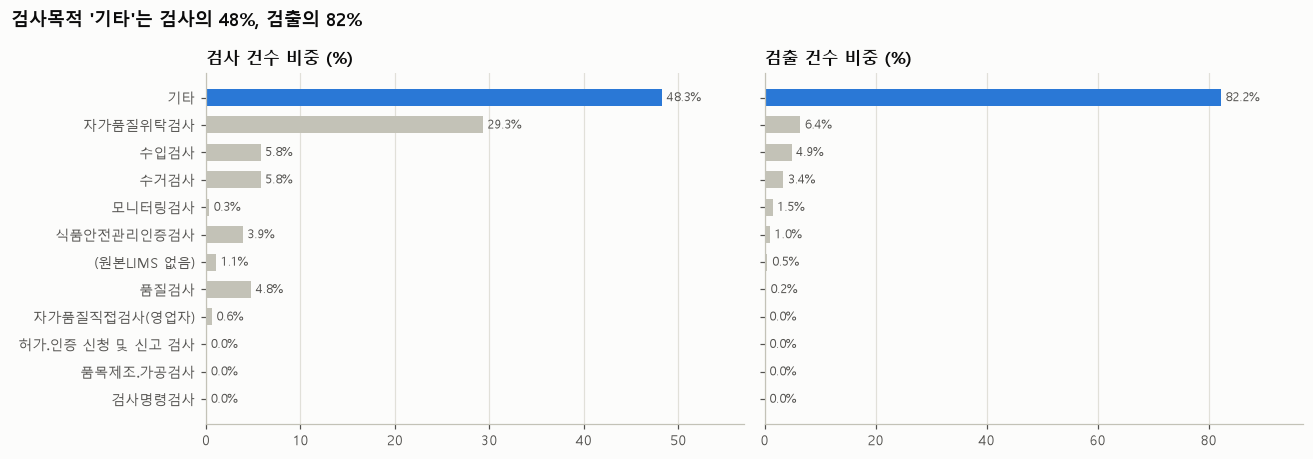

In [12]:
t = rate_by(dfx, '검사목적')
display(t)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
t2 = t.sort_values('검출', ascending=False)
lab = t2.index.tolist()
hi = [C1 if k == '기타' else GRAY for k in lab]
barh(axes[0], lab, (t2['건수'] / N * 100).round(1).tolist(), '검사 건수 비중 (%)', fmt='{:.1f}%', colors=hi)
barh(axes[1], lab, t2['검출비중(%)'].tolist(), '검출 건수 비중 (%)', fmt='{:.1f}%', colors=hi)
fig.suptitle("검사목적 '기타'는 검사의 48%, 검출의 82%", x=0.01, ha='left', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

In [13]:
# 검사목적별 프로필: 누가 의뢰했고, 기준일·주소가 무엇이며, 어떤 검체였나
prof = dfx.groupby('검사목적', observed=True).agg(
    건수=('pos', 'size'), 검출=('pos', 'sum'),
    국내비율=('국내해외', lambda s: (s == '국내').mean() * 100),
    자체의뢰비율=('의뢰시스템', lambda s: (s == '자체의뢰').mean() * 100),
    통합망비율=('의뢰시스템', lambda s: (s == '통합망').mean() * 100),
    제조일기준비율=('date_basis', lambda s: (s == '제조일').mean() * 100),
    업소주소비율=('addr_source', lambda s: (s == '업소주소').mean() * 100),
    공정_환경_팽이비율=('검체성격', lambda s: s.isin(['공정시료', '환경검체', '팽이버섯']).mean() * 100),
).round(1).sort_values('검출', ascending=False)
top_inst = (dfx.groupby(['검사목적', 'inspct_instt_code'], observed=True).size().rename('n').reset_index()
            .sort_values('n', ascending=False).drop_duplicates('검사목적').set_index('검사목적'))
prof['최다 검사기관'] = top_inst['inspct_instt_code'].astype(str) + ' (' + (top_inst['n'] / prof['건수'] * 100).round(0).astype(int).astype(str) + '%)'
prof.columns = [c.replace('비율', '(%)') for c in prof.columns]
prof

,건수,검출,국내(%),자체의뢰(%),통합망(%),제조일기준(%),업소주소(%),공정_환경_팽이(%),최다 검사기관
검사목적,,,,,,,,,
기타,326892,1619,100.0,99.9,0.1,24.8,74.1,37.1,O000392 (16%)
자가품질위탁검사,198217,127,100.0,98.9,1.1,82.3,16.0,0.7,O000026 (7%)
수입검사,39478,96,0.0,0.0,0.0,0.0,0.0,0.1,1471124 (46%)
수거검사,39501,66,100.0,17.1,82.9,36.8,14.7,0.8,O000101 (8%)
모니터링검사,1870,29,59.3,59.3,0.1,2.7,56.5,2.4,O000696 (24%)
식품안전관리인증검사,26426,19,100.0,100.0,0.0,20.3,9.4,49.1,O000858 (73%)
(원본LIMS 없음),7203,10,0.0,0.0,0.0,0.0,0.0,0.1,1471124 (54%)
품질검사,32608,3,100.0,100.0,0.0,84.6,27.1,4.9,O000216 (7%)
검사명령검사,2,0,0.0,100.0,0.0,100.0,0.0,0.0,O000078 (100%)


In [14]:
# 검사목적 × 검체성격 — '기타' 안에 무엇이 있나
rate_by(dfx[dfx['검사목적'].isin(['기타', '자가품질위탁검사', '수거검사', '수입검사', '식품안전관리인증검사'])],
        ['검사목적', '검체성격'], sort='index')

건수   검출  검출률(%)  검출비중(%)    리프트
검사목적       검체성격                                       
기타         공정시료    110152  240   0.218     12.5   0.71
           완제품표기    14370  117   0.814      6.1   2.66
           일반 제품명  191216  735   0.384     38.1   1.26
           팽이버섯      6351  433   6.818     22.5  22.31
           환경검체      4803   94   1.957      4.9   6.40
수거검사       공정시료       193    0   0.000      0.0   0.00
           일반 제품명   39184   63   0.161      3.3   0.53
           팽이버섯        19    3  15.789      0.2  51.66
           환경검체       105    0   0.000      0.0   0.00
수입검사       공정시료        22    0   0.000      0.0   0.00
           일반 제품명   39456   96   0.243      5.0   0.80
식품안전관리인증검사 공정시료     12902    5   0.039      0.3   0.13
           완제품표기     2008    1   0.050      0.1   0.16
           일반 제품명   11455   13   0.113      0.7   0.37
           팽이버섯         2    0   0.000      0.0   0.00
           환경검체        59    0   0.000      0.0   0.00
자가품질위탁검사   공정시료      1235    0   0.000      0.0   0.00
           완제품표기       55    0   0.000      0.0   0.00
           일반 제품명  196782  127   0.065      6.6   0.21
           팽이버섯        22    0   0.000      0.0   0.00
           환경검체       123    0   0.000      0.0   0.00

In [15]:
# 검사목적 × 연도: 건수와 검출 (기준일 연도)
n_y = dfx.pivot_table(index='검사목적', columns='year', values='pos', aggfunc='size', fill_value=0)
p_y = dfx.pivot_table(index='검사목적', columns='year', values='pos', aggfunc='sum', fill_value=0)
order = n_y.sum(axis=1).sort_values(ascending=False).index
print('[건수]'); display(n_y.loc[order])
print('[검출]'); display(p_y.loc[order])

[건수]


year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
검사목적,,,,,,,,,,,,
기타,7,537,14036,22469,25946,31608,36155,39069,41545,42221,46984,26315
자가품질위탁검사,17,4245,18474,18865,21630,21864,21133,20799,20696,20646,20066,9782
수거검사,0,109,2942,3718,4350,4682,3474,4308,4222,4123,4856,2717
수입검사,0,76,4272,3996,3989,4105,4281,4589,3910,4005,4475,1780
품질검사,0,599,3516,4242,4165,3204,3798,3762,3559,3711,2009,43
식품안전관리인증검사,0,0,0,0,8,245,535,487,2989,8604,8969,4589
(원본LIMS 없음),365,4661,387,228,332,101,197,79,110,267,251,225
자가품질직접검사(영업자),0,0,0,0,0,0,0,0,0,2,2210,2110
모니터링검사,0,1,245,196,330,205,0,312,0,0,451,130


[검출]


year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
검사목적,,,,,,,,,,,,
기타,0,2,26,62,109,369,214,193,188,140,236,80
자가품질위탁검사,0,3,15,27,13,13,20,6,8,10,9,3
수거검사,0,0,6,2,4,7,6,9,10,8,6,8
수입검사,0,0,14,2,3,1,8,5,6,17,29,11
품질검사,0,0,0,2,1,0,0,0,0,0,0,0
식품안전관리인증검사,0,0,0,0,0,4,0,0,3,7,2,3
(원본LIMS 없음),0,8,0,0,0,0,0,0,0,2,0,0
자가품질직접검사(영업자),0,0,0,0,0,0,0,0,0,0,0,0
모니터링검사,0,0,6,8,3,2,0,6,0,0,4,0


📊 **결과**
- 검출 1,969건 중 **검사목적 '기타' 1,619건(82.2%)**. 이어서 자가품질위탁검사 127건(6.4%), 수입검사 96건(4.9%), **수거검사 66건(3.4%)**, 모니터링검사 29건, 식품안전관리인증검사(HACCP) 19건.
- 공무원이 수거한 **수거검사는 39,501행(5.8%)** 이고, 이 중 83%가 통합망(지자체 시스템)으로 의뢰됐습니다.
- '기타' 326,892행은 **99.9% 자체의뢰**(업체가 직접 의뢰), 75%가 의뢰일 기준, 74%가 업소주소입니다. 검체 성격으로 보면 공정시료·환경검체·팽이버섯이 약 37%입니다.
- 자가품질위탁검사 198,217행의 검출률은 0.064% 로 전체(0.291%)의 약 1/5 입니다.
- '기타' 건수는 2017년 1.4만 → 2025년 4.7만으로 늘었고, 식품안전관리인증검사는 2023년부터 급증했습니다.

💬 **첨언**
- 이 데이터의 "검출"은 대부분 **정부 감시(수거·수입) 결과가 아니라, 업체가 스스로 맡긴 검사** 결과입니다. 업체가 맡기는 이유는 HACCP 공정 검증, 수출 증명, 거래처 요구, 제품 개발 등으로 추정됩니다. '기타'가 정확히 무엇인지는 코드명만으로는 알 수 없습니다.
- 검사목적마다 검출률이 크게 다릅니다. '기타' 0.495% 와 자가품질위탁검사 0.064% 는 약 8배 차이입니다. 품목·지역·기상보다 먼저 이 차이를 설명해야 모델이 "검사 정책"을 외우지 않습니다.
- 수거검사만 쓰면 양성이 66건이라 단독 모델은 어렵습니다. 반대로 전체를 쓰면 '기타'의 특수 검체(팽이버섯 수출검사, 공정시료)가 모델을 지배합니다 (3-3, 3-4, 9-2절).

✅ **결론** — 경로(검사목적)를 모르고는 검출률을 해석할 수 없습니다. `inspct_purps_code` 는 반드시 수집 변수에 넣고, 최소한 층화·분할 기준으로 써야 합니다.

🗄️ **모델팀께**: 검사목적 '기타'(IM02000007)는 LIMS 입력 화면에서 어떤 경우에 선택됩니까? 이 코드를 ready_data 에 올리지 않은 이유가 있습니까?

❓ **나박사님께**: 업체 자체의뢰 검사(자가품질·HACCP 검증·수출용·공정시료)와 공무원 수거검사를 한 모델에 섞어도 됩니까? 이 연구의 예측 대상은 둘 중 무엇입니까?

### 2-3. 누가 검사했나 — 검사기관

🔎 검사기관 코드에 원본 LIMS 의 기관명과 검사기관 정보 테이블(`m_sy_inspct_instt`)의 영문명을 붙여 유형을 나눕니다.
유형 구분은 이름으로 한 **추정**입니다 (147xxxx = 지방식약청, 이름에 보건환경연구원·동물위생시험소 등 = 지자체 시험기관, 그 외 = 민간·대학 시험기관).

In [16]:
nm_all = (instt['instt_nm'].fillna('') + ' ' + instt['instt_eng_nm'].fillna('')).str.strip()
GOV = r'보건환경연구원|동물위생시험소|축산위생연구소|축산진흥연구소|Health and Environment|Health & Environment|Public Health|Veterinary'
itype = np.where(instt['inspct_instt_code'].str.startswith('147'), '지방식약청',
                 np.where(nm_all.str.contains(GOV, regex=True), '지자체 시험기관', '민간·대학 시험기관(추정)'))
imap = pd.DataFrame({'기관명': instt['instt_nm'].fillna(instt['instt_eng_nm']).to_numpy(), '기관유형': itype},
                    index=instt['inspct_instt_code'].to_numpy())
dfx['기관명'] = dfx['inspct_instt_code'].astype(str).map(imap['기관명'])
dfx['기관유형'] = dfx['inspct_instt_code'].astype(str).map(imap['기관유형']).fillna('민간·대학 시험기관(추정)')
display(rate_by(dfx, '기관유형'))

ti = rate_by(dfx, 'inspct_instt_code', top=12)
ti.insert(0, '기관명', ti.index.astype(str).map(imap['기관명']))
ti.insert(1, '기관유형', ti.index.astype(str).map(imap['기관유형']))
main_purpose = dfx.groupby('inspct_instt_code', observed=True)['검사목적'].agg(lambda s: s.value_counts().index[0])
main_item = dfx[dfx['pos'] == 1].groupby('inspct_instt_code', observed=True)['train_prdlst_nm'].agg(lambda s: s.value_counts().index[0])
ti['주 검사목적'] = ti.index.map(main_purpose)
ti['검출 최다 품목'] = ti.index.map(main_item)
print(f"검출 상위 5개 기관의 검출 점유율: {ti['검출비중(%)'].head(5).sum():.1f}%  (기관 수 {dfx['inspct_instt_code'].nunique()})")
addr_pos = dfx.loc[dfx['pos'] == 1, 'addr'].value_counts()
print(f"검출이 나온 업소(주소) {addr_pos.size}곳 중 상위 10곳이 검출의 {addr_pos.head(10).sum() / P:.1%}, 상위 50곳이 {addr_pos.head(50).sum() / P:.1%}")
big = rate_by(dfx, 'inspct_instt_code', sort='n', top=3)
print('검사 건수 상위 3개 기관:', ' / '.join(f"{k} {imap['기관명'].get(str(k), '')}: {int(r['건수']):,}건 중 검출 {int(r['검출'])}건" for k, r in big.iterrows()))
ti

,건수,검출,검출률(%),검출비중(%),리프트
기관유형,,,,,
민간·대학 시험기관(추정),563934,1727,0.306,87.7,1.05
지방식약청,52968,136,0.257,6.9,0.88
지자체 시험기관,59635,106,0.178,5.4,0.61


검출 상위 5개 기관의 검출 점유율: 63.1%  (기관 수 270)
검출이 나온 업소(주소) 722곳 중 상위 10곳이 검출의 28.2%, 상위 50곳이 45.9%
검사 건수 상위 3개 기관: O000858 Humanbio Co., Ltd.: 65,811건 중 검출 1건 / O000392 Central Life Lab Co.,Ltd.: 59,286건 중 검출 49건 / O000473 Korea Bioanalysis Laboratory: 41,208건 중 검출 259건


,기관명,기관유형,건수,검출,검출률(%),검출비중(%),리프트,주 검사목적,검출 최다 품목
inspct_instt_code,,,,,,,,,
O000084,Intertek Testing Services Korea Ltd.,민간·대학 시험기관(추정),33380,674,2.019,34.2,6.94,기타,"정액,수정란,종란"
O000473,Korea Bioanalysis Laboratory,민간·대학 시험기관(추정),41208,259,0.629,13.2,2.16,기타,기타기준규격외
O000648,Food Institute Dasol,민간·대학 시험기관(추정),12566,141,1.122,7.2,3.86,기타,기타기준규격외
O000059,Suwon Women’s University Food Analysis Research Center,민간·대학 시험기관(추정),17703,91,0.514,4.6,1.77,기타,기타기준규격외
O000001,KOTITI Testing & Research Institute,민간·대학 시험기관(추정),23139,77,0.333,3.9,1.14,기타,기타기준규격외
O000728,"Jain Food Research Institute Co., Ltd",민간·대학 시험기관(추정),31505,72,0.229,3.7,0.79,기타,기타기준규격외
O000044,"Traditional Microorganism Resources Center, Keimyung University",민간·대학 시험기관(추정),5963,72,1.207,3.7,4.15,자가품질위탁검사,식육가공품 및 포장육
1471124,경인청,지방식약청,24588,65,0.264,3.3,0.91,수입검사,식육가공품 및 포장육
O000392,"Central Life Lab Co.,Ltd.",민간·대학 시험기관(추정),59286,49,0.083,2.5,0.28,기타,기타기준규격외


📊 **결과**
- 검출이 가장 많은 기관은 **O000084(Intertek Testing Services Korea)** 로 674건(검출의 34.2%), 검출률 2.0% 입니다. 검출 최다 품목은 '정액,수정란,종란'인데 실제로는 팽이버섯입니다 (3-3절).
- 검출 상위 5개 기관이 검출의 약 63%를 차지합니다. 상위 기관은 대부분 민간 시험기관입니다.
- 검사를 맡긴 업소 쪽도 집중돼 있습니다. 검출이 나온 업소 주소 722곳 중 상위 10곳이 검출의 28%, 상위 50곳이 46%입니다.
- 검사 건수가 가장 많은 O000858(Humanbio)은 65,811건 중 검출 1건입니다. 같은 민간 기관이라도 고객 업체와 검체에 따라 검출률이 크게 다릅니다.

💬 **첨언**
- 기관마다 **고객(업체)과 검체 종류가 다릅니다.** 기관 코드는 검출을 잘 가르겠지만, 그것은 "누가 검사했나"를 배운 것이지 오염 원인이 아닙니다. 예측 지도(시군구×품목)를 만들 때는 쓸 수 없는 변수입니다.
- 한 기관·한 업체에 검출이 몰려 있으므로, 검증 데이터는 **기관·업체·접수번호 단위로 묶어** 나눠야 성능이 부풀지 않습니다 (9-3절).

🗄️ **모델팀께**: 검사기관 코드표(기관명·기관유형: 지방청/보건환경연구원/민간 위탁기관)를 공식 자료로 받을 수 있습니까?

### 2-4. 한 행은 무엇인가 — `lims_data_key` 구조

🔎 키를 `_` 로 나눠 토큰 패턴을 보고, 같은 (검사기관, 접수번호) 아래 몇 행이 있는지 셉니다.

In [17]:
tok = dfx['lims_data_key'].str.split('_')
dfx['key_ntok'] = tok.str.len()
dfx['접수번호'] = tok.str[1]
pat = pd.crosstab(dfx['key_ntok'], dfx['국내해외'], margins=True, margins_name='합계')
pat.index.name = '토큰 수'
display(pat)
print('토큰1 == 검사기관코드:', (tok.str[0] == dfx['inspct_instt_code'].astype(str)).mean())

grp = dfx.groupby(['inspct_instt_code', '접수번호'], observed=True).agg(행수=('pos', 'size'), 검출=('pos', 'sum'),
                                                                  제품명수=('prduct_nm', 'nunique'))
print(f"접수 그룹 {len(grp):,}개 / 그룹당 평균 {grp['행수'].mean():.2f}행 / 1행짜리 그룹 {(grp['행수'] == 1).mean():.1%} / 최대 {grp['행수'].max()}행")
print(f"2행 이상 그룹 중 제품명이 모두 같은 그룹: {(grp.loc[grp['행수'] > 1, '제품명수'] == 1).mean():.1%}")
print(f"검출이 있는 그룹 {(grp['검출'] > 0).sum():,}개, 그 안의 검출 {grp.loc[grp['검출'] > 0, '검출'].sum():,}건")

국내해외,국내,해외,합계
토큰 수,,,
4,628895,40439,669334
5,0,7203,7203
합계,628895,47642,676537


토큰1 == 검사기관코드: 1.0
접수 그룹 356,682개 / 그룹당 평균 1.90행 / 1행짜리 그룹 71.6% / 최대 194행
2행 이상 그룹 중 제품명이 모두 같은 그룹: 0.6%
검출이 있는 그룹 1,305개, 그 안의 검출 1,969건


📊 **결과** — 키는 `검사기관코드_접수번호_시료순번_항목순번` 이고(4토큰), 5토큰은 2015\~2016년 구형 수입 포맷입니다.
한 접수번호에 서로 다른 제품·공정 단계 시료가 여러 행 딸려 옵니다.

💬 **첨언** — "한 행 = 한 시료"이고, n=5 검체는 행을 늘리지 않고 `result_value` 한 칸에 '음성,음성,음성,음성,음성'처럼 들어갑니다 (3-1절).
같은 접수번호의 시료들은 같은 날 같은 업체에서 온 것이라 서로 독립이 아닙니다. 학습/검증 분할은 **접수번호 단위** 이상으로 묶는 것이 안전합니다.

### 2-5. DataGrip 에 있는 데이터가 수집할 수 있는 전부인가 (메모 1)

🔎 먼저 parquet 가 DB 의 어느 부분인지 확인합니다.

In [18]:
only_db = attr[~attr['lims_data_key'].isin(df['lims_data_key'])]
print(f"DB 리스테리아 {len(attr):,}행 (검출 {(attr['judge_result_db'] == '검출').sum():,}) / parquet {len(df):,}행 (검출 {P:,})")
print(f"parquet 키가 모두 DB에 있음: {df['lims_data_key'].isin(attr['lims_data_key']).all()}")
print(f"DB 에만 있는 행 {len(only_db):,} (검출 {(only_db['judge_result_db'] == '검출').sum()})")
same = dfx[['date_basis']].astype(str).eq(attr.set_index('lims_data_key').loc[dfx['lims_data_key'], ['date_basis_db']].astype(str).values)
print('date_basis 일치율:', float(same.mean().iloc[0]))
only_db.groupby('addr_source_db').agg(행수=('lims_data_key', 'size'),
                                     검출=('judge_result_db', lambda s: int((s == '검출').sum()))).sort_values('행수', ascending=False)

DB 리스테리아 765,891행 (검출 2,062) / parquet 676,537행 (검출 1,969)
parquet 키가 모두 DB에 있음: True
DB 에만 있는 행 89,354 (검출 93)
date_basis 일치율: 1.0


,행수,검출
addr_source_db,,
검사기관,86696,91
제조사소재지,1473,0
해외제조업소,1142,2
업소주소,43,0


📊 **결과** — parquet 는 DB 리스테리아 765,891행에서 **89,354행(검출 93건)을 뺀 것**입니다. 빠진 행의 97%(86,696행)는 주소 출처가 '검사기관'(시험실 위치)인 행입니다.
나머지 2,658행은 추출 시점 이후 DB 가 갱신된 차이로 보입니다 (추정). parquet 에 있는 행은 판정·기준일·기준일 출처가 DB 와 100% 같습니다.

**수집 가능한 데이터의 층** (❓/🗄️ 는 10절 질문으로 연결)

| 층 | 무엇이 있나 | 리스테리아에 의미 있는 예 | 이 노트북에서 |
|---|---|---|---|
| ① parquet (23열) | ready_data 54열 중 일부 | 품목, 제품명, 기준일, 주소·좌표 | 전부 사용 |
| ② 같은 DB 의 다른 컬럼·테이블 (1-2절) | parquet 에 없는 ready_data 36열, 원본 LIMS 73열, 수입 LIMS 56열, 품목제조대장 37열, 영업허가대장 99열, 식품공전 분류 30열, 수분활성도 표(t_aw_cl), 정의서 밖 ba_data_info 의 원재료·제조/유통단계 조사·공통 기준규격 테이블 | **검사목적·검사종류**, 원본 제조일, 접수·검사완료일, **시료상태(냉장/냉동/실온)**, 유통기한 날짜, 수입 선적·입항일·검사종류·제조국, 보존·유통기준, 원료명·원산지 | 일부 추출해 사용 (`nb2_db_*`). ba_data_info 는 목록만 확인 |
| ③ DB 에 없고 리서치팀이 경로를 확보한 외부 자료 | 토양수분(깊이별·유역별), 해수 염분·해상풍, 지하수 오염도, CO2, 농업저수지 수질 등 | 원물 생산환경 (7-1절) | 미사용 |
| ④ 어디에도 없음 | 구조화된 원재료 입고일·수확일, 실제 저장·유통 온도 이력, 포장 방식(진공/MAP), 섭취형태(RTE 여부) 코드 | 오염 시점·증식 조건 | 대체 변수로만 가능 (6절) |

또 DB 에는 정의서에 없는 스키마(weather_data, predict_data, staging_*, train_data)도 있습니다. 사용 전에 모델팀 확인이 필요합니다.

✅ **결론** — DataGrip(DB)이 전부는 아닙니다. 다만 **지금 가장 부족한 정보(검사목적·시료상태·날짜)는 이미 같은 DB 안에** 있습니다. 외부 기상·토양보다 이쪽을 먼저 붙이는 것이 효과가 큽니다.

🗄️ **모델팀께**: parquet 를 만들 때 주소 출처가 '검사기관'인 행을 뺀 것이 의도된 규칙입니까? 그 86,696행(검출 91건)은 기상 결합에서만 빼고 품목·검사목적 분석에는 써도 됩니까?

---
## 3. 데이터 이해 ① — 무엇이 검출되나 (메모 P5, P6, 3, 4, 9, 10, 17, 18, 20, 21, 24)

### 3-1. 타깃과 결과값 형식

🔎 타깃 분포와 `result_value` 원문의 형식(검체 5개 나열인지, 값 1개인지)을 봅니다.

In [19]:
t = df['judge_result'].value_counts().to_frame('건수')
t['비율(%)'] = (t['건수'] / N * 100).round(3)
display(t)

rv = dfx['result_value'].astype('string').fillna('')
n_vals = rv.str.count(',') + 1
dfx['결과값형식'] = np.select([n_vals >= 5, n_vals == 1], ['값 5개 이상 나열 (n=5 검체)', '값 1개'], '값 2~4개')
display(rate_by(dfx, ['국내해외', '결과값형식'], sort='index'))
print('judge_stdr(판정 규격) 기재 행:', df['judge_stdr'].notna().sum(), '→ 상위 값')
print(df['judge_stdr'].value_counts().head(6).to_string())

,건수,비율(%)
judge_result,,
불검출,674568,99.709
검출,1969,0.291


건수    검출  검출률(%)  검출비중(%)   리프트
국내해외 결과값형식                                                   
국내   값 1개                 385063  1660   0.431     84.3  1.48
     값 2~4개                   67     1   1.493      0.1  5.13
     값 5개 이상 나열 (n=5 검체)  243765   183   0.075      9.3  0.26
해외   값 1개                   2128    25   1.175      1.3  4.04
     값 2~4개                    4     0   0.000      0.0  0.00
     값 5개 이상 나열 (n=5 검체)   45510   100   0.220      5.1  0.75

judge_stdr(판정 규격) 기재 행: 7273 → 상위 값
judge_stdr
n=5,c=0,m=0/25g       4692
n=5, c=0, m=0/25g     1817
음성                     635
100                     62
n=5, c=0, m=0/25 g      29
n=5,c=2,m=0             12


📊 **결과** — 검출 1,969건(0.291%). 결과값이 '값 5개 나열'(규격검사 n=5 형식)인 행은 검출률이 낮고, '값 1개'인 행이 검출률이 높습니다.

💬 **첨언** — 값 1개 형식은 자가·공정 검체에서 많고, 5개 나열은 규격검사 형식입니다 (추정). 결과값 형식 자체가 **검사 종류의 흔적**이라, 피처로 쓰면 누수에 가깝습니다. 타깃 정의 확인용으로만 씁니다.

❓ **나박사님께**: 결과가 '음성' 한 개로 적힌 행은 실제로 검체 1개(n=1)를 검사한 것입니까, 5개 검사를 요약해 적은 것입니까?

### 3-2. 품목(train_prdlst_nm)별 검출률 (메모 18, 24)

🔎 학습용 품목명 53개 전체의 건수·검출·검출률과, 검출이 1건 이상인 품목 수를 셉니다.

In [20]:
ti = rate_by(dfx, 'train_prdlst_nm')
print(f"검출이 1건 이상인 품목: {(ti['검출'] > 0).sum()}개 / 전체 {len(ti)}개")
print('검출 1건 이상 품목:', ', '.join(f'{k}({v})' for k, v in ti.loc[ti['검출'] > 0, '검출'].items()))
ti

검출이 1건 이상인 품목: 15개 / 전체 53개
검출 1건 이상 품목: 기타기준규격외(791), 정액,수정란,종란(640), 식육가공품 및 포장육(323), 수산물(46), 즉석식품류(45), 유가공품류(40), 수산가공식품류(29), 축산물(28), 버섯류(12), 기타식품류(9), 기타식물류(2), 음료류(1), 과자류, 빵류 또는 떡류(1), 농산가공식품류(1), 견과 종실류(1)


,건수,검출,검출률(%),검출비중(%),리프트
train_prdlst_nm,,,,,
기타기준규격외,291813,791,0.271,40.2,0.93
"정액,수정란,종란",28651,640,2.234,32.5,7.68
식육가공품 및 포장육,101045,323,0.320,16.4,1.10
수산물,8473,46,0.543,2.3,1.87
즉석식품류,35322,45,0.127,2.3,0.44
유가공품류,107022,40,0.037,2.0,0.13
수산가공식품류,4915,29,0.590,1.5,2.03
축산물,1731,28,1.618,1.4,5.56
버섯류,92,12,13.043,0.6,44.82


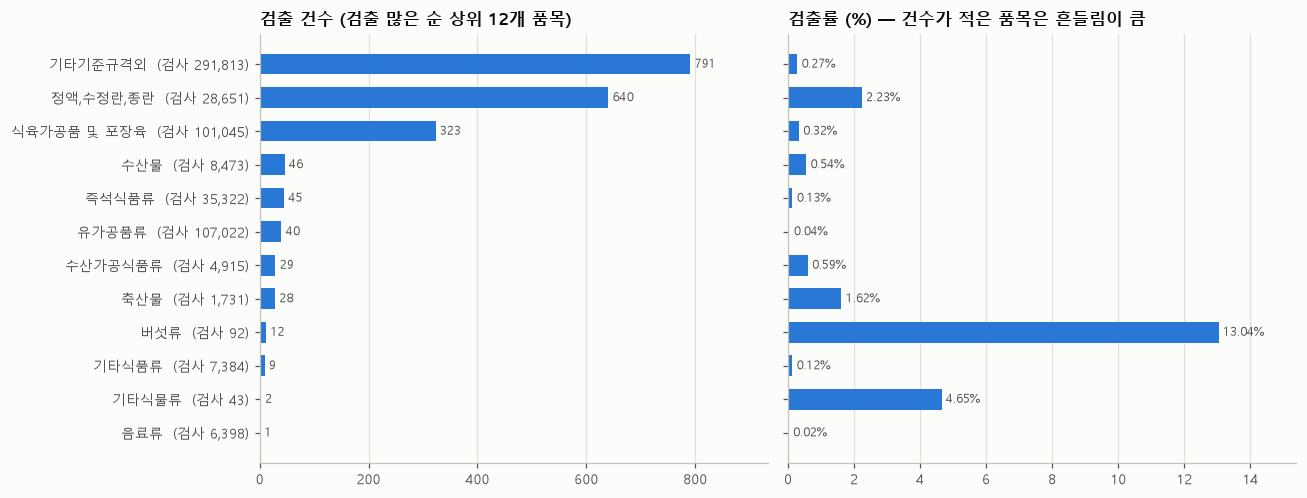

In [21]:
top = ti[ti['검출'] > 0].head(12)
lab = [f'{k}  (검사 {n:,})' for k, n in zip(top.index, top['건수'])]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
barh(axes[0], lab, top['검출'].tolist(), '검출 건수 (검출 많은 순 상위 12개 품목)')
barh(axes[1], lab, top['검출률(%)'].tolist(), '검출률 (%) — 건수가 적은 품목은 흔들림이 큼', fmt='{:.2f}%')
plt.tight_layout()
plt.show()

📊 **결과**
- 검출 상위는 **기타기준규격외 791건, 정액,수정란,종란 640건, 식육가공품 및 포장육 323건** 이고, 이 셋이 검출의 89%입니다.
- 검출률은 버섯류(92건 중 12건, 13%), 정액,수정란,종란(2.2%), 축산물(1.6%), 수산가공식품류·수산물(0.5\~0.6%) 순으로 높습니다.
- 유가공품류(107,022건 중 40건, 0.037%), 알가공품류(29,392건 중 0건), 빙과류(22,206건 중 0건)는 매우 낮습니다.
- 메모 24의 "양성인 품목 14개"와 달리 **검출이 1건 이상인 품목은 15개**입니다. 이 중 4개(음료류·과자빵떡류·농산가공식품류·견과 종실류)는 검출이 1건뿐이라, 데이터 시점이나 필터가 조금만 달라도 개수가 바뀝니다.

💬 **첨언** — 검출이 많은 두 품목('기타기준규격외', '정액,수정란,종란')은 이름만 봐서는 무엇인지 알 수 없습니다. 3-3절에서 실제 제품명을 봅니다.

### 3-3. 수상한 두 품목 — '기타기준규격외'와 '정액,수정란,종란'의 실제 제품명

🔎 두 품목 안에서 가장 많이 나온 제품명과, 검출된 제품명을 나란히 봅니다.

In [22]:
def top_names(sub, k=15):
    a = sub['prduct_nm'].value_counts().head(k)
    b = sub.loc[sub['pos'] == 1, 'prduct_nm'].value_counts().head(k)
    n = max(len(a), len(b))
    pad = lambda s: [f'{i} ({v:,})' for i, v in s.items()] + [''] * (n - len(s))
    return pd.DataFrame({'전체 상위 제품명 (건수)': pad(a), '검출 상위 제품명 (검출 수)': pad(b)})

for name in ['기타기준규격외', '정액,수정란,종란']:
    sub = dfx[dfx['train_prdlst_nm'] == name]
    print(f"\n■ {name}: {len(sub):,}행, 검출 {sub['pos'].sum()}건, 원본 품목코드 {sub['prdlst_code'].astype(str).value_counts().head(2).to_dict()}")
    display(top_names(sub))


■ 기타기준규격외: 291,813행, 검출 791건, 원본 품목코드 {'Z3800100000000': 291813}


,전체 상위 제품명 (건수),검출 상위 제품명 (검출 수)
0,완제품 (479),광어회 (10)
1,원료육 (407),연어회 (9)
2,배추(세척전) (210),연어필렛 (6)
3,배추(세척후) (203),포장육 완제품 (5)
4,양파 (183),팽이버섯 (4)
5,절임배추 (165),연어(캐나다산) (4)
6,대파 (165),홍새우회 (4)
7,무(세척전) (158),가마로순살강정육 1차 (3)
8,무(세척후) (155),완제품1 (3)
9,배추-세척전 (153),클린콜 (3)



■ 정액,수정란,종란: 28,651행, 검출 640건, 원본 품목코드 {'Z2700400000000': 28651}


,전체 상위 제품명 (건수),검출 상위 제품명 (검출 수)
0,수출용 팽이버섯 (2-1번) (101),ENOKI MUSHROOM GR5-3 (6)
1,수출용 팽이버섯 (2-2번) (101),수출용 팽이버섯 (2번) (6)
2,수출용 팽이버섯 (2번) (100),ENOKI MUSHROOM GR4-1 (6)
3,수출용 팽이버섯 (1번) (100),수출용 팽이버섯 (3번) (6)
4,수출용 팽이버섯 (3-2번) (96),ENOKI MUSHROOM GR4-2 (6)
5,수출용 팽이버섯 (3-1번) (96),ENOKI MUSHROOM GR1-3 (5)
6,ENOKI MUSHROOM (67),수출용 팽이버섯 (7번) (5)
7,권지 (48),ENOKI MUSHROOM GR4-3 (5)
8,포장실 바닥 (46),수출용 팽이버섯 (2-2번) (5)
9,건조 크랜베리 글리세린 (45),ENOKI MUSHROOM GR6-1 (5)


📊 **결과**
- **'정액,수정란,종란'(원본 코드 Z2700400000000)** 의 실제 제품명은 '수출용 팽이버섯 (2-1번)', 'ENOKI MUSHROOM', '권지', '포장실 바닥', '수확실 벽체' 같은 **수출용 팽이버섯과 재배장 환경검체**입니다. 가축 정액·수정란과는 관계가 없습니다.
- **'기타기준규격외'(Z3800100000000)** 의 상위 제품명은 '완제품', '원료육', '배추(세척전)', '배추(세척후)', '절임배추', '가열전', '가열후' 같은 **HACCP 공정 단계 시료**입니다. 검출 제품명은 광어회·연어회·연어필렛 같은 횟감과 식육이 많습니다.

💬 **첨언** — 센터 발표자료의 식품 분류표(13쪽)를 보면 1단계 '기준규격외' 아래에 정액·수정란·종란, 종자, 환경검체 등이 함께 있습니다. 품목코드가 잡히지 않는 검체를 이 코드에 넣은 것으로 보입니다 (추정). **검출의 72.7%가 이 두 코드에** 있으므로, 이 코드를 그대로 "식품 유형" 피처로 쓰면 모델이 식품 특성이 아닌 검체 관행을 배웁니다.

🗄️ **모델팀께**: Z2700400000000 을 '정액,수정란,종란'으로 매핑한 근거와, 팽이버섯·환경검체가 이 코드로 들어온 이유를 확인해 주세요.

❓ **나박사님께**: HACCP 공정시료(세척 전후·가열 전후·원료육)와 작업장 환경검체(바닥·장갑·컨베이어)를 예측 대상에서 빼야 합니까, 아니면 "공장 환경 오염 신호"로 따로 활용할 가치가 있습니까?

### 3-4. 제품명으로 본 검체 성격

🔎 1장에서 만든 `검체성격`(정규식 휴리스틱)으로 공정시료·환경검체·팽이버섯의 규모와 검출률을 봅니다. 휴리스틱이라 오탐·누락이 있습니다.

In [23]:
display(rate_by(dfx, '검체성격'))
rate_by(dfx, ['train_prdlst_nm', '검체성격'], top=20)

,건수,검출,검출률(%),검출비중(%),리프트
검체성격,,,,,
일반 제품명,522371,1066,0.204,54.1,0.70
팽이버섯,6433,445,6.917,22.6,23.77
공정시료,126079,246,0.195,12.5,0.67
완제품표기,16499,118,0.715,6.0,2.46
환경검체,5155,94,1.823,4.8,6.27


건수   검출  검출률(%)  검출비중(%)    리프트
train_prdlst_nm 검체성격                                       
기타기준규격외         일반 제품명  163774  475   0.290     24.1   1.00
정액,수정란,종란       팽이버섯      5722  415   7.253     21.1  24.92
식육가공품 및 포장육     일반 제품명  100010  302   0.302     15.3   1.04
기타기준규격외         공정시료    111150  198   0.178     10.1   0.61
                완제품표기    14916  100   0.670      5.1   2.30
정액,수정란,종란       환경검체      3595   94   2.615      4.8   8.98
                일반 제품명   14650   92   0.628      4.7   2.16
수산물             일반 제품명    8283   46   0.555      2.3   1.91
즉석식품류           일반 제품명   35119   45   0.128      2.3   0.44
유가공품류           일반 제품명  106735   39   0.037      2.0   0.13
정액,수정란,종란       공정시료      4347   29   0.667      1.5   2.29
수산가공식품류         일반 제품명    3927   26   0.662      1.3   2.27
축산물             일반 제품명    1300   26   2.000      1.3   6.87
기타기준규격외         팽이버섯       629   18   2.862      0.9   9.83
식육가공품 및 포장육     공정시료       712   13   1.826      0.7   6.27
버섯류             팽이버섯        48   12  25.000      0.6  85.90
정액,수정란,종란       완제품표기      337   10   2.967      0.5  10.20
기타식품류           일반 제품명    6865    9   0.131      0.5   0.45
식육가공품 및 포장육     완제품표기      307    8   2.606      0.4   8.95
수산가공식품류         공정시료       604    3   0.497      0.2   1.71

📊 **결과** — 팽이버섯은 6,433행에서 445건(6.9%)이 검출돼 검출률이 가장 높고, 환경검체도 5,155행에서 94건(1.8%)으로 평균의 6배입니다. 공정시료는 12.6만 행으로 많고 검출률(0.195%)은 평균보다 조금 낮습니다.

✅ **결론** — 검출의 상당 부분이 "소비자가 사 먹는 완제품"이 아니라 재배·제조 현장 검체에서 나옵니다. 모델 대상 범위를 정할 때 이 층을 먼저 분리해야 합니다 (9-2절).

### 3-5. 식품공전 상위 분류가 있나 (메모 20)

🔎 품목코드 첫 글자와, DB ready_data 의 통계용 분류 `statistic_prdlst_nm_1~2` 를 대조합니다.

In [24]:
dfx['코드첫글자'] = dfx['prdlst_code'].astype(str).str[0]
display(pd.crosstab(dfx['코드첫글자'], dfx['statistic_prdlst_nm_1'], margins=True, margins_name='합계'))
display(rate_by(dfx, 'statistic_prdlst_nm_1'))
rate_by(dfx, ['statistic_prdlst_nm_1', 'statistic_prdlst_nm_2'], top=20)

statistic_prdlst_nm_1,가공식품,건강기능식품,기준규격외,기타,동물성,식물성,식품접객업소,첨가물,합계
코드첫글자,,,,,,,,,
A,0,0,0,26,0,2098,0,0,2124
B,0,0,0,0,10201,0,0,0,10201
C,332931,0,0,139,0,0,0,0,333070
D,0,0,0,0,0,0,0,139,139
E,0,443,0,5,0,0,0,0,448
G,0,0,0,0,0,0,9640,0,9640
X,345,3,0,0,3,0,14,0,365
Z,0,0,320550,0,0,0,0,0,320550
합계,333276,446,320550,170,10204,2098,9654,139,676537


,건수,검출,검출률(%),검출비중(%),리프트
statistic_prdlst_nm_1,,,,,
기준규격외,320550,1431,0.446,72.7,1.53
가공식품,333276,449,0.135,22.8,0.46
동물성,10204,74,0.725,3.8,2.49
식물성,2098,15,0.715,0.8,2.46
식품접객업소,9654,0,0.000,0.0,0.00
건강기능식품,446,0,0.000,0.0,0.00
기타,170,0,0.000,0.0,0.00
첨가물,139,0,0.000,0.0,0.00


건수   검출  검출률(%)  검출비중(%)    리프트
statistic_prdlst_nm_1 statistic_prdlst_nm_2                                     
기준규격외                 기타기준규격외                291813  791   0.271     40.2   0.93
                      정액,수정란,종란               28651  640   2.234     32.5   7.68
가공식품                  가공식품(전부개정)             332934  449   0.135     22.8   0.46
동물성                   수산물                      8473   46   0.543      2.3   1.87
                      축산물                      1731   28   1.618      1.4   5.56
식물성                   버섯류                        92   12  13.043      0.6  44.82
                      기타식물류                      43    2   4.651      0.1  15.98
                      견과 종실류                    292    1   0.342      0.1   1.18
식품접객업소                조리식품 등                   9590    0   0.000      0.0   0.00
식물성                   채소류                       904    0   0.000      0.0   0.00
                      과일류                       702    0   0.000      0.0   0.00
가공식품                  기타제조가공식품류(자가규격)           342    0   0.000      0.0   0.00
건강기능식품                기능성 원료                    271    0   0.000      0.0   0.00
기타                    기타                        170    0   0.000      0.0   0.00
건강기능식품                개별인정원료                    163    0   0.000      0.0   0.00
첨가물                   식품첨가물                      70    0   0.000      0.0   0.00
                      혼합제제류                      68    0   0.000      0.0   0.00
식물성                   곡류                         52    0   0.000      0.0   0.00
식품접객업소                접객용 음용수                    50    0   0.000      0.0   0.00
기준규격외                 수산가공                       40    0   0.000      0.0   0.00

📊 **결과** — 상위 분류가 있습니다. 코드 첫 글자가 곧 1단계 분류입니다.

| 첫 글자 | 1단계 분류 | 검출 |
|---|---|---|
| A | 식물성(농산물 원물) | 15 |
| B | 동물성(축산물·수산물 원물) | 74 |
| C | 가공식품 | 449 |
| Z | 기준규격외 (공정·환경검체·팽이버섯 수출검사 등) | 1,431 |
| G / E / D | 식품접객업소 / 건강기능식품 / 첨가물 | 0 |

💬 **첨언** — 식품공전 체계는 대분류 → 중분류 → 식품유형으로 내려가고, 2단계 이하 이름은 `statistic_prdlst_nm_2~4` 와 `ba_data.t_prdlst_cl`(상위코드 `hrnk_prdlst_cd`)에서 더 풀 수 있습니다. parquet 의 `train_prdlst_nm` 은 "가공식품은 3단계, 나머지는 2단계" 규칙으로 만든 이름입니다 (센터 발표자료 13쪽).

### 3-6. 국내/해외 × 농·축·수산물·가공식품 8분할 (메모 9, 21, 24)

🔎 메모대로 **국내/해외 × {농산물, 축산물, 수산물, 가공식품}** 8칸으로 나누되, 어디에도 안 들어가는 '기준규격외'와 '기타'는 따로 둡니다.
분류는 DB 의 식품공전 1·2단계 이름을 그대로 썼습니다 (원물 = A·B 코드).

In [25]:
s1, s2 = dfx['statistic_prdlst_nm_1'].astype(str), dfx['statistic_prdlst_nm_2'].astype(str)
dfx['대분류'] = np.select(
    [s1.eq('식물성'), s1.eq('동물성') & s2.eq('축산물'), s1.eq('동물성') & s2.eq('수산물'), s1.eq('가공식품'), s1.eq('기준규격외')],
    ['농산물(원물)', '축산물(원물)', '수산물(원물)', '가공식품', '기준규격외(검체)'], '기타(접객·건기식·첨가물)')

g = dfx.groupby(['대분류', '국내해외'], observed=True)['pos'].agg(건수='size', 검출='sum')
g['검출률(%)'] = (g['검출'] / g['건수'] * 100).round(3)
cell = (g['검출'].map('{:,}'.format) + ' / ' + g['건수'].map('{:,}'.format) + '  (' + g['검출률(%)'].map('{:.3f}%'.format) + ')').unstack()
order = ['농산물(원물)', '축산물(원물)', '수산물(원물)', '가공식품', '기준규격외(검체)', '기타(접객·건기식·첨가물)']
print('칸 = 검출 / 건수 (검출률)')
display(cell.reindex(order).fillna('-'))

# 가공식품만 원료 기준으로 한 번 더 (규칙은 추정 — 복합 원료 식품은 '그 외'로 둠)
GA = {'식육가공품 및 포장육': '축산가공(식육)', '유가공품류': '축산가공(유)', '알가공품류': '축산가공(알)',
      '수산가공식품류': '수산가공', '즉석식품류': '즉석식품', '빙과류': '빙과', '음료류': '음료'}
gg = dfx[dfx['대분류'] == '가공식품'].assign(가공세분=lambda d: d['train_prdlst_nm'].astype(str).map(GA).fillna('그 외 가공(농산·복합)'))
rate_by(gg, ['국내해외', '가공세분'], sort='index')

칸 = 검출 / 건수 (검출률)


국내해외,국내,해외
대분류,,
농산물(원물),"15 / 2,098 (0.715%)",-
축산물(원물),9 / 966 (0.932%),19 / 765 (2.484%)
수산물(원물),3 / 469 (0.640%),"43 / 8,004 (0.537%)"
가공식품,"386 / 294,421 (0.131%)","63 / 38,855 (0.162%)"
기준규격외(검체),"1,431 / 320,536 (0.446%)",0 / 14 (0.000%)
기타(접객·건기식·첨가물),"0 / 10,405 (0.000%)",0 / 4 (0.000%)


건수   검출  검출률(%)  검출비중(%)   리프트
국내해외 가공세분                                            
국내   그 외 가공(농산·복합)  26394   11   0.042      2.4  0.31
     빙과             19816    0   0.000      0.0  0.00
     수산가공            4637   29   0.625      6.5  4.64
     음료              6279    1   0.016      0.2  0.12
     즉석식품           35322   45   0.127     10.0  0.95
     축산가공(식육)       95216  294   0.309     65.5  2.29
     축산가공(알)        28465    0   0.000      0.0  0.00
     축산가공(유)        78292    6   0.008      1.3  0.06
해외   그 외 가공(농산·복합)    582    0   0.000      0.0  0.00
     빙과              2390    0   0.000      0.0  0.00
     수산가공             278    0   0.000      0.0  0.00
     음료               119    0   0.000      0.0  0.00
     축산가공(식육)        5829   29   0.498      6.5  3.69
     축산가공(알)          927    0   0.000      0.0  0.00
     축산가공(유)        28730   34   0.118      7.6  0.88

📊 **결과**
- **품목코드 기준 원물(농·축·수산물) 행은 전체의 1.8%** 뿐입니다. 해외 수산물(냉동 다랑어·황새치 횟감 등)과 해외 축산물(수입 식육)이 원물 검출의 대부분입니다.
- 국내 원물은 농산물·축산물·수산물 코드를 합쳐도 검출이 27건입니다. 이것은 **품목코드 기준**이고, 제품명으로 다시 세면 크게 늘어납니다 (3-6-2절).
- 가공식품(C 코드)의 검출은 **국내 식육가공품(294건)** 에 몰려 있습니다. 국내 유가공·알가공·빙과는 거의 0이고, 해외 유가공(수입 치즈 34건)과 해외 식육가공(생햄 등 29건)이 예외입니다.
- 가장 큰 칸은 '기준규격외(검체)'로, 국내 검출의 대부분이 여기 있습니다.

💬 **첨언** — 메모의 8분할은 **기준규격외(검체) 층을 따로 떼어야** 의미가 생깁니다. 그렇지 않으면 "국내 가공식품" 칸의 해석이 공정시료·팽이버섯에 흔들립니다.
또 **"국내 원물에만 기후를 붙인다"**(나박사님께 드리려던 질문 1)는 방향은 도메인상 맞지만, 원물 코드 칸만 보면 양성이 너무 적습니다. 칸 안의 품목별 양성률은 바로 아래 3-6-1절에서 보고, 기준규격외 코드 안에 숨은 원물 검체는 3-6-2절에서 다시 셉니다.

#### 3-6-1. 8칸 안의 품목별 양성률

🔎 위 표는 칸 합계입니다. 여기서는 칸 안에서 **어떤 품목**이 양성률을 끌어올리는지 봅니다.
- **품목** = DB ready_data 의 `prdlst_nm`(식품공전 품목명) 값 그대로입니다. 이름을 합치거나 고치지 않았습니다.
- 다만 같은 품목명이 **여러 품목코드**에 걸쳐 있습니다 (14자리/20자리 표기, 코드 체계 차이). 품목명 기준으로 세면 이 코드들이 한 줄로 합산되므로, 표에 `코드 수`와 3단계 분류를 붙이고 ③에서 코드별로 풀어 봤습니다.
- 칸 분류는 3-6절과 같습니다. 기준규격외·접객업소·건강기능식품·첨가물 행은 8칸 밖이라 이 절에서 다루지 않습니다.
- 양성률 옆에 **95% 신뢰구간(Wilson)** 을 붙였습니다. 건수가 적은 품목은 구간이 넓어 순위를 그대로 믿기 어렵습니다.
- 기준 행은 parquet 입니다. parquet 가 DB 에서 뺀 행(주로 주소 출처 '검사기관')이 칸마다 얼마나 되는지 ①의 `DB 전체` 열로 같이 봅니다.

In [26]:
# [3-6-1] ① 8칸 요약 — 칸마다 품목명·코드 수, 검출 상위 품목, parquet 와 DB 전체 비교
dfx['품목명'] = dfx['lims_data_key'].map(attr.set_index('lims_data_key')['prdlst_nm_self'])   # ready_data.prdlst_nm, 값 그대로
CATS8 = ['농산물(원물)', '축산물(원물)', '수산물(원물)', '가공식품']


def wilson(k, n, z=1.96):
    # 양성률의 95% 신뢰구간(Wilson), 단위 %. 검출 0건이어도 상한이 나오고, 건수가 적을수록 넓어진다.
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    p = k / n
    den = 1 + z ** 2 / n
    mid = (p + z ** 2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return np.clip(mid - half, 0, 1) * 100, np.clip(mid + half, 0, 1) * 100


# DB 전체(ready_data 리스테리아 행)에도 3-6절과 같은 규칙으로 칸을 붙인다
a1, a2 = attr['statistic_prdlst_nm_1'].astype(str), attr['statistic_prdlst_nm_2'].astype(str)
db8 = pd.DataFrame({
    '국내해외': attr['geo_route'].astype(str).map({'domestic': '국내', 'overseas': '해외'}),
    '대분류': np.select([a1.eq('식물성'), a1.eq('동물성') & a2.eq('축산물'), a1.eq('동물성') & a2.eq('수산물'), a1.eq('가공식품')],
                     CATS8, '8칸 밖'),
    'pos': attr['judge_result_db'].astype(str).eq('검출').astype(int)})
db_g = db8.groupby(['국내해외', '대분류'])['pos'].agg(['size', 'sum'])

rows = []
for side in ['국내', '해외']:
    for cat in CATS8:
        d = dfx[dfx['국내해외'].eq(side) & dfx['대분류'].eq(cat)]
        n, k = len(d), int(d['pos'].sum())
        by = d.groupby('품목명')['pos'].agg(['size', 'sum'])
        top = by[by['sum'] > 0].sort_values(['sum', 'size'], ascending=False).head(3)
        lo, hi = wilson(k, n) if n else (np.nan, np.nan)
        dbn, dbk = (int(db_g.loc[(side, cat), 'size']), int(db_g.loc[(side, cat), 'sum'])) if (side, cat) in db_g.index else (0, 0)
        rows.append({'국내해외': side, '대분류': cat, '건수': n, '검출': k,
                     '양성률(%)': round(k / n * 100, 3) if n else np.nan,
                     '95% CI(%)': f'{lo:.2f}–{hi:.2f}' if n else '-',
                     '품목명 수': len(by), '품목코드 수': d['prdlst_code'].astype(str).nunique(), '검출 품목명 수': int((by['sum'] > 0).sum()),
                     '검출 상위 품목 (검출/건수)': ', '.join(f"{i}({int(r['sum'])}/{int(r['size']):,})" for i, r in top.iterrows()),
                     'DB 전체 건수': dbn, 'DB 전체 검출': dbk, 'DB 전체 양성률(%)': round(dbk / dbn * 100, 3) if dbn else np.nan})
summary8 = pd.DataFrame(rows).set_index(['국내해외', '대분류'])
out8 = dfx[~dfx['대분류'].isin(CATS8)]
print(f"8칸 밖(기준규격외·접객업소·건기식·첨가물): parquet {len(out8):,}행, 검출 {int(out8['pos'].sum()):,}건 — 3-3절·3-6-2절에서 봄")
print('수입 LIMS 리스테리아 행의 품목코드 첫 글자:', ', '.join(f'{k} {v:,}' for k, v in sorg['prdlst_cd'].astype(str).str[0].value_counts().items()))
summary8

8칸 밖(기준규격외·접객업소·건기식·첨가물): parquet 330,959행, 검출 1,431건 — 3-3절·3-6-2절에서 봄
수입 LIMS 리스테리아 행의 품목코드 첫 글자: C 39,615, B 13,557, E 4


건수   검출  양성률(%)  95% CI(%)  품목명 수  품목코드 수  검출 품목명 수                                   검출 상위 품목 (검출/건수)  DB 전체 건수  DB 전체 검출  DB 전체 양성률(%)
국내해외 대분류                                                                                                                                                  
국내   농산물(원물)    2098   15   0.715  0.43–1.18    168     168         3                    팽이버섯(12/48), 엄나무(2/32), 밤(1/48)      3155        16         0.507
     축산물(원물)     966    9   0.932  0.49–1.76     22      22         4                  소고기(6/430), 돼지고기(1/234), 소유(1/91)      1757        12         0.683
     수산물(원물)     469    3   0.640  0.22–1.86     66      66         3              기타수산물(1/128), 새우냉동(1/98), 눈다랑어냉동(1/5)      4334         5         0.115
     가공식품     294421  386   0.131  0.12–0.14    331     485        32  포장육(101/2,668), 양념육(87/21,956), 즉석섭취식품(40/37,337)    333851       433         0.130
해외   농산물(원물)       0    0     NaN          -      0       0         0                                                            0         0           NaN
     축산물(원물)     765   19   2.484  1.60–3.85      9      16         5                소고기(9/165), 돼지고기(7/237), 닭고기(1/190)       767        19         2.477
     수산물(원물)    8004   43   0.537  0.40–0.72     43     322        10          해양어류(8/1,702), 참다랑어(8/1,480), 눈다랑어(8/683)      9144        43         0.470
     가공식품      38855   63   0.162  0.13–0.21    115     250         9           치즈(17/4,296), 생햄(12/816), 연성치즈(10/1,224)     38979        65         0.167

In [27]:
# [3-6-1] ② 대분류별 품목 표 — 국내/해외 나란히. 검출 1건 이상 품목은 전부 표로, 검출 0 품목은 건수 많은 순으로 이름만
def item_table(cat):
    d = dfx[dfx['대분류'].eq(cat)]
    info = d.groupby('품목명').agg(**{'3단계 분류': ('statistic_prdlst_nm_3', lambda s: ' / '.join(sorted(s.astype(str).unique()))),
                                   '코드 수': ('prdlst_code', lambda s: s.astype(str).nunique())})
    g = d.groupby(['품목명', '국내해외'], observed=True)['pos'].agg(건수='size', 검출='sum')
    lo, hi = wilson(g['검출'], g['건수'])
    g['양성률(%)'] = (g['검출'] / g['건수'] * 100).round(3)
    g['95% CI(%)'] = [f'{a:.2f}–{b:.2f}' for a, b in zip(lo, hi)]
    w = g.unstack('국내해외')
    w.columns = w.columns.swaplevel(0, 1)
    sides = [s for s in ['국내', '해외'] if s in w.columns.get_level_values(0)]
    w = w.reindex(columns=pd.MultiIndex.from_product([sides, ['건수', '검출', '양성률(%)', '95% CI(%)']]))
    tot = pd.DataFrame({'k': w.xs('검출', axis=1, level=1).sum(axis=1), 'n': w.xs('건수', axis=1, level=1).sum(axis=1)})
    tot = tot.sort_values(['k', 'n'], ascending=False)
    for s in sides:
        for c in ['건수', '검출']:
            w[(s, c)] = w[(s, c)].map(lambda v: f'{int(v):,}' if pd.notna(v) else '-')
        w[(s, '양성률(%)')] = w[(s, '양성률(%)')].map(lambda v: f'{v:.3f}' if pd.notna(v) else '-')
        w[(s, '95% CI(%)')] = w[(s, '95% CI(%)')].fillna('-')
    info.columns = pd.MultiIndex.from_product([['품목'], info.columns])
    return info.join(w).loc[tot.index], tot


for cat in CATS8:
    w, tot = item_table(cat)
    pos_idx = tot.index[tot['k'] > 0]
    zero = tot.loc[tot['k'] == 0, 'n']
    print(f"\n[{cat}] 품목명 {len(tot)}개 — 검출 있는 품목 {len(pos_idx)}개 / 검출 0 품목 {len(zero)}개 (합계 {int(zero.sum()):,}행)")
    display(w.loc[pos_idx])
    print('  검출 0 품목, 국내+해외 건수 많은 순: ' + ', '.join(f'{i}({int(v):,})' for i, v in zero.head(10).items()))


[농산물(원물)] 품목명 168개 — 검출 있는 품목 3개 / 검출 0 품목 165개 (합계 1,970행)


품목       국내                         
         3단계 분류 코드 수  건수  검출  양성률(%)    95% CI(%)
품목명                                              
팽이버섯       팽이버섯    1  48  12  25.000  14.92–38.78
엄나무         엄나무    1  32   2   6.250   1.73–20.15
밤     땅콩 또는 견과류    1  48   1   2.083   0.37–10.90

  검출 0 품목, 국내+해외 건수 많은 순: 감건조(148), 파(87), 기타채소류(85), 대추건조(74), 마늘(71), 상추(57), 들깻잎(56), 호두(54), 양배추(53), 고추(51)

[축산물(원물)] 품목명 22개 — 검출 있는 품목 7개 / 검출 0 품목 15개 (합계 264행)


품목        국내                             해외                      
     3단계 분류 코드 수   건수 검출   양성률(%)     95% CI(%)   건수 검출 양성률(%)   95% CI(%)
품목명                                                                       
소고기     포유류    1  430  6    1.395     0.64–3.01  165  9  5.455  2.90–10.04
돼지고기    포유류    1  234  1    0.427     0.08–2.38  237  7  2.954   1.44–5.97
닭고기     가금류    1   12  0    0.000    0.00–24.25  190  1  0.526   0.09–2.92
소유      포유류    1   91  1    1.099     0.19–5.97    -  -      -           -
닭       가금류    3    6  0    0.000    0.00–39.03   54  1  1.852   0.33–9.77
소       포유류    5    2  0    0.000    0.00–65.76   45  1  2.222  0.39–11.57
말고기     포유류    1    1  1  100.000  20.65–100.00    -  -      -           -

  검출 0 품목, 국내+해외 건수 많은 순: 기타축산물(105), 돼지(74), 달걀(46), 돼지기타부산물(16), 소근육(4), 닭발(3), 오리(3), 기타가금류알(2), 돼지근육(2), 돼지발(2)

[수산물(원물)] 품목명 97개 — 검출 있는 품목 13개 / 검출 0 품목 84개 (합계 2,125행)


품목        국내                            해외                     
       3단계 분류 코드 수   건수 검출  양성률(%)   95% CI(%)     건수 검출 양성률(%)  95% CI(%)
품목명                                                                       
해양어류     해양어류   75    -  -       -           -  1,702  8  0.470  0.24–0.92
참다랑어     해양어류    8    -  -       -           -  1,480  8  0.541  0.27–1.06
눈다랑어     해양어류    7    1  0   0.000  0.00–79.35    683  8  1.171  0.59–2.29
황새치      해양어류    2    -  -       -           -    417  8  1.918  0.98–3.74
회유어류     회유어류   22    -  -       -           -    221  3  1.357  0.46–3.91
남방참다랑어   해양어류    4    -  -       -           -     92  3  3.261  1.12–9.15
가리비       연체류    6    1  0   0.000  0.00–79.35    130  2  1.538  0.42–5.44
갑각류       갑각류   37    -  -       -           -  1,092  1  0.092  0.02–0.52
황다랑어     해양어류    6    -  -       -           -    192  1  0.521  0.09–2.89
기타수산물   기타수산물    1  128  1   0.781   0.14–4.29      -  -      -          -
문어        연체류    5    2  0   0.000  0.00–65.76    104  1  0.962  0.17–5.25
새우냉동      갑각류    1   98  1   1.020   0.18–5.56      -  -      -          -
눈다랑어냉동   해양어류    1    5  1  20.000  3.62–62.45      -  -      -          -

  검출 0 품목, 국내+해외 건수 많은 순: 극피류(659), 연체류(555), 한치(189), 민물어류(119), 갑오징어(95), 연어(79), 틸라피아(59), 새우(44), 오징어(29), 갈치(23)

[가공식품] 품목명 339개 — 검출 있는 품목 34개 / 검출 0 품목 305개 (합계 141,896행)


품목           국내                              해외                        
                               3단계 분류 코드 수      건수   검출  양성률(%)   95% CI(%)     건수  검출  양성률(%)   95% CI(%)
품목명                                                                                                       
포장육                       식육가공품 및 포장육    2   2,668  101   3.786   3.13–4.58      -   -       -           -
양념육                       식육가공품 및 포장육    3  21,956   87   0.396   0.32–0.49  1,199   5   0.417   0.18–0.97
즉석섭취식품                  기타식품류 / 즉석식품류    2  37,337   40   0.107   0.08–0.15      -   -       -           -
햄                         식육가공품 및 포장육    3  15,631   27   0.173   0.12–0.25  1,219   8   0.656   0.33–1.29
기타 수산물가공품                     수산가공식품류    2   2,932   27   0.921   0.63–1.34    208   0   0.000   0.00–1.81
소시지                       식육가공품 및 포장육    3  15,275   19   0.124   0.08–0.19  1,141   3   0.263   0.09–0.77
분쇄가공육제품                   식육가공품 및 포장육    4   7,853   19   0.242   0.15–0.38     66   0   0.000   0.00–5.50
치즈                              유가공품류    2   3,543    1   0.028   0.00–0.16  4,296  17   0.396   0.25–0.63
생햄                        식육가공품 및 포장육    3   1,431    4   0.280   0.11–0.72    816  12   1.471   0.84–2.55
프레스햄                      식육가공품 및 포장육    3   8,384   10   0.119   0.06–0.22     97   0   0.000   0.00–3.81
연성치즈                             유가공품    2     161    0   0.000   0.00–2.33  1,224  10   0.817   0.44–1.50
유가공품류                           유가공품류    3   8,514    2   0.023   0.01–0.09  7,429   5   0.067   0.03–0.16
건조저장육류                    식육가공품 및 포장육    3   6,702    6   0.090   0.04–0.20     51   0   0.000   0.00–7.00
가열양념육                     식육가공품 및 포장육    2   2,930    5   0.171   0.07–0.40    554   0   0.000   0.00–0.69
베이컨류                      식육가공품 및 포장육    3   1,453    5   0.344   0.15–0.80    110   0   0.000   0.00–3.37
즉석조리식품                  기타식품류 / 즉석식품류    3   1,059    5   0.472   0.20–1.10      -   -       -           -
기타가공품               규격외일반가공식품 / 기타식품류    4   2,246    4   0.178   0.07–0.46      3   0   0.000  0.00–56.15
수산물가공품                      규격외일반가공식품    1     428    4   0.935   0.36–2.38      -   -       -           -
갈비가공품                     식육가공품 및 포장육    4   2,106    3   0.142   0.05–0.42     14   0   0.000  0.00–21.53
발효소시지                     식육가공품 및 포장육    3     842    2   0.238   0.07–0.86    299   1   0.334   0.06–1.87
가공치즈                     유가공품 / 유가공품류    3   7,518    2   0.027   0.01–0.10  3,283   0   0.000   0.00–0.12
햄류                        식육가공품 및 포장육    2      29    2   6.897  1.91–21.96      5   0   0.000  0.00–43.45
기타조제분유                           유가공품    2       5    0   0.000  0.00–43.45     14   2  14.286  4.01–39.94
우유                       유가공품 / 유가공품류    3   8,943    1   0.011   0.00–0.06    358   0   0.000   0.00–1.06
식육추출가공품                   식육가공품 및 포장육    2   6,346    1   0.016   0.00–0.09    146   0   0.000   0.00–2.56
액상차                          다류 / 음료류    2   1,524    1   0.066   0.01–0.37      -   -       -           -
혼합소시지                     식육가공품 및 포장육    3     309    1   0.324   0.06–1.81     67   0   0.000   0.00–5.42
어묵                    수산가공식품류 / 어육가공품    2     358    1   0.279   0.05–1.57      -   -       -           -
식육함유가공품    식육 또는 알함유가공품 / 식육가공품 및 포장육    2     105    1   0.952   0.17–5.20      -   -       -           -
만두류                             빵또는떡류    1     100    1   1.000   0.18–5.45      -   -       -           -
소시지류                      식육가공품 및 포장육    1      56    1   1.786   0.32–9.45      -   -       -           -
조미건어포류                            건포류    1      27    1   3.704  0.66–18.28      -   -       -           -
간편조리세트                          즉석식품류    1       6    1  16.667  3.01–56.35      -   -       -           -
연육                            수산가공식품류    1       4    1  25.000  4.56–69.94      -   -       -           -

  검출 0 품목, 국내+해외 건수 많은 순: 알가열제품(19,818), 농후발효유(15,711), 아이스크림(9,388), 아이스밀크(8,225), 발효유(7,235), 가공유(5,834), 샤베트(4,629), 전란액(3,935), 버터(2,794), 유함유가공품(2,727)


In [28]:
# [3-6-1] ③ 같은 품목명이 여러 품목코드에 걸친 경우 — 코드 체계 확인. 가공식품은 코드별로 풀고, 수입 축·수산물은 수입 LIMS 품명으로 확인
cd = dfx[dfx['대분류'].isin(CATS8)]
code_s = cd['prdlst_code'].astype(str)
n_codes = cd.groupby('품목명')['prdlst_code'].agg(lambda s: s.astype(str).nunique())
k_name = cd.groupby('품목명')['pos'].sum()
multi_rows = cd['품목명'].isin(n_codes[n_codes > 1].index)
print(f"8칸 안: 품목명 {len(n_codes)}개 ↔ 품목코드 {code_s.nunique():,}개. 코드가 2개 이상인 품목명 {int((n_codes > 1).sum())}개가 "
      f"{int(multi_rows.sum()):,}행({multi_rows.mean():.0%})을 차지")
print('품목코드 길이(행 수):', code_s.str.len().value_counts().to_dict(),
      '/ 가공식품 코드 앞 3글자(행 수):', code_s[cd['대분류'].eq('가공식품')].str[:3].value_counts().to_dict())

# 수입 축·수산물은 20자리 세부 코드가 많다 → 검출 행이 실제로 무엇인지 수입 LIMS 품명(접수번호별 최빈값)으로 확인
ov_raw = cd[cd['국내해외'].eq('해외') & cd['대분류'].isin(['축산물(원물)', '수산물(원물)'])]
nc = ov_raw.groupby('품목명')['prdlst_code'].agg(lambda s: s.astype(str).nunique()).sort_values(ascending=False)
print('\n해외 축·수산물 품목명별 코드 수(상위):', ', '.join(f'{i} {v}' for i, v in nc.head(8).items()))
rep_nm = sorg.groupby('rcept_no')['prdlst_nm'].agg(lambda s: s.astype(str).value_counts().index[0])
hit = ov_raw[ov_raw['pos'].eq(1)]
print(f"해외 축·수산물 검출 {len(hit)}건의 수입 LIMS 품명 (접수번호의 대표 품명 — 한 접수에 여러 품목이 있으면 다를 수 있음):")
for k, v in hit['cntc_sys_key2'].map(rep_nm).fillna('(연결 안 됨)').value_counts().items():
    print(f'  {v:>3}건  {k}')

# 가공식품: 검출이 있고 코드가 2개 이상인 품목명을 코드별로 (칸 = 검출 / 건수)
ga = cd[cd['대분류'].eq('가공식품')]
names = n_codes[(n_codes > 1) & (k_name.reindex(n_codes.index) > 0)].index
cg = (ga[ga['품목명'].isin(names)]
      .groupby(['품목명', 'prdlst_code', 'statistic_prdlst_nm_3', '국내해외'], observed=True)['pos'].agg(['size', 'sum']))
split = (cg['sum'].astype(int).astype(str) + ' / ' + cg['size'].map('{:,}'.format)).unstack('국내해외').fillna('-')
split.index.names = ['품목명', '품목코드', '3단계 분류']
print(f"\n가공식품 — 검출이 있고 코드가 2개 이상인 품목명 {split.index.get_level_values(0).nunique()}개의 코드별 분해")
split

8칸 안: 품목명 626개 ↔ 품목코드 1,192개. 코드가 2개 이상인 품목명 223개가 331,657행(96%)을 차지
품목코드 길이(행 수): {14: 311590, 20: 33988} / 가공식품 코드 앞 3글자(행 수): {'C03': 289779, 'C02': 34146, 'C01': 9006, 'X01': 345}

해외 축·수산물 품목명별 코드 수(상위): 연체류 77, 해양어류 75, 갑각류 37, 회유어류 22, 극피류 14, 민물어류 8, 참다랑어 8, 연어 6
해외 축·수산물 검출 62건의 수입 LIMS 품명 (접수번호의 대표 품명 — 한 접수에 여러 품목이 있으면 다를 수 있음):
   12건  황새치(냉동,필렛(F),횟감)
    9건  소고기(냉동,정육(뼈없는것),소고기정육/지육)
    8건  눈다랑어(냉동,필렛(F),횟감)
    6건  돼지고기(냉동,정육(뼈없는것),돼지고기정육/지육)
    6건  참다랑어(냉동,필렛(F),횟감)
    3건  남방참다랑어(냉동,필렛(F),횟감)
    2건  대서양참다랑어(냉동,필렛(F),횟감)
    2건  큰입선농어(냉동,포장횟감,필렛(F))
    2건  닭고기(냉동,다리,닭고기정육/지육)
    1건  연어(냉장,포장횟감,필렛(F))
    1건  대서양연어(냉동,포장횟감,필렛(F))
    1건  은연어(냉동,포장횟감,필렛(F))
    1건  돼지고기(냉동,정육(뼈있는것),돼지고기정육/지육)
    1건  참다랑어(냉동,목살,횟감)
    1건  참다랑어(냉동,볼살,횟감)
    1건  북방도화새우(냉동,살,포장횟감)
    1건  가리비(냉동,개아지살,살,포장횟감)
    1건  소고기(냉장,정육(뼈있는것),소고기정육/지육)
    1건  문어(냉동,슬라이스(S),자숙,포장횟감)
    1건  황다랑어(냉동,필렛(F),횟감)
    1건  가리비(냉동,개아지살,살,횟감)

가공식품 — 검출이 있고 코드가 2개 이상인 품목명 28개의 코드별 분해


국내해외                                                  국내          해외
품목명       품목코드                 3단계 분류                               
가공치즈      C0201120000000       유가공품                0 / 3           -
          C0318090200000       유가공품류           2 / 7,515     0 / 782
          C0318090200000000000 유가공품류                   -   0 / 2,501
가열양념육     C0202050200000       식육가공품 및 포장육     5 / 2,930     0 / 230
          C0202050200000000000 식육가공품 및 포장육             -     0 / 324
갈비가공품     C0202070000000       식육가공품 및 포장육       1 / 459       0 / 1
          C0202070000000000000 식육가공품 및 포장육             -       0 / 4
          C0316050300000       식육가공품 및 포장육     2 / 1,646       0 / 6
          C0316050300000000000 식육가공품 및 포장육         0 / 1       0 / 3
건조저장육류    C0202040000000       식육가공품 및 포장육       1 / 854       0 / 5
          C0316040000000       식육가공품 및 포장육     5 / 5,848       0 / 4
          C0316040000000000000 식육가공품 및 포장육             -      0 / 42
기타 수산물가공품 C0319060000000       수산가공식품류        27 / 2,932       0 / 7
          C0319060000000000000 수산가공식품류                 -     0 / 201
기타가공품     C0130080000000       규격외일반가공식품           0 / 3           -
          C0130080400000       규격외일반가공식품         0 / 269           -
          C0323020000000       기타식품류           4 / 1,974           -
          C0323020000000000000 기타식품류                   -       0 / 3
기타조제분유    C0201170500000       유가공품                0 / 5       0 / 7
          C0201170500000000000 유가공품                    -       2 / 7
발효소시지     C0202020200000       식육가공품 및 포장육        0 / 45      0 / 19
          C0316020200000       식육가공품 및 포장육       2 / 797      0 / 55
          C0316020200000000000 식육가공품 및 포장육             -     1 / 225
베이컨류      C0202030000000       식육가공품 및 포장육       0 / 216       0 / 6
          C0316030000000       식육가공품 및 포장육     5 / 1,237      0 / 26
          C0316030000000000000 식육가공품 및 포장육             -      0 / 78
분쇄가공육제품   C0202060000000       식육가공품 및 포장육       3 / 998      0 / 12
          C0202060000000000000 식육가공품 및 포장육             -       0 / 6
          C0316050200000       식육가공품 및 포장육    16 / 6,855      0 / 13
          C0316050200000000000 식육가공품 및 포장육             -      0 / 35
생햄        C0202010200000       식육가공품 및 포장육        0 / 47      1 / 84
          C0316010200000       식육가공품 및 포장육     4 / 1,384     1 / 167
          C0316010200000000000 식육가공품 및 포장육             -    10 / 565
소시지       C0202020100000       식육가공품 및 포장육     6 / 2,563     0 / 137
          C0316020100000       식육가공품 및 포장육   13 / 12,711     1 / 284
          C0316020100000000000 식육가공품 및 포장육         0 / 1     2 / 720
식육추출가공품   C0316060000000       식육가공품 및 포장육     1 / 6,346      0 / 60
          C0316060000000000000 식육가공품 및 포장육             -      0 / 86
식육함유가공품   C0132020000000       식육 또는 알함유가공품       0 / 13           -
          C0316070000000       식육가공품 및 포장육        1 / 92           -
액상차       C0116020000000       다류                0 / 138           -
          C0309010200000       음료류             1 / 1,386           -
양념육       C0202050100000       식육가공품 및 포장육       1 / 119      0 / 46
          C0316050100000       식육가공품 및 포장육   86 / 21,837     0 / 434
          C0316050100000000000 식육가공품 및 포장육             -     5 / 719
어묵        C0112010000000       어육가공품             0 / 138           -
          C0319010100000       수산가공식품류           1 / 220           -
연성치즈      C0201110300000       유가공품              0 / 161     5 / 523
          C0201110300000000000 유가공품                    -     5 / 701
우유        C0201010100000       유가공품              0 / 648       0 / 9
          C0318010100000       유가공품류           1 / 8,295      0 / 87
          C0318010100000000000 유가공품류                   -     0 / 262
유가공품류     C0201000000000       유가공품류               0 / 6           -
          C0318090100000       유가공품류           2 / 8,508   2 / 2,656
          C0318090100000000000 유가공품류                   -   3 / 4,773
즉석섭취식품    C0129180100000       기타식품류           1 / 3,811           

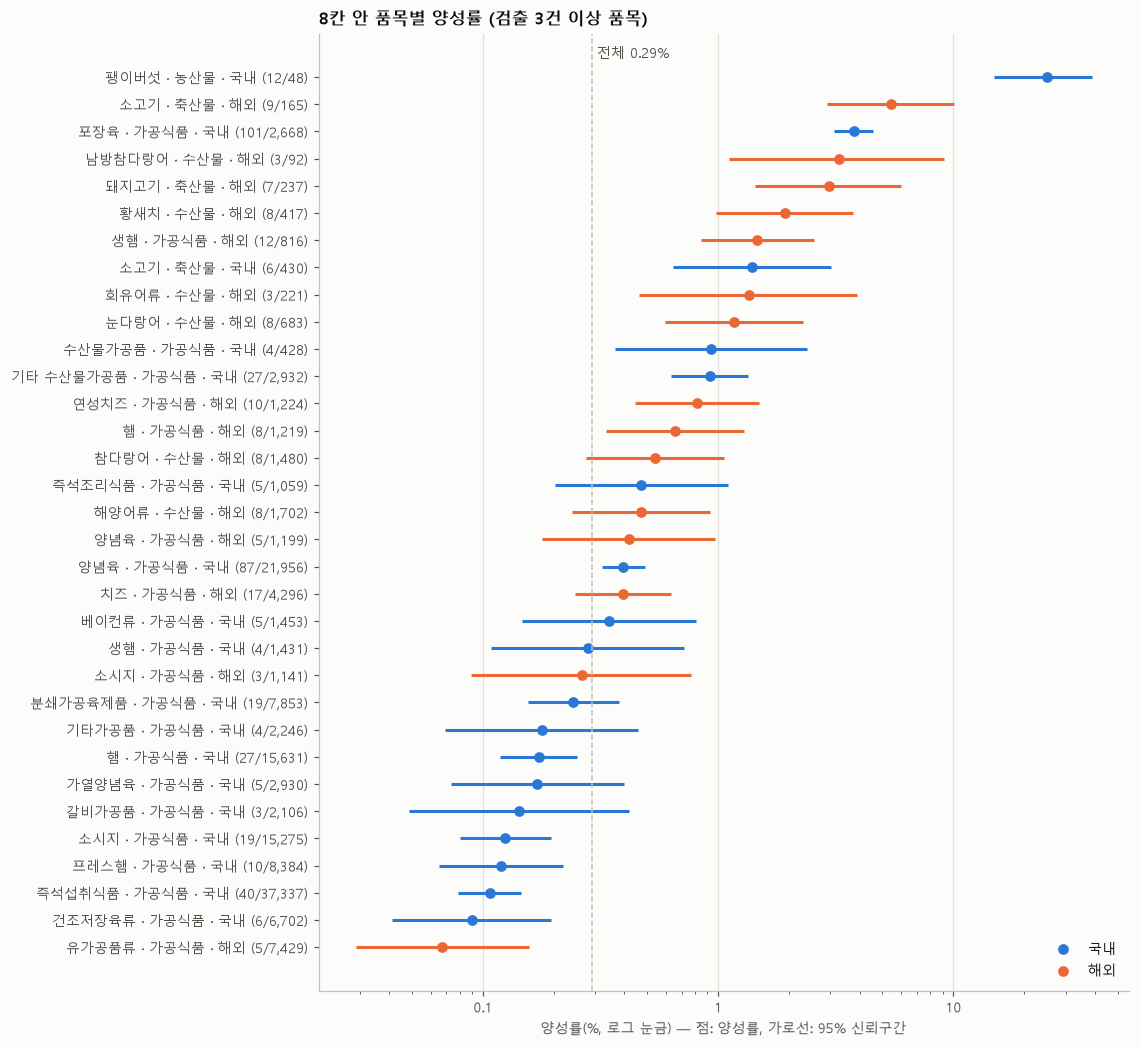

In [29]:
# [3-6-1] ④ 검출 3건 이상인 품목의 양성률과 95% 신뢰구간 — 국내/해외를 따로 한 줄씩, 가로축은 로그 눈금
from matplotlib.ticker import FuncFormatter

fp = cd.groupby(['대분류', '국내해외', '품목명'], observed=True)['pos'].agg(건수='size', 검출='sum').reset_index()
fp = fp[fp['검출'] >= 3].copy()
fp['rate'] = fp['검출'] / fp['건수'] * 100
fp['lo'], fp['hi'] = wilson(fp['검출'], fp['건수'])
fp = fp.sort_values('rate').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9.5, 0.3 * len(fp) + 1.4))
y = np.arange(len(fp))
for side, color in [('국내', C1), ('해외', C2)]:
    m = fp['국내해외'].eq(side).to_numpy()
    ax.hlines(y[m], fp['lo'].to_numpy()[m], fp['hi'].to_numpy()[m], color=color, lw=2)
    ax.plot(fp['rate'].to_numpy()[m], y[m], 'o', color=color, ms=6, label=side)
base = dfx['pos'].mean() * 100
ax.axvline(base, color=GRAY, lw=1, ls='--')
ax.text(base, len(fp) - 0.4, f' 전체 {base:.2f}%', color=INK2, fontsize=9, va='bottom')
ax.set_xscale('log')
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
ax.set_yticks(y)
ax.set_yticklabels([f"{p} · {c.replace('(원물)', '')} · {s} ({k}/{n:,})" for p, c, s, k, n in
                    zip(fp['품목명'], fp['대분류'], fp['국내해외'], fp['검출'], fp['건수'])])
ax.grid(axis='y', visible=False)
ax.set_xlabel('양성률(%, 로그 눈금) — 점: 양성률, 가로선: 95% 신뢰구간')
ax.set_title('8칸 안 품목별 양성률 (검출 3건 이상 품목)', loc='left')
ax.legend(loc='lower right', frameon=False);

📊 **결과 — 8칸 요약** (칸 = 검출 / 건수, 양성률)

| 칸 | 국내 | 해외 |
|---|---|---|
| 농산물(원물) | 15 / 2,098 (0.72%) — 팽이버섯 12/48, 엄나무 2/32, 밤 1/48 | **0행** — 수입 LIMS 리스테리아 행에 농산물(A) 코드가 없음 |
| 축산물(원물) | 9 / 966 (0.93%) — 소고기 6/430, 돼지고기 1/234, 소유 1/91 | 19 / 765 (2.48%) — **소고기 9/165 (5.5%), 돼지고기 7/237 (3.0%)** |
| 수산물(원물) | 3 / 469 (0.64%) — 품목마다 1건씩 | 43 / 8,004 (0.54%) — 해양어류·참다랑어·눈다랑어·황새치 각 8건 |
| 가공식품 | 386 / 294,421 (0.13%) — **포장육 101/2,668 (3.8%)**, 양념육 87, 즉석섭취식품 40, 햄 27, 기타 수산물가공품 27 | 63 / 38,855 (0.16%) — 치즈 17, 생햄 12 (1.5%), 연성치즈 10 (0.8%), 햄 8 |

- **검출은 소수 품목에 몰립니다.** 국내 농산물은 품목 168개 중 3개, 국내 가공식품은 331개 중 32개, 해외 가공식품은 115개 중 9개에서만 검출이 나왔습니다.
- **같은 품목이라도 해외가 높습니다.** 치즈 국내 0.03%(1/3,543) vs 해외 0.40%(17/4,296), 생햄 0.28% vs 1.47%, 햄 0.17% vs 0.66%, 소고기 1.40% vs 5.45%로 약 4\~14배입니다. 치즈·생햄·햄은 신뢰구간이 겹치지 않고, 소고기·돼지고기는 표본이 작아 구간이 조금 겹칩니다.
- **수만 행을 검사해도 0건인 품목**이 있습니다: 알가열제품 19,818행, 농후발효유 15,711행, 아이스크림 9,388행, 아이스밀크 8,225행, 발효유 7,235행, 가공유 5,834행, 샤베트 4,629행. 우유는 8,943행 중 1건입니다.
- **표본이 작은 품목의 높은 값은 믿기 어렵습니다.** 말고기 1/1, 연육 1/4, 간편조리세트 1/6, 해외 기타조제분유 2/14는 신뢰구간 폭이 수십 %p 입니다. 기타조제분유 2건은 같은 제품('압타밀3')·같은 날짜라 한 로트로 보입니다.
- **국내 원물 칸은 parquet 기준 양성률이 DB 전체보다 높습니다.** parquet 가 뺀 행(주로 주소 출처 '검사기관')이 거의 불검출이라, 국내 수산물은 DB 4,334행 0.115% → parquet 469행 0.640%, 국내 농산물은 0.507% → 0.715%, 국내 축산물은 0.683% → 0.932%입니다. 가공식품과 해외 축산물은 거의 같고, 해외 수산물은 0.470% → 0.537%로 조금 높습니다.
- **품목명과 품목코드가 1:1 이 아닙니다.** 8칸의 품목명 626개가 코드 1,192개에 대응하고, 코드가 2개 이상인 품목명(223개)이 8칸 행의 96%를 차지합니다. 가공식품은 14자리·20자리(뒤에 0 여섯 개) 표기와 C03·C02·C01 코드가 섞여 있고, 수입 축·수산물은 20자리 세부 코드에 어종·냉동/냉장·부위·횟감 여부가 들어 있습니다 (③).

💬 **첨언**
- **포장육**은 생고기를 자르거나 포장만 한 식품(한우 목심·차돌박이·육회·오리로스 등)입니다. 코드는 가공식품이지만 성격은 원물(식육)에 가깝고, 국내 가공식품 검출 386건 중 101건(26%)이 여기서 나옵니다. 가공식품 칸을 한 덩어리로 보면 비가열 생육의 신호가 섞입니다.
- **수입 원물 검출**을 수입 LIMS 품명으로 보면, 수산물 43건은 황새치·눈다랑어·참다랑어 같은 **냉동 필렛 횟감**이고 축산물 19건 중 18건은 **냉동 소고기·돼지고기 정육**과 닭 다리입니다 (③ 출력, 접수번호 단위 대표 품명). ready_data 품목명이 '해양어류'처럼 포괄 이름인 행도 실제로는 이런 횟감입니다. 해외에서 필렛·발골·동결을 거친 제품이라 산지 기상보다 가공 단계의 영향을 먼저 의심해야 합니다 (추정).
- **해외 농산물 칸이 비어 있어** 메모의 8분할은 실제로 7칸입니다.
- 품목명 기준 집계는 코드가 다른 같은 이름을 한 줄로 합산한 결과이고, 코드 단위로 쪼개면 같은 품목이 2\~4줄로 나뉩니다 (③). 어느 단위로 학습할지는 결정이 필요한 문제라, 여기서는 합치거나 버리지 않고 두 결과를 모두 보였습니다.

✅ **결론** — 8칸 안에서도 검출은 소수 품목에 몰립니다. 국내는 **포장육·양념육·즉석섭취식품·햄·기타 수산물가공품·소시지**와 원물 중 **팽이버섯·소고기**, 해외는 **소고기·돼지고기, 냉동 횟감 참치류·황새치, 치즈·연성치즈·생햄**입니다. 살균 유가공품·알가공품·빙과는 수만 행에서도 0건입니다. 품목별 양성률은 표본이 작은 품목이 많아 **신뢰구간과 함께** 봐야 하고, 국내 원물 칸은 parquet 필터 때문에 DB 전체보다 높게 나온다는 점을 감안해야 합니다.

❓ **나박사님께**: 포장육(생고기 절단·포장)은 리스테리아 관점에서 가공식품과 원물(식육) 중 어디로 묶는 것이 맞습니까? 같은 치즈·생햄·햄인데 수입품의 양성률이 국내품보다 약 4\~14배 높은 것은 비살균 원유·비가열 숙성 같은 제조 방식 차이로 설명됩니까?

🗄️ **모델팀께**: ① 수입 LIMS 리스테리아 행에 농산물(A) 코드가 한 건도 없습니다. 수입 농산물은 리스테리아 검사를 하지 않습니까, 다른 테이블에 있습니까? ② 같은 품목명에 14자리·20자리, C01·C02·C03 코드가 섞인 기준은 무엇이고, 학습용 품목 단위는 코드와 품목명 중 무엇으로 정합니까?

#### 3-6-2. 제품명으로 다시 센 원물 — 기준규격외 코드 속 원물

🔎 위 8분할은 **품목코드**로만 원물을 골랐습니다. 그런데 3-3절에서 봤듯 기준규격외(Z) 코드에는 공장에 들어온 원료육, 세척 전후 배추·무, 팽이버섯 같은 원물 검체가 섞여 있습니다.
그래서 **제품명 키워드로 원물을 한 번 더 식별**합니다. 규칙은 아래 코드에 그대로 있습니다.
1. 제품명에 원물 이름(채소·과일·버섯·생육·생선·알·원유)이 있고
2. 가공을 뜻하는 말(김치·분말·가열·완제품·양념·훈제·건조 등)이 없으며
3. 3-4절의 환경검체(바닥·장갑 등)가 아닌 행을 "원물 이름 행"으로 봅니다.
4. 이 규칙은 **기준규격외(Z) 코드에만** 적용합니다. 가공식품(C) 코드는 이름에 원물이 들어가도 딸기우유·구운계란처럼 가공품이 대부분이라 참고로만 셉니다.

In [30]:
# 원물 이름 사전: 위에서부터 먼저 걸리는 유형 하나를 붙인다 (정규식, 소문자·공백 제거 후 비교)
RAW_TYPE = {
    '버섯': r'팽이|enoki|flammulina|버섯|mushroom',
    '생선·해산물(회·횟감)': r'(?:광어|우럭|도미|방어|참치|다랑어|연어|홍새우|새우|오징어|문어|낙지|전복|숭어|농어)(?:회|사시미)|횟감|사시미',
    '생선·해산물': r'고등어|삼치|오징어|광어|연어|참치|다랑어|갈치|명태|새우|굴$|굴\(|생굴|조개|전복|문어|낙지|꽃게|홍합|바지락|숭어|농어|우럭|도미|방어',
    '생육·원료육': r'원료육|돈육|우육|한우|돼지고기|소고기|쇠고기|닭고기|계육|정육|생고기|오리고기|다짐육|목심|삼겹|앞다리|뒷다리|등심|안심|갈비살',
    '채소': r'배추|양파|대파|쪽파|마늘|당근|오이|생강|고추|부추|양배추|상추|깻잎|시금치|콩나물|숙주|파프리카|브로콜리|^무$|^무[\(\-]|^무세척',
    '과일': r'사과|딸기|포도|토마토|키위|바나나|멜론|수박|블루베리',
    '알': r'계란|달걀|유정란|원란|난황|난백',
    '원유': r'^원유|집유',
}
# 가공을 뜻하는 말: 이름에 있으면 원물로 보지 않는다
NOT_RAW = (
    r'김치|장아찌|피클|볶음|무침|조림|즙|분말|가루|소스|케첩|케찹|페이스트|살사|가열|완제품|살균후|살균\(후|살균제품|멸균'
    r'|양념|튀김|찌개|탕|죽$|국밥|초밥|김밥|도시락|샐러드|샌드위치|햄|소시지|소세지|훈제|건조|^건|말랭이|잼|주스|음료'
    r'|떡|빵|과자|아이스|샤벳|샤베트|우유|요거트|요구르트|시럽|청$|퓨레|농축|통조림|캔$|맛$|맛\)|향$|식초|포도당|씨유'
    r'|고추장|된장|간장|흑마늘|소박이|불고기|떡갈비|패티|너겟|까스|커틀릿|염지|굴비|젓|깡$|육포|오징어채|포$|마요'
    r'|액$|액\(|지단|후레이크|구운|군계란|토스트|말이|진밥|분쇄|가공육|꼬치|반제품|용수|배지|종균|톱밥'
    r'|동태전|파전|부추전|호박전|깻잎전|해물전|녹두전|생강차|녹차|유자차|대추차|편육|수육|자숙|조리|삶은'
    r'|액상|분$|치킨|텐더|스틱|바베큐|덮밥|강정|칩|사과산'
)
env_m = flags['환경검체']                              # 1-3절에서 만든 환경검체 플래그
not_raw_m = has_kw(dfx['prduct_nm'], NOT_RAW)
raw_type = pd.Series(np.select([has_kw(dfx['prduct_nm'], p) for p in RAW_TYPE.values()], list(RAW_TYPE.keys()), ''), index=dfx.index)
name_raw = raw_type.ne('') & ~not_raw_m & ~env_m
code_raw = dfx['대분류'].isin(['농산물(원물)', '축산물(원물)', '수산물(원물)'])

dfx['원물구분'] = np.select(
    [code_raw, dfx['대분류'].eq('기준규격외(검체)') & name_raw, dfx['대분류'].eq('가공식품') & name_raw],
    ['① 원물 코드(A·B)', '② 기준규격외 코드 + 원물 이름', '(참고) 가공식품 코드 + 원물 이름'], '원물 아님')
dfx['원물유형'] = np.where(code_raw, dfx['대분류'].str.replace('(원물)', '', regex=False),
                        np.where(dfx['원물구분'].ne('원물 아님'), raw_type, ''))

g = dfx.groupby(['원물구분', '국내해외'], observed=True)['pos'].agg(건수='size', 검출='sum')
cell = g.apply(lambda r: f"{int(r['검출']):,} / {int(r['건수']):,}  ({r['검출'] / r['건수']:.3%})", axis=1)
dom_raw = dfx['국내해외'].eq('국내') & dfx['원물구분'].isin(['① 원물 코드(A·B)', '② 기준규격외 코드 + 원물 이름'])
print(f"국내 원물(①+②): {int(dom_raw.sum()):,}행 = 국내 행의 {dom_raw.sum() / (dfx['국내해외'] == '국내').sum():.1%}, 검출 {int(dfx.loc[dom_raw, 'pos'].sum())}건")
print('칸 = 검출 / 건수 (검출률)')
cell.unstack('국내해외').reindex(['① 원물 코드(A·B)', '② 기준규격외 코드 + 원물 이름', '(참고) 가공식품 코드 + 원물 이름', '원물 아님']).fillna('-')

국내 원물(①+②): 53,784행 = 국내 행의 8.6%, 검출 688건
칸 = 검출 / 건수 (검출률)


국내해외,국내,해외
원물구분,,
① 원물 코드(A·B),"27 / 3,533 (0.764%)","62 / 8,769 (0.707%)"
② 기준규격외 코드 + 원물 이름,"661 / 50,251 (1.315%)",-
(참고) 가공식품 코드 + 원물 이름,"98 / 14,322 (0.684%)",0 / 478 (0.000%)
원물 아님,"1,058 / 560,789 (0.189%)","63 / 38,395 (0.164%)"


In [31]:
# ② 기준규격외 코드 속 원물 이름 행: 유형별 규모와 대표 제품명 (규칙 검토용)
z = dfx[dfx['원물구분'].eq('② 기준규격외 코드 + 원물 이름')]
t = z.groupby('원물유형')['pos'].agg(건수='size', 검출='sum')
t['검출률(%)'] = (t['검출'] / t['건수'] * 100).round(3)
t['대표 제품명'] = z.groupby('원물유형')['prduct_nm'].agg(lambda s: ', '.join(s.value_counts().head(5).index))
t['검출된 제품명'] = z[z['pos'] == 1].groupby('원물유형')['prduct_nm'].agg(lambda s: ', '.join(s.value_counts().head(4).index))
display(t.sort_values('검출', ascending=False))

excluded = dfx[dfx['대분류'].eq('기준규격외(검체)') & raw_type.ne('') & (not_raw_m | env_m)]
print(f"원물 이름이 있지만 가공어·환경검체라 뺀 기준규격외 행 {len(excluded):,}행 — 상위 제품명:")
print(', '.join(f'{k}({v})' for k, v in excluded['prduct_nm'].value_counts().head(15).items()))
ref = dfx[dfx['원물구분'].eq('(참고) 가공식품 코드 + 원물 이름')]
print(f"\n(참고) 가공식품 코드에서 원물 이름이 걸린 행 {len(ref):,}행 — 상위 제품명:")
print(', '.join(f'{k}({v})' for k, v in ref['prduct_nm'].value_counts().head(15).items()))

,건수,검출,검출률(%),대표 제품명,검출된 제품명
원물유형,,,,,
버섯,7481,428,5.721,"팽이버섯, 수출용 팽이버섯 (2-1번), 수출용 팽이버섯 (2-2번), 수출용 팽이버섯 (2번), 수출용 팽이버섯 (1번)","ENOKI MUSHROOM GR5-3, 수출용 팽이버섯 (2번), ENOKI MUSHROOM GR4-1, 수출용 팽이버섯 (3번)"
생육·원료육,12810,112,0.874,"원료육, 원료육-입고전, 원료육-사용전, 원료육 냉장보관 후, 원료육 냉장보관 전","돈육, 소고기, 한우다짐육, 하이포크 목심 원료육"
생선·해산물,8770,83,0.946,"오징어, 고등어, 삼치, 활전복, 연어필렛","연어필렛, 연어(캐나다산), 냉장 연어 필렛, 홍새우"
생선·해산물(회·횟감),464,32,6.897,"광어회, 홍새우회, 연어회, 생연어회, 광어회(다시마숙성)","광어회, 연어회, 홍새우회, 생연어회"
채소,17359,5,0.029,"배추(세척전), 배추(세척후), 양파, 대파, 절임배추","생강 세척 후, 깻잎, 절임배추 세척전 3차, 생강 세척 전"
원유,152,1,0.658,"원유, 원유(살균전), 원유 A, 원유 B, 원유 살균전",원유(즐거운목장)
과일,2743,0,0.000,"사과, 토마토, 블루베리, 방울토마토, 딸기",<NA>
알,472,0,0.000,"원란(계란), 계란난황립, 냉동난황, 생계란, 계란",<NA>


원물 이름이 있지만 가공어·환경검체라 뺀 기준규격외 행 24,424행 — 상위 제품명:
건고추(116), 배추김치(66), 델링토마토케찹(공정품)(63), 버섯재배용수(56), 생강분말(47), 흑마늘힐링덕(샘플)(45), 건포도(44), 바나나칩(43), 고등어(완제품)(42), 삼치(완제품)(40), 배추김치(완제품)(39), 오징어(완제품)(37), 오이피클(34), 건블루베리(33), 오징어채(33)

(참고) 가공식품 코드에서 원물 이름이 걸린 행 14,800행 — 상위 제품명:
딸기(106), 딸기플레인(102), 절임배추(102), 네모난계란난황(96), 블루베리 요고라또(91), 냉장연어살(90), 깐계란(88), 요맘때 딸기(85), 새우칵테일(81), 참 편한 계란(살균전란)(76), 간이 배어있는 반숙계란(74), 메로나 바나나(72), 완숙깐계란(68), 흥생농장반숙계란(68), 반숙계란(67)


In [32]:
# ② 는 어떤 검체인가 — 누가 의뢰했나(검사목적), 이름에 공장 원료·공정 단계 표기('원료육', '세척전', '입고전', '절임' 등)가 있나
STEP = r'세척|입고|원료|전처리|절임|해동|보관|사용전|투입|공정|선별|손질|탈피|침지|살균전|숙성'
KIMCHI_VEG = r'배추|^무$|^무[\(\-]|^무세척|양파|대파|쪽파|마늘|생강|고추|부추|양배추'


def profile(frame):
    return pd.Series({'행 수': len(frame), '검출': int(frame['pos'].sum()),
                      "검사목적 '기타'(%)": (frame['검사목적'] == '기타').mean() * 100,
                      'HACCP 인증검사(%)': (frame['검사목적'] == '식품안전관리인증검사').mean() * 100,
                      '이름에 원료·공정 단계 표기(%)': has_kw(frame['prduct_nm'], STEP).mean() * 100})


prof = pd.DataFrame({k: profile(v) for k, v in [('② 전체', z)] + list(z.groupby('원물유형'))}).T.round(1)
prof[['행 수', '검출']] = prof[['행 수', '검출']].astype(int)
display(prof.sort_values('행 수', ascending=False))

veg = z[z['원물유형'].eq('채소')]
print(f"채소 {len(veg):,}행 중 김치 원료 채소 이름(배추·무·양파·대파·마늘·생강·고추 등) {has_kw(veg['prduct_nm'], KIMCHI_VEG).mean():.0%}, "
      f"'세척·절임' 표기 {has_kw(veg['prduct_nm'], r'세척|절임').mean():.0%}")
print('채소 행이 많은 업체:', ', '.join(f'{k}({v})' for k, v in veg['mnfctur_cmpny_nm'].value_counts().head(6).items()))
mush = z[z['원물유형'].eq('버섯')]
enoki = has_kw(mush['prduct_nm'], r'팽이|enoki|flammulina')
print(f"버섯 {len(mush):,}행 중 팽이버섯 {enoki.mean():.0%}, 버섯 검출 {int(mush['pos'].sum())}건 중 팽이버섯 {int(mush.loc[enoki, 'pos'].sum())}건")

,행 수,검출,검사목적 '기타'(%),HACCP 인증검사(%),이름에 원료·공정 단계 표기(%)
② 전체,50251,661,91.8,6.8,50.4
채소,17359,5,90.2,7.4,62.6
생육·원료육,12810,112,88.8,10.9,77.2
생선·해산물,8770,83,92.9,5.7,39.0
버섯,7481,428,99.5,0.4,2.2
과일,2743,0,92.0,5.0,26.6
알,472,0,89.6,10.0,31.4
생선·해산물(회·횟감),464,32,83.2,0.9,13.6
원유,152,1,98.7,1.3,37.5


채소 17,359행 중 김치 원료 채소 이름(배추·무·양파·대파·마늘·생강·고추 등) 83%, '세척·절임' 표기 57%
채소 행이 많은 업체: 농업회사법인 송산 주식회사(159), 농업회사법인 주식회사 한울(99), 농업회사법인 주식회사 한성그린팩토리(98), (주)조선호텔앤리조트김치(90), 농업회사법인(주)왕인식품(71), (유)신포우리식품(68)
버섯 7,481행 중 팽이버섯 82%, 버섯 검출 428건 중 팽이버섯 418건


📊 **결과**
- 국내에서 원물 코드(A·B) 행은 3,533행(검출 27건)인데, **기준규격외 코드 안의 원물 이름 행은 50,251행(검출 661건)** 입니다. 둘을 합치면 53,784행(검출 688건), **국내 행의 8.6%** 입니다. 코드만으로는 원물 검체를 크게 과소평가합니다.
- 기준규격외 속 원물의 검출 661건은 **버섯 428건(그중 팽이버섯 418건), 생육·원료육 112건, 생선·해산물 115건(회·횟감 32건 포함)** 으로, 세 유형이 99%입니다.
- **채소 17,359행은 검출 5건, 과일 2,743행은 0건**입니다. 채소 행의 83%는 배추·무·양파·마늘·생강 같은 김치 원료 채소이고, 57%에는 '세척전·세척후·절임' 표기가 붙어 있습니다.
- ② 행의 91.8%는 검사목적 '기타', 6.8%는 HACCP 인증검사로 **업체가 의뢰한 검사**입니다. 50.4%는 이름에 '원료육', '세척전', '입고전', '절임' 같은 공장 원료·공정 단계 표기가 있습니다 (생육·원료육 77.2%, 채소 62.6%).

💬 **첨언**
- 즉 이 원물들은 산지에서 채취한 시료가 아니라 **공장에 들어온 원료나 세척 단계의 공정 시료**입니다. 재배지·목장·어장 위치나 수확일이 없어, 기상을 붙이려면 여전히 공장 주소와 의뢰일을 써야 합니다.
- 기후 영향이 이론상 가장 클 **노지 채소·과일은 표본이 2만 행 넘게 있어도 검출이 거의 없습니다.** 검출이 많은 원료육·생선·팽이버섯은 도축·어획 과정이나 재배사 내부 환경의 영향이 더 커 보입니다 (추정).
- 키워드 규칙이라 오탐과 누락이 있습니다. 위의 "뺀 행"과 "(참고) 가공식품 코드" 목록을 보고 규칙을 고칠 수 있습니다. 규칙을 만들면서 '세척전'이 '전'(부침개)으로, '냉장보관 1차'가 '차'(음료)로 잘못 빠지던 제외어를 지웠고, 과일로 잡힌 'DL-사과산'(식품첨가물)은 제외어에 넣었습니다.

✅ **결론** — 원물은 "코드 기준 1.8%"가 아니라 "제품명까지 보면 국내 8.6%"입니다. 다만 늘어난 원물의 검출은 버섯·원료육·생선에 몰리고 채소·과일은 거의 0이라, **"국내 원물에 기후를 붙이면 신호를 볼 수 있다"는 기대는 여전히 약합니다.** 5-3절과 9-2절의 표본 표에 이 식별을 반영했습니다.

❓ **나박사님께**: 공장에 입고된 원료육, 세척 전후 배추처럼 **공정에 들어온 원물 검체**를 "원물"로 봐도 됩니까? 기상 영향을 따진다면 이런 검체를 넣어야 합니까, 산지에서 바로 채취한 원물만 봐야 합니까?

### 3-7. 많이 나오는 것만 예측하면 되나 (메모 P6, 17)

🔎 품목을 검출 많은 순으로 쌓았을 때 검출과 검사 건수가 얼마나 누적되는지 봅니다.

,건수,검출,검출률(%),누적 검출비중(%),누적 건수비중(%)
train_prdlst_nm,,,,,
기타기준규격외,291813,791,0.271,40.2,43.1
"정액,수정란,종란",28651,640,2.234,72.7,47.4
식육가공품 및 포장육,101045,323,0.320,89.1,62.3
수산물,8473,46,0.543,91.4,63.6
즉석식품류,35322,45,0.127,93.7,68.8
유가공품류,107022,40,0.037,95.7,84.6
수산가공식품류,4915,29,0.590,97.2,85.3
축산물,1731,28,1.618,98.6,85.6
버섯류,92,12,13.043,99.2,85.6


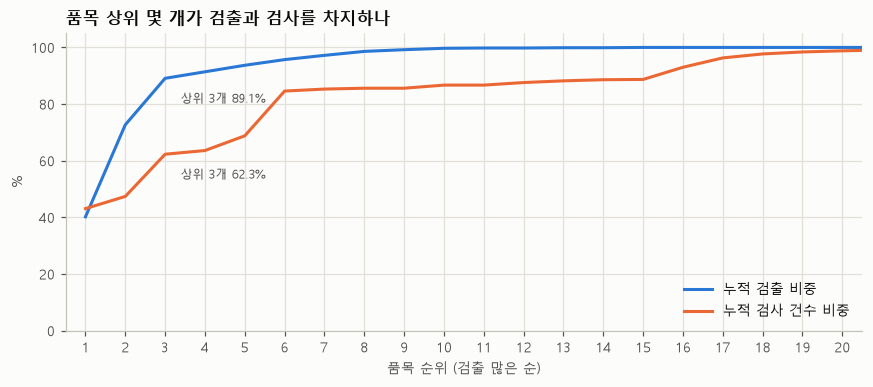

In [33]:
cum = rate_by(dfx, 'train_prdlst_nm')[['건수', '검출', '검출률(%)']].copy()
cum['누적 검출비중(%)'] = (cum['검출'].cumsum() / P * 100).round(1)
cum['누적 건수비중(%)'] = (cum['건수'].cumsum() / N * 100).round(1)
display(cum.head(10))

k = np.arange(1, len(cum) + 1)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(k, cum['누적 검출비중(%)'], color=C1, label='누적 검출 비중')
ax.plot(k, cum['누적 건수비중(%)'], color=C2, label='누적 검사 건수 비중')
for series, color in [('누적 검출비중(%)', C1), ('누적 건수비중(%)', C2)]:
    ax.annotate(f"상위 3개 {cum[series].iloc[2]:.1f}%", (3, cum[series].iloc[2]), xytext=(10, -16),
                textcoords='offset points', fontsize=8, color=INK2)
ax.set_xlim(0.5, 20.5)
ax.set_ylim(0, 105)
ax.set_xticks(range(1, 21))
ax.set_xlabel('품목 순위 (검출 많은 순)')
ax.set_ylabel('%')
ax.set_title('품목 상위 몇 개가 검출과 검사를 차지하나')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

📊 **결과** — 검출 상위 3개 품목이 검출의 89.1%를 차지하고, 검사 건수로도 62.3%입니다. 검출 상위 10개 품목이 검출의 99.7%입니다.

💬 **첨언**
- "많이 나오는 품목만 예측"은 합리적이지만, 상위 품목 중 2개가 **식품이 아닌 검체 코드**라 그대로는 쓸 수 없습니다.
- 검사가 많은데 검출이 0인 품목(알가공품 2.9만 건, 빙과류 2.2만 건, 조리식품 0.96만 건)은 "없어서 안 나온 것"에 가깝습니다. 모델에 넣으면 음성만 늘립니다. 반대로 검사가 적어서 안 나온 품목(채소류·과일류 수백 건)은 판단을 보류해야 합니다.

✅ **결론** — 대상은 "검출 건수 기준 상위 + 식품공전상 리스테리아 규격이 있는 유형"으로 좁히고, 검출이 구조적으로 0인 유형은 규칙(사전확률 0)으로 처리하는 2단 구조가 현실적입니다 (9-2절).

### 3-8. 제품명 키워드 — 어떤 식품에서 많이 나오나 (메모 P5, 3, 4)

🔎 제품명에 대표 키워드가 들어간 행의 검출률을 봅니다. 한 제품명이 여러 키워드에 걸릴 수 있고, 한 글자 키워드는 과대 집계될 수 있습니다.

In [34]:
KW = {
    '팽이버섯': r'팽이|enoki|flammulina', '육회': r'육회', '연어': r'연어|salmon',
    '횟감·회': r'횟감|사시미|(광어|우럭|참치|방어|도미|홍새우|새우|오징어|문어|연어)회',
    '정육·원료육(소·돼지·닭)': r'한우|소고기|쇠고기|돈육|돼지|닭고기|계육|정육|원료육',
    '냉장 표기': r'냉장', '냉동 표기': r'냉동', '훈제': r'훈제|스모크|smoked',
    '햄': r'햄|ham', '소시지': r'소시지|소세지|sausage', '베이컨': r'베이컨|bacon',
    '생햄·살라미': r'생햄|프로슈토|prosciutto|하몽|jamon|살라미|salami',
    '치즈': r'치즈|cheese', '우유·요구르트': r'우유|요구르트|요거트|yogurt', '아이스크림': r'아이스크림|icecream',
    '김밥·도시락·샌드위치': r'김밥|도시락|샌드위치|sandwich', '샐러드·새싹': r'샐러드|salad|새싹',
    '어묵·게맛살': r'어묵|게맛살', '만두': r'만두', '두부': r'두부', '젓갈': r'젓갈',
    '살균·멸균 표기': r'살균|멸균', '분말·건조': r'분말|건조|파우더',
}
rows = []
for k, p in KW.items():
    m = has_kw(dfx['prduct_nm'], p)
    rows.append({'키워드': k, '건수': int(m.sum()), '검출': int(dfx.loc[m, 'pos'].sum()), '수입 비중(%)': round((dfx.loc[m, '국내해외'] == '해외').mean() * 100, 1)})
kw = pd.DataFrame(rows).set_index('키워드')
kw['검출률(%)'] = (kw['검출'] / kw['건수'] * 100).round(3)
kw['리프트'] = (kw['검출률(%)'] / (P / N * 100)).round(2)
kw.sort_values('검출률(%)', ascending=False)

,건수,검출,수입 비중(%),검출률(%),리프트
키워드,,,,,
팽이버섯,7405,516,0.0,6.968,23.94
육회,457,16,0.0,3.501,12.03
연어,3112,96,10.4,3.085,10.60
횟감·회,9094,85,86.9,0.935,3.21
정육·원료육(소·돼지·닭),29374,253,2.6,0.861,2.96
냉장 표기,14689,106,5.3,0.722,2.48
냉동 표기,16278,102,52.6,0.627,2.15
생햄·살라미,2441,11,35.8,0.451,1.55
만두,2493,9,1.0,0.361,1.24


📊 **결과** — 검출률이 높은 키워드는 팽이버섯·육회·연어·횟감·정육 같은 **비가열·원물·생식** 계열입니다. 우유·요구르트·아이스크림·분말·살균 표기 같은 **가열·살균·건조** 계열은 거의 0입니다.

💬 **첨언**
- info.md 의 "가열 여부 × 그대로 섭취 여부가 가장 강한 피처"라는 가설이 제품명 수준에서도 보입니다.
- 반면 해외에서 대표 고위험으로 꼽히는 **훈제·햄·소시지·치즈·샌드위치·샐러드는 이 데이터에서 평균 수준이거나 낮습니다.** 위험도가 높아 검사를 많이 하지만 실제 검출은 드문 "검사 편향"일 수 있습니다 (추정).

❓ **나박사님께**: 훈제연어·생햄·연성치즈처럼 해외에서 고위험으로 꼽히는 RTE 식품이 국내 검사에서는 검출률이 평균 수준입니다. 국내 공정 관리 수준 때문입니까, 검사 대상 선정 방식 때문입니까?

### 3-9. 해외·냉동 원료로 만든 가공식품을 데이터에서 구분할 수 있나 (메모 P4, 16, 0)

메모의 "수입 연어가 언제 얼려져 가공식품에 쓰였나"는 **원료 이력 전반**에 대한 질문의 한 예로 보고, 연어에 한정하지 않고 확인합니다.

🔎 국내 행에서 원산지·수입국 코드가 얼마나 채워져 있는지, 채워진 행이 어떤 제품인지 봅니다. 연어는 비교용으로 표 하나만 봅니다.

In [35]:
KR = ['대한민국', '국산', '국내산', '한국', 'KR', 'KOR']
dom_rows = dfx[dfx['국내해외'] == '국내'].copy()
org = dom_rows['orgplce_nation_code'].astype('string').str.strip()
imp = dom_rows['import_nation_code'].astype('string').str.strip()
foreign = ((org.notna() & ~org.isin(KR)) | (imp.notna() & ~imp.isin(KR))).fillna(False).to_numpy(bool)
korea = (org.isin(KR) | imp.isin(KR)).fillna(False).to_numpy(bool) & ~foreign
dom_rows['원산지 표기'] = np.select([foreign, korea], ['해외 국가 표기', '국내 표기'], '표기 없음')
display(rate_by(dom_rows, '원산지 표기', sort='n'))
print('해외 국가 표기 국내 행의 대표 제품명:', dom_rows.loc[foreign, 'prduct_nm'].value_counts().head(6).index.tolist())

# 예시(연어): 국내/해외와 기준일 출처만 확인
sal = dfx[has_kw(dfx['prduct_nm'], r'연어|salmon')]
rate_by(sal, ['국내해외', 'date_basis'], sort='index')

,건수,검출,검출률(%),검출비중(%),리프트
원산지 표기,,,,,
표기 없음,591032,1780,0.301,96.5,1.03
국내 표기,31262,54,0.173,2.9,0.59
해외 국가 표기,6601,10,0.151,0.5,0.52


해외 국가 표기 국내 행의 대표 제품명: ['니코 하몽 슬라이스(NICO JAMON)', '하몽 세라노 그란 레세르바 슬라이스 (120g)(SERRANO GRAN RESERVA DRY CURED HAM SLICED)', '후디스 프리미엄 산양분유-1(FOODIS PREMIUM GOAT MILK INFANT FORMULA STEP1)', '하몽 세라노(JAMON SERRANO)', '밀크초콜릿 아이스크림', '오리지날 스모크 소시지(ORIGINAL SMOKED SAUSAGE)']


건수  검출  검출률(%)  검출비중(%)   리프트
국내해외 date_basis                                 
국내   의뢰일         1055  58   5.498     60.4  1.78
     제조일         1733  35   2.020     36.5  0.65
해외   선적일          290   3   1.034      3.1  0.34
     의뢰일           34   0   0.000      0.0  0.00

📊 **결과**
- 국내 행의 **94%는 원산지·수입국 코드가 비어** 있습니다. 해외 국가가 적힌 국내 행은 6,601행(검출 10건)뿐이고, 제품명을 보면 하몽·분유·수입 소시지처럼 **수입 완제품을 국내 유통 단계에서 검사한 것**이 대부분입니다.
- 즉 parquet 와 원본 LIMS 에는 "해외 원료로 국내에서 가공한 식품"을 가려낼 컬럼이 없습니다. 원료명·원산지는 정의서 밖 원재료 테이블(1-2절 ⑤)에 있지만 리스테리아 행과의 연결률은 아직 모릅니다. 원료의 수확일·냉동일·입고일 컬럼은 DB 전체에 없습니다.
- 예시로 본 연어도 같습니다. 수입 원물 행은 선적일 기준이고 국내 가공품 행은 제조일·의뢰일 기준이라, **같은 원료라도 두 행을 잇는 키가 없습니다.**

💬 **첨언 — 메모 P4·16**
- 리스테리아에서는 원료가 언제 얼려졌는지보다 **"국내 공장에서 가열했나, 가열 후 슬라이스·포장처럼 손이 가는 공정이 있나"** 가 더 중요합니다. 가열 제품이면 원료 이력은 거의 무관하고, 비가열 제품에서만 원료 오염이 남습니다 (2-0절).
- 그래서 원재료 테이블을 쓸 수 있더라도 원료명·원산지까지만 알 수 있고, 모델에는 **가열 여부·RTE·보존온도 룩업(6-4절)** 이 더 직접적입니다.

❓ **나박사님께**: 해외·냉동 원료로 국내에서 가공한 식품(예: 훈제연어, 수입 원료육 가공품)의 오염 원인은 원료보다 국내 가공 환경으로 봐도 됩니까? 원료 원산지·냉동 이력을 따로 구할 가치가 있습니까?

### 3-10. 팽이버섯

🔎 제품명에 팽이/enoki 가 들어간 행을 연도·품목코드·검사목적·검사기관으로 나눕니다.

In [36]:
en = dfx[has_kw(dfx['prduct_nm'], r'팽이|enoki|flammulina')]
print(f"팽이버섯 관련 {len(en):,}행, 검출 {en['pos'].sum()}건 = 전체 검출의 {en['pos'].sum() / P:.1%} (검출률 {en['pos'].mean():.2%})")
display(rate_by(en, 'year', sort='index').T)
display(rate_by(en, 'train_prdlst_nm'))
display(rate_by(en, '검사목적'))
e_inst = rate_by(en, 'inspct_instt_code', top=3)
e_inst.insert(0, '기관명', e_inst.index.astype(str).map(imap['기관명']))
e_inst

팽이버섯 관련 7,405행, 검출 516건 = 전체 검출의 26.2% (검출률 6.97%)


year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
건수,9.0,12.0,18.000,2218.000,783.000,1734.000,867.000,748.000,683.00,333.000
검출,0.0,0.0,1.000,292.000,46.000,80.000,49.000,21.000,25.00,2.000
검출률(%),0.0,0.0,5.556,13.165,5.875,4.614,5.652,2.807,3.66,0.601
검출비중(%),0.0,0.0,0.200,56.600,8.900,15.500,9.500,4.100,4.80,0.400
리프트,0.0,0.0,0.800,1.890,0.840,0.660,0.810,0.400,0.53,0.090


,건수,검출,검출률(%),검출비중(%),리프트
train_prdlst_nm,,,,,
"정액,수정란,종란",6693,486,7.261,94.2,1.04
기타기준규격외,630,18,2.857,3.5,0.41
버섯류,48,12,25.000,2.3,3.59
조리식품 등,11,0,0.000,0.0,0.00
빙과류,9,0,0.000,0.0,0.00
유가공품류,8,0,0.000,0.0,0.00
즉석식품류,5,0,0.000,0.0,0.00
기타식품류,1,0,0.000,0.0,0.00


,건수,검출,검출률(%),검출비중(%),리프트
검사목적,,,,,
기타,7323,504,6.882,97.7,0.99
모니터링검사,39,9,23.077,1.7,3.31
수거검사,19,3,15.789,0.6,2.27
자가품질위탁검사,22,0,0.000,0.0,0.00
식품안전관리인증검사,2,0,0.000,0.0,0.00


,기관명,건수,검출,검출률(%),검출비중(%),리프트
inspct_instt_code,,,,,,
O000084,Intertek Testing Services Korea Ltd.,6687,486,7.268,94.2,1.04
O000728,"Jain Food Research Institute Co., Ltd",491,14,2.851,2.7,0.41
O000083,한국에스지에스(주),19,5,26.316,1.0,3.78


📊 **결과** — 팽이버섯 관련 행은 7,405행(1.1%)인데 검출 516건으로 **전체 검출의 26.2%** 입니다. 팽이버섯 검출의 57%(292건)가 **2020년**에 몰려 있고, 94%가 한 기관(O000084, Intertek)에서, 98%가 검사목적 '기타'에서 나옵니다. 품목코드는 94%가 '정액,수정란,종란'입니다.

💬 **첨언** — 2020년 3월 미국에서 한국산 팽이버섯 리스테리아 집단감염이 확인된 뒤 수출 업체 검사와 "가열조리용" 표시 조치가 이어졌습니다 (8-3절). 이 데이터의 2020년 급증은 **행정·수출 대응 검사의 흔적**으로 읽는 것이 자연스럽습니다 (시기 일치는 데이터로 확인, 인과는 추정).

### 3-11. 연도·월별 검출률 (보고서 3절 EDA 용)

🔎 연도별 검출률을 전체와 "팽이버섯·환경검체 제외"로 나눠 비교하고, 월별 계절성은 기준일이 실제 제조일인 행으로 봅니다.

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
건수,389.0,10228.000,43874.000,53714.000,60750.000,66014.00,69581.000,73409.000,77032.000,83579.000,90276.000,47691.000
검출,0.0,13.000,67.000,103.000,133.000,396.00,248.000,219.000,215.000,184.000,286.000,105.000
검출률(%),0.0,0.127,0.153,0.192,0.219,0.60,0.356,0.298,0.279,0.220,0.317,0.220
제외 후 검출,0.0,13.000,67.000,103.000,132.000,102.00,198.000,139.000,165.000,158.000,251.000,102.000
제외 후 검출률(%),0.0,0.127,0.153,0.192,0.219,0.16,0.288,0.195,0.219,0.193,0.283,0.217


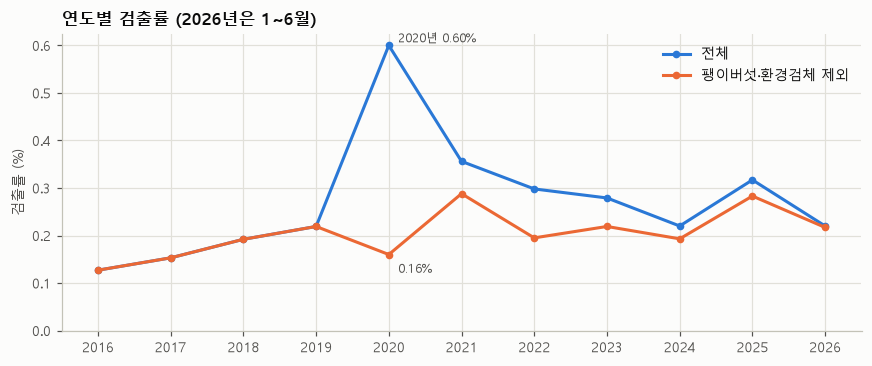

In [37]:
excl = ~dfx['검체성격'].isin(['팽이버섯', '환경검체'])
y_all = rate_by(dfx, 'year', sort='index')
y_ex = rate_by(dfx[excl], 'year', sort='index')
yr = pd.DataFrame({'건수': y_all['건수'], '검출': y_all['검출'], '검출률(%)': y_all['검출률(%)'],
                   '제외 후 검출': y_ex['검출'], '제외 후 검출률(%)': y_ex['검출률(%)']})
display(yr.T)

yy = yr.loc[2016:]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(yy.index, yy['검출률(%)'], color=C1, marker='o', markersize=4, label='전체')
ax.plot(yy.index, yy['제외 후 검출률(%)'], color=C2, marker='o', markersize=4, label='팽이버섯·환경검체 제외')
ax.annotate(f"2020년 {yy.loc[2020, '검출률(%)']:.2f}%", (2020, yy.loc[2020, '검출률(%)']), xytext=(6, 2), textcoords='offset points', fontsize=8, color=INK2)
ax.annotate(f"{yy.loc[2020, '제외 후 검출률(%)']:.2f}%", (2020, yy.loc[2020, '제외 후 검출률(%)']), xytext=(6, -12), textcoords='offset points', fontsize=8, color=INK2)
ax.set_xticks(yy.index)
ax.set_ylabel('검출률 (%)')
ax.set_ylim(0, None)
ax.set_title('연도별 검출률 (2026년은 1~6월)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

month,1,2,3,4,5,6,7,8,9,10,11,12
전체 검출률(%),0.202,0.168,0.215,0.220,0.287,0.281,0.357,0.384,0.349,0.269,0.361,0.440
제조일 기준·팽이/환경 제외 검출률(%),0.103,0.110,0.189,0.156,0.165,0.221,0.207,0.167,0.141,0.107,0.114,0.111
제조일 기준 건수,24208.000,22745.000,27579.000,26936.000,26724.000,25833.000,24683.000,22807.000,22646.000,23468.000,22754.000,22455.000
제조일 기준 검출,25.000,25.000,52.000,42.000,44.000,57.000,51.000,38.000,32.000,25.000,26.000,25.000


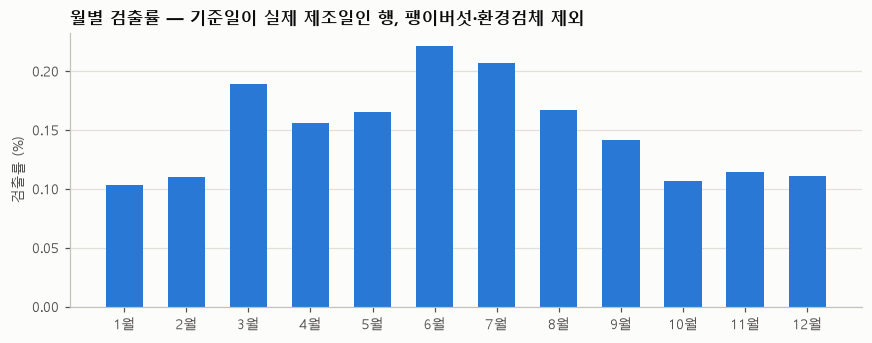

In [38]:
m_all = rate_by(dfx, 'month', sort='index')
m_mnf = rate_by(dfx[(dfx['date_basis'] == '제조일') & excl], 'month', sort='index')
mo = pd.DataFrame({'전체 검출률(%)': m_all['검출률(%)'], '제조일 기준·팽이/환경 제외 검출률(%)': m_mnf['검출률(%)'],
                   '제조일 기준 건수': m_mnf['건수'], '제조일 기준 검출': m_mnf['검출']})
display(mo.T)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(mo.index, mo['제조일 기준·팽이/환경 제외 검출률(%)'], width=0.6, color=C1)
ax.set_xticks(range(1, 13))
ax.set_xticklabels([f'{m}월' for m in range(1, 13)])
ax.grid(axis='x', visible=False)
ax.set_ylabel('검출률 (%)')
ax.set_title('월별 검출률 — 기준일이 실제 제조일인 행, 팽이버섯·환경검체 제외')
plt.tight_layout()
plt.show()

📊 **결과**
- 2020년 전체 검출률 0.60%는 팽이버섯·환경검체를 빼면 0.16%로, 다른 해와 비슷해집니다.
- 기준일이 실제 제조일인 행만 보면 **6\~7월이 1월·10\~12월의 약 2배**로 여름에 높습니다. 기준일이 섞인 전체 기준으로는 12월이 가장 높아 모양이 다릅니다.

💬 **첨언** — 연도·계절 패턴은 기후보다 **기획검사·수출 대응 같은 행정 사건과 검체 구성 변화**가 먼저 반영됩니다. 계절성을 기후 신호로 해석하려면 검사목적·검체성격을 고정한 뒤 봐야 합니다.
또 기준일 출처가 섞인 상태의 월별 그림은 서로 다른 사건(제조·의뢰·선적)의 달을 섞은 것이라 해석하면 안 됩니다 (4장).

❓ **나박사님께**: 식약처·식정원의 연도별 기획검사(예: 2020 팽이버섯, 횟감, 수출용 검사) 목록을 받을 수 있습니까? 연도×품목 "기획검사 여부" 플래그로 붙이고 싶습니다.

---
## 4. 데이터 이해 ② — 언제: 날짜와 기준일 (메모 P3, P7, 12, 13, 14, 22', 23, 27, 28)

### 4-1. 기준일 출처와 "원본 제조일"

🔎 parquet 의 `mnfctur_de` 가 정말 제조일인지, DB 의 원본 제조일(`mnfctur_de`, 여기서는 `mnfctur_de_raw`)과 비교합니다.

In [39]:
display(rate_by(dfx, ['국내해외', 'date_basis'], sort='index'))
dfx['원본제조일'] = np.where(dfx['mnfctur_de_raw'].notna(), '있음', '없음')
same_basis = (dfx['date_basis'].astype(str).eq('제조일') == dfx['mnfctur_de_raw'].notna()).mean()
same_value = (dfx.loc[dfx['mnfctur_de_raw'].notna(), 'mnfctur_de'] == dfx.loc[dfx['mnfctur_de_raw'].notna(), 'mnfctur_de_raw']).mean()
req_rows = dfx['date_basis'].astype(str).eq('의뢰일')
print(f"원본 제조일이 있는 행 비율: {dfx['mnfctur_de_raw'].notna().mean():.1%}")
print(f"'date_basis=제조일' ⇔ '원본 제조일 있음' 일치율: {same_basis:.2%} / 그 행에서 parquet mnfctur_de = 원본 제조일: {same_value:.2%}")
print(f"'date_basis=의뢰일' 행에서 parquet mnfctur_de = DB 의뢰일(reqest_de): {(dfx.loc[req_rows, 'mnfctur_de'] == dfx.loc[req_rows, 'reqest_de']).mean():.2%}")
rate_by(dfx, ['국내해외', '원본제조일'], sort='index')

건수    검출  검출률(%)  검출비중(%)   리프트
국내해외 date_basis                                     
국내   선적일              9     0   0.000      0.0  0.00
     의뢰일         332979  1249   0.375     63.4  1.29
     제조일         295907   595   0.201     30.2  0.69
해외   선적일          47063   125   0.266      6.3  0.91
     의뢰일            446     0   0.000      0.0  0.00
     제조일            133     0   0.000      0.0  0.00

원본 제조일이 있는 행 비율: 43.8%
'date_basis=제조일' ⇔ '원본 제조일 있음' 일치율: 100.00% / 그 행에서 parquet mnfctur_de = 원본 제조일: 100.00%
'date_basis=의뢰일' 행에서 parquet mnfctur_de = DB 의뢰일(reqest_de): 100.00%


건수    검출  검출률(%)  검출비중(%)   리프트
국내해외 원본제조일                                     
국내   없음     332988  1249   0.375     63.4  1.29
     있음     295907   595   0.201     30.2  0.69
해외   없음      47509   125   0.263      6.3  0.90
     있음        133     0   0.000      0.0  0.00

📊 **결과**
- 원본 제조일은 **43.8% 행에만** 있습니다 (국내 47.1%, 수입 0.3%). parquet 의 `mnfctur_de` 는 제조일이 있으면 제조일, 없으면 의뢰일(수입은 선적일)을 넣은 **기준일**입니다.
- 국내에서 원본 제조일이 **없는** 행의 검출률(0.375%)이 **있는** 행(0.201%)보다 높습니다.

💬 **첨언 — 메모 13·14**
- **제조일** = 포장 표시의 제조일자를 옮겨 적은 값입니다. 포장 표시가 없는 시료(공정시료·원물·환경검체·조리식품)는 구조적으로 비어 있습니다. 그래서 "제조일 결측" 자체가 비포장·현장 검체 신호이고, 검출률이 높게 나옵니다.
- **의뢰일** = 시료가 검사기관에 의뢰된 날입니다 (4-2절에서 요일로 확인).
- 제조일 결측 여부를 피처로 넣으면 성능은 오르지만, 사실상 "검체 종류"를 배우는 것이라 해석에 주의해야 합니다.

### 4-2. 요일로 본 기준일의 실체

🔎 공장은 주말에도 돌 수 있지만 검사 의뢰는 주말에 거의 없고, 배는 주말에도 선적합니다. 요일 분포로 각 날짜가 무엇인지 확인합니다.

In [40]:
wd = pd.crosstab(dfx['date_basis'], dfx['mnfctur_de'].dt.dayofweek, normalize='index').mul(100).round(1)
wd.columns = ['월', '화', '수', '목', '금', '토', '일']
wd['주말 합계(%)'] = wd['토'] + wd['일']
wd

,월,화,수,목,금,토,일,주말 합계(%)
date_basis,,,,,,,,
선적일,10.8,12.9,13.9,14.2,19.1,14.3,14.7,29.0
의뢰일,19.7,22.6,21.5,22.0,14.1,0.1,0.1,0.2
제조일,21.2,20.0,19.6,18.5,14.8,3.4,2.4,5.8


📊 **결과** — 의뢰일 기준 행의 주말 비중은 0.2% 로 사실상 영업일만 있고, 제조일은 5.8%, 선적일은 29.0% 입니다.

✅ **결론** — 세 날짜는 각각 진짜 의뢰일·제조일·선적일입니다. 즉 `mnfctur_de` 한 컬럼에 **서로 다른 세 사건의 날짜**가 섞여 있습니다.

### 4-3. 국내 날짜 흐름 — 제조 → 의뢰 → 접수 → 검사 완료 (메모 P3, 13, 23)

🔎 원본 LIMS 의 날짜 컬럼 채움률과, 구간별 간격(일)의 분포를 봅니다.

,국내 채움률(%),해외 채움률(%)
제조일(원본),47.1,0.3
의뢰일,100.0,100.0
접수일,100.0,84.9
채취(수거)일,0.0,84.4
검사시작일,5.6,84.4
검사종료일,5.6,84.4
검사완료일,100.0,84.9
유통일(distb_de),30.3,0.3
유효기한(숫자),2.5,0.0


,n,p05,p25,중앙값,p75,p95,평균,음수(%)
구간,,,,,,,,
의뢰일 − 제조일,295907,0.0,0.0,2.0,7.0,37.0,12.0,0.47
접수일 − 의뢰일,628895,0.0,0.0,0.0,0.0,0.0,0.2,0.77
검사완료일 − 접수일,628895,6.0,7.0,9.0,13.0,20.0,11.2,0.01
검사종료일 − 검사시작일,35151,4.0,7.0,11.0,16.0,33.0,14.5,0.03
유통일(distb_de) − 제조일,124716,1.0,14.0,44.0,241.0,729.0,155.6,0.04
유통일(distb_de) − 의뢰일,190372,1.0,13.0,46.0,260.0,678.0,146.2,1.81


valid_tmlmt(유효기한) 값 분포: {'count': 15587.0, 'mean': 37.0, 'std': 1468.4, 'min': 1.0, '25%': 3.0, '50%': 10.0, '75%': 30.0, 'max': 180180.0}


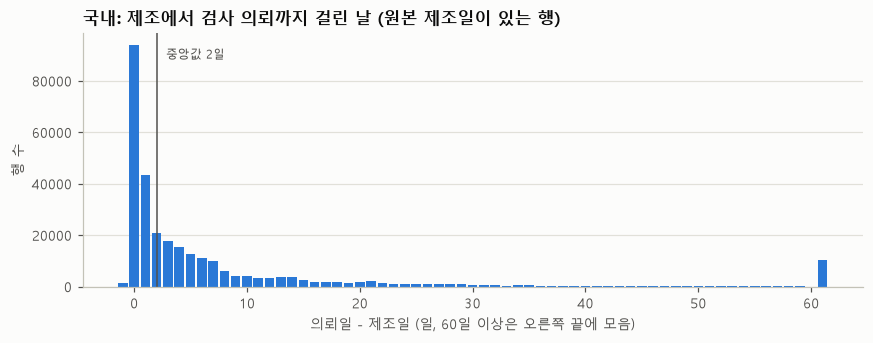

In [41]:
DATE_COLS = {'mnfctur_de_raw': '제조일(원본)', 'reqest_de': '의뢰일', 'rcept_de': '접수일', 'pick_de': '채취(수거)일',
             'inspct_begin_de': '검사시작일', 'inspct_end_de': '검사종료일', 'inspct_compt_de': '검사완료일',
             'distb_de': '유통일(distb_de)', 'valid_tmlmt': '유효기한(숫자)'}
fill = pd.DataFrame({lab: dfx.groupby('국내해외', observed=True)[c].apply(lambda s: round(s.notna().mean() * 100, 1))
                     for c, lab in DATE_COLS.items()}).T
fill.columns = [f'{c} 채움률(%)' for c in fill.columns]
display(fill)

dom = dfx[dfx['국내해외'] == '국내']
gaps = pd.DataFrame([
    gap_days(dom, 'reqest_de', 'mnfctur_de_raw', '의뢰일 − 제조일'),
    gap_days(dom, 'rcept_de', 'reqest_de', '접수일 − 의뢰일'),
    gap_days(dom, 'inspct_compt_de', 'rcept_de', '검사완료일 − 접수일'),
    gap_days(dom, 'inspct_end_de', 'inspct_begin_de', '검사종료일 − 검사시작일'),
    gap_days(dom, 'distb_de', 'mnfctur_de_raw', '유통일(distb_de) − 제조일'),
    gap_days(dom, 'distb_de', 'reqest_de', '유통일(distb_de) − 의뢰일'),
]).set_index('구간')
display(gaps)
print('valid_tmlmt(유효기한) 값 분포:', dom['valid_tmlmt'].describe(percentiles=[.25, .5, .75]).round(1).to_dict())

d = (dom['reqest_de'] - dom['mnfctur_de_raw']).dt.days.dropna()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(d.clip(-1, 61), bins=np.arange(-1.5, 62.5, 1), color=C1, rwidth=0.85)
ax.axvline(d.median(), color=INK2, linewidth=1)
ax.annotate(f'중앙값 {d.median():.0f}일', (d.median(), ax.get_ylim()[1] * 0.9), xytext=(6, 0), textcoords='offset points', fontsize=8, color=INK2)
ax.set_xlabel('의뢰일 - 제조일 (일, 60일 이상은 오른쪽 끝에 모음)')
ax.set_ylabel('행 수')
ax.set_title('국내: 제조에서 검사 의뢰까지 걸린 날 (원본 제조일이 있는 행)')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

📊 **결과**
- **국내 채취(수거)일은 사실상 0%** 입니다. 채취일은 수입 건(84%)에만 있습니다.
- 원본 제조일이 있는 국내 행에서 **의뢰일 − 제조일은 중앙값 2일**(25% 0일, 75% 7일, 95% 37일)입니다.
- 접수일은 의뢰일과 같은 날이고, **접수에서 검사 완료까지 중앙값 9일**입니다.
- `distb_de`(유통일)는 국내 30% 행에 있고, 제조일 이후 중앙값 44일(75% 241일)입니다. 품목제조대장의 유통기한 일수와 비교하면 **유통기한 날짜**로 보입니다 (6-3절에서 확인).
- `valid_tmlmt`(유효기한)는 국내 2.5% 행에만 있고 값이 1\~수십의 숫자(중앙값 10)라 날짜가 아닙니다.

💬 **첨언 — 메모 P3 "언제 검사했나, 수거기간이 의미 있나"**
- 국내 데이터에는 "공무원이 수거한 날"이 없고, 의뢰일이 수거일 역할을 합니다. 검사 시점은 의뢰일 기준으로 보면 됩니다.
- 리스테리아는 정성검사(있다/없다)라, 의뢰 후 시험까지 며칠 동안의 증식은 판정을 거의 바꾸지 않습니다. 이 간격은 예측 피처보다 **데이터 품질 점검용**(비정상 지연 탐지)으로 쓰는 것이 맞습니다 (추정, ❓ 확인 필요).
- 제조일이 있는 행은 대부분 **제조 직후(1주 이내)에 검사**됩니다. 업체가 출하 전·직후 자가검사를 맡기는 구조와 맞습니다.

❓ **나박사님께**: 리스테리아 정성시험에서 의뢰부터 시험 착수까지의 지연(냉장 보관 며칠)이 결과에 영향을 줄 수 있습니까? (위음성·위양성 가능성)

### 4-4. 품목별 제조 → 의뢰 간격과 유통기한 — "유통기한 2일이면 수거일 ≈ 제조일인가" (메모 P3, 5, 23)

🔎 품목제조대장(`t_prdlst_mnf_ledg`)의 유통기한 문구를 붙여 일수로 바꾸고, 품목별 제조→의뢰 간격과 함께 봅니다.
품목제조번호가 있는 국내 행만 연결됩니다.

In [42]:
# 품목제조대장: 보고번호당 1행 (삭제 안 된 최신 행 우선)
L = (ledg.assign(_ok=(ledg['del_yn'].fillna('N') == 'N').astype(int))
         .sort_values(['prdlst_report_no', '_ok', 'last_updt_dtm'], ascending=[True, False, False])
         .drop_duplicates('prdlst_report_no').set_index('prdlst_report_no'))
k_raw = dfx['prdlst_mnfctur_sttemnt_no'].astype('string')
k_dig = k_raw.str.replace(r'\D', '', regex=True)
m_raw = k_raw.isin(L.index).fillna(False).to_numpy(dtype=bool)
m_dig = k_dig.isin(L.index).fillna(False).to_numpy(dtype=bool)
dfx['ledg_key'] = np.where(m_raw, k_raw.astype(object), np.where(m_dig, k_dig.astype(object), None))
dfx = dfx.drop(columns=[c for c in ['pog_daycnt', 'prsrv_distb_stdr_cn', 'mnf_cnd_cn', 'frmlc_mtrqlt'] if c in dfx.columns])
dfx = dfx.join(L[['pog_daycnt', 'prsrv_distb_stdr_cn', 'mnf_cnd_cn', 'frmlc_mtrqlt']], on='ledg_key')


def shelf_days(s):
    '''유통기한 문구 → 일수 (개월=30일, 년=365일, 시간=1/24일). 해석 불가면 NaN'''
    if not isinstance(s, str):
        return np.nan
    t = s.replace(' ', '')
    for pat, mul in [(r'(\d+(?:\.\d+)?)개월', 30), (r'(\d+(?:\.\d+)?)년', 365), (r'(\d+)일', 1), (r'(\d+)시간', 1 / 24)]:
        m = re.search(pat, t)
        if m:
            return float(m.group(1)) * mul
    return float(t) if re.fullmatch(r'\d+', t) else np.nan


dfx['유통기한일수_대장'] = dfx['pog_daycnt'].map(shelf_days)
in_ledg = dfx['ledg_key'].notna()
print(f"품목제조대장 연결: {in_ledg.sum():,}행 (국내의 {in_ledg[dfx['국내해외'] == '국내'].mean():.1%}), 검출 {dfx.loc[in_ledg, 'pos'].sum()}건 = 전체 검출의 {dfx.loc[in_ledg, 'pos'].sum() / P:.1%}")
print(f"유통기한 문구를 일수로 바꾼 비율: {dfx.loc[in_ledg, '유통기한일수_대장'].notna().mean():.1%}  (예: {dfx.loc[in_ledg, 'pog_daycnt'].value_counts().head(4).index.tolist()})")

g = dfx[(dfx['국내해외'] == '국내') & dfx['mnfctur_de_raw'].notna()].copy()
g['간격'] = (g['reqest_de'] - g['mnfctur_de_raw']).dt.days
by = g.groupby('train_prdlst_nm', observed=True)['간격'].agg(
    행수='size', p25=lambda s: s.quantile(.25), 중앙값='median', p75=lambda s: s.quantile(.75), p95=lambda s: s.quantile(.95))
by['대장 유통기한 중앙값(일)'] = g.groupby('train_prdlst_nm', observed=True)['유통기한일수_대장'].median()
ok = g['유통기한일수_대장'].notna()
by['간격≤유통기한 비율(%)'] = ((g.loc[ok, '간격'] <= g.loc[ok, '유통기한일수_대장'])
                          .groupby(g.loc[ok, 'train_prdlst_nm'], observed=True).mean().mul(100).round(1))
by = by.rename(columns={'p25': '간격 p25(일)', '중앙값': '간격 중앙값(일)', 'p75': '간격 p75(일)', 'p95': '간격 p95(일)'})
by.sort_values('행수', ascending=False).head(15)

품목제조대장 연결: 203,496행 (국내의 32.4%), 검출 224건 = 전체 검출의 11.4%
유통기한 문구를 일수로 바꾼 비율: 91.0%  (예: ['제조일로부터 12개월', '제조일로부터 6개월', '제조일로부터 60일', '제조일로부터 12개월까지'])


,행수,간격 p25(일),간격 중앙값(일),간격 p75(일),간격 p95(일),대장 유통기한 중앙값(일),간격≤유통기한 비율(%)
train_prdlst_nm,,,,,,,
식육가공품 및 포장육,72518,0.0,3.0,7.0,22.00,180.0,99.6
기타기준규격외,57761,1.0,3.0,12.0,158.00,360.0,100.0
유가공품류,54813,1.0,3.0,8.0,27.00,35.0,98.9
즉석식품류,32274,0.0,0.0,0.0,4.00,2.0,98.7
알가공품류,21152,0.0,1.0,4.0,14.00,60.0,99.5
빙과류,18407,1.0,5.0,13.0,44.00,360.0,99.5
"정액,수정란,종란",7426,0.0,1.0,4.0,127.00,7.0,100.0
조리식품 등,6137,0.0,0.0,0.0,2.00,90.0,81.8
기타식품류,5688,0.0,0.0,3.0,37.00,2.0,99.1


📊 **결과**
- 품목제조대장은 국내 행의 약 1/3 에 연결되지만, **검출의 11% 남짓만** 이 범위에 있습니다 (검출이 몰린 공정시료·팽이버섯은 품목제조번호가 없음).
- 즉석식품류는 제조 당일 의뢰(중앙값 0일), 식육가공품·유가공품은 중앙값 3일로 대부분 **유통기한보다 훨씬 이른 시점**에 검사됩니다.

✅ **결론 — "유통기한 2일이면 수거일(의뢰일) ≈ 제조일로 봐도 되나"**: **됩니다.** 의뢰일은 유통기한 안에 있으므로 오차는 최대 유통기한 일수입니다.
일반화하면 **"의뢰일로 대체한 기준일의 오차 상한 = 그 제품의 유통기한 일수"** 입니다. 유통기한이 7일 이하인 제품은 의뢰일을 제조일 대신 써도 기상 결합에 문제가 작고, 수개월짜리(냉동·실온) 제품은 쓰면 안 됩니다.

💬 **첨언** — 원본 제조일이 없는 행이라도 `distb_de`(유통기한 날짜)와 대장 유통기한 일수가 둘 다 있으면 **제조일 ≈ 유통기한 날짜 − 유통기한 일수**로 복원할 수 있습니다. 복원식은 제조일이 있는 행으로 먼저 검증해야 합니다.

### 4-5. 수입 날짜 흐름 — 선적 → 입항 → 창고 반입 → 접수 → 검사 (메모 12, 15, 22')

🔎 수입 행의 `cntc_sys_key2`(수입 접수번호)로 수입 LIMS 를 붙여 선적일이 무엇인지, 각 단계가 며칠 걸리는지 봅니다.

수입 행 47,642 중 수입 LIMS 연결 99.6%
date_basis=선적일 행에서 parquet 기준일 = 수입 LIMS 선적일: 100.00%
수입 행의 원본 제조일 채움률: 0.28%


,n,p05,p25,중앙값,p75,p95,평균,음수(%)
구간,,,,,,,,
입항일 − 선적일,47067,1.0,1.0,5.0,32.0,55.0,18.0,0.00
창고반입일 − 입항일,47431,0.0,1.0,2.0,3.0,8.0,7.7,0.11
수입신고 접수일 − 입항일,47431,1.0,3.0,5.0,10.0,30.0,9.5,0.00
검사 의뢰일(식약처 LIMS) − 선적일,47067,3.0,6.0,17.0,43.0,75.0,28.3,0.00
검사완료일 − 검사요청일,42347,5.0,6.0,8.0,10.0,14.0,8.4,0.00
유통시작일(distb_bgn_de) − 선적일,46888,-85.0,29.0,180.0,401.0,712.0,1769.7,19.29
유통종료일 − 유통시작일,42148,0.0,0.0,0.0,0.0,730.0,82.7,0.00


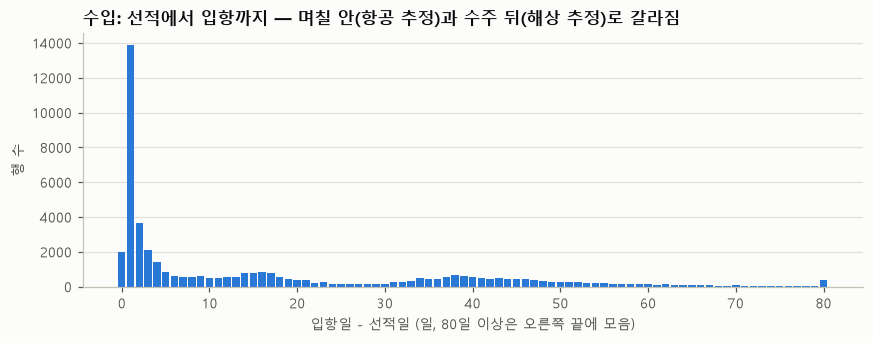

In [43]:
SC = ['shipng_de', 'entrpt_de', 'wrhous_carry_de', 'rcept_de', 'inspct_reqst_de', 'inspct_cmptn_de', 'distb_bgn_de', 'distb_end_de',
      'inspct_kind', 'inspct_kind_dtl', 'mnf_nation_nm', 'dclr_prduct_dvs', 'upper_prdlst_nm', 'prpos_nm', 'test_result']
S = sorg.sort_values('lims_seq').drop_duplicates('rcept_no').set_index('rcept_no')[SC].add_prefix('s_')
ov = dfx[dfx['국내해외'] == '해외'].join(S, on='cntc_sys_key2')
for c in [c for c in ov.columns if c.startswith('s_') and c.endswith('_de')]:
    ov[c] = pd.to_datetime(ov[c])
print(f"수입 행 {len(ov):,} 중 수입 LIMS 연결 {ov['s_inspct_kind'].notna().mean():.1%}")
sb = ov[ov['date_basis'] == '선적일']
print(f"date_basis=선적일 행에서 parquet 기준일 = 수입 LIMS 선적일: {(sb['mnfctur_de'] == sb['s_shipng_de']).mean():.2%}")
print(f"수입 행의 원본 제조일 채움률: {ov['mnfctur_de_raw'].notna().mean():.2%}")

ogaps = pd.DataFrame([
    gap_days(ov, 's_entrpt_de', 's_shipng_de', '입항일 − 선적일'),
    gap_days(ov, 's_wrhous_carry_de', 's_entrpt_de', '창고반입일 − 입항일'),
    gap_days(ov, 's_rcept_de', 's_entrpt_de', '수입신고 접수일 − 입항일'),
    gap_days(ov, 'reqest_de', 's_shipng_de', '검사 의뢰일(식약처 LIMS) − 선적일'),
    gap_days(ov, 's_inspct_cmptn_de', 's_inspct_reqst_de', '검사완료일 − 검사요청일'),
    gap_days(ov, 's_distb_bgn_de', 's_shipng_de', '유통시작일(distb_bgn_de) − 선적일'),
    gap_days(ov, 's_distb_end_de', 's_distb_bgn_de', '유통종료일 − 유통시작일'),
]).set_index('구간')
display(ogaps)

d = (ov['s_entrpt_de'] - ov['s_shipng_de']).dt.days.dropna()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(d.clip(0, 80), bins=np.arange(-0.5, 81.5, 1), color=C1, rwidth=0.85)
ax.set_xlabel('입항일 - 선적일 (일, 80일 이상은 오른쪽 끝에 모음)')
ax.set_ylabel('행 수')
ax.set_title('수입: 선적에서 입항까지 — 며칠 안(항공 추정)과 수주 뒤(해상 추정)로 갈라짐')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

In [44]:
display(rate_by(ov, 's_inspct_kind'))
display(rate_by(ov, 's_dclr_prduct_dvs'))
display(rate_by(ov, 's_mnf_nation_nm', top=12))
rate_by(ov, 's_upper_prdlst_nm', top=12)

,건수,검출,검출률(%),검출비중(%),리프트
s_inspct_kind,,,,,
무작위표본,25980,65,0.25,52.0,0.95
정밀,21402,60,0.28,48.0,1.07
NaN,211,0,0.00,0.0,0.00
현장,40,0,0.00,0.0,0.00
서류,9,0,0.00,0.0,0.00


,건수,검출,검출률(%),검출비중(%),리프트
s_dclr_prduct_dvs,,,,,
축산물,38002,82,0.216,65.6,0.82
수산물,8004,43,0.537,34.4,2.05
가공식품,1421,0,0.000,0.0,0.00
NaN,211,0,0.000,0.0,0.00
건강기능식품,4,0,0.000,0.0,0.00


,건수,검출,검출률(%),검출비중(%),리프트
s_mnf_nation_nm,,,,,
이탈리아,7619,31,0.407,24.8,1.55
스페인,2257,18,0.798,14.4,3.04
중국,2430,12,0.494,9.6,1.88
대만,1097,12,1.094,9.6,4.17
일본,1341,10,0.746,8.0,2.84
미국,8641,8,0.093,6.4,0.35
호주,1453,6,0.413,4.8,1.57
프랑스,6809,4,0.059,3.2,0.22
대한민국,123,4,3.252,3.2,12.39


,건수,검출,검출률(%),검출비중(%),리프트
s_upper_prdlst_nm,,,,,
치즈류,15046,22,0.146,17.6,0.56
햄류,2127,20,0.940,16.0,3.58
황새치,646,12,1.858,9.6,7.08
자연치즈,4019,10,0.249,8.0,0.95
소고기,210,10,4.762,8.0,18.15
참다랑어,2096,8,0.382,6.4,1.45
눈다랑어,961,8,0.832,6.4,3.17
돼지고기,309,7,2.265,5.6,8.63
양념육류,1809,5,0.276,4.0,1.05


📊 **결과**
- 수입 행의 99.6%가 수입 LIMS 와 연결되고, **선적일 기준일 = 수입 LIMS 선적일(`shipng_de`) 100%** 입니다.
- 수입 행에는 **원본 제조일이 거의 없습니다.**
- 선적 → 입항은 중앙값 5일이지만 1일 부근(항공 추정)과 2주\~2달(해상 추정)로 갈라집니다. 선적 → 식약처 LIMS 의뢰는 중앙값 17일(75% 43일)입니다.
- 수입 LIMS 의 **유통시작일은 대부분 선적일보다 뒤**(중앙값 약 180일)이고 유통종료일과 같은 경우가 많습니다. 이름과 달리 **유통기한(소비기한) 날짜**로 보입니다 (추정).
- 수입 검사종류는 무작위표본과 정밀이 비슷하게 섞였고 검출률도 비슷합니다. 신고 구분은 축산물(치즈·햄 포함)과 수산물(냉동 다랑어·황새치 등)이 대부분입니다.

💬 **첨언 — 메모 12·15·22'**
- **선적일** = 수출국에서 배·비행기에 실은 날입니다. 제조일이 아닙니다. 수입신고서에는 "제조일자 또는 유통기한"을 적는데, 이 DB 에는 유통기한 쪽만 남은 것으로 보입니다.
- 수입품의 **수확일·제조일은 DB 에 없습니다.** 알 수 있는 것은 제조국, 해외제조업소, 선적·입항일, 유통기한 날짜, 검사 종류입니다.
- 선적일 이전 60일 창은 "해외 창고·운송 중"의 날씨이고, 국내 기상과는 관계가 없습니다. 사용자가 나박사님께 드리려던 질문 2("선적일 기준 행은 국내 기상 연결이 무의미하니 제거")와 같은 결론입니다. 다만 **제거보다는 기상 피처만 빼고 수입 전용 변수(제조국·검사종류·품목)로 따로 다루는 편**이 활용 가치가 큽니다.

🗄️ **모델팀께**: 수입 LIMS 의 `distb_bgn_de`/`distb_end_de` 는 유통기한(소비기한) 날짜가 맞습니까? 수입신고서의 제조일자가 저장된 컬럼이 따로 있습니까?

### 4-6. 기준일 fallback 은 이대로 괜찮나 (메모 27)

✅ **결론**

| 기준일 출처 | 실체 | 행 비중 | 이 날짜로 기상 창을 만들면 |
|---|---|---|---|
| 제조일 | 포장 표시 제조일 | 43.8% | 제조 전후 공장 주변 날씨. 가공식품 오염(공장 내부)과는 약하게만 연결 |
| 의뢰일 | 업체·공무원이 검사 맡긴 날 | 49.3% | 제조일보다 보통 0\~7일 늦음. 유통기한이 긴 제품은 수개월 늦을 수 있음. 원물·공정시료가 많음 |
| 선적일 | 수출국 선적일 | 7.0% | 해외 운송 중. 국내 기상과 무관 |

- fallback 은 "결측 없는 날짜 하나"를 만드는 공학적 선택이라, 아플라톡신 모델에서 쓴 방식과 같습니다. 하지만 리스테리아에서는 **세 사건이 섞인 한 컬럼**을 그대로 기상 창의 끝점으로 쓰면 행마다 뜻이 달라집니다.
- 역설적으로 **기상과 관련 있을 만한 원물·현장 검체는 제조일이 없어 의뢰일 기준**이고, 제조일이 있는 행은 기상 영향이 작은 포장 가공식품입니다.

**권고 (모델팀·나박사님 확인 전 초안)**
1. 날짜 컬럼을 하나로 합치지 말고 **원본 제조일 / 의뢰일 / 선적일 / 유통기한 날짜를 따로** 보관하고, `date_basis` 를 피처 또는 층화 변수로 둡니다.
2. 기상 창은 **국내 × (원본 제조일 있음, 또는 유통기한 7일 이하)** 행에만 만들고, 나머지는 계절(월) 정도만 씁니다.
3. 제조일 없는 행은 **유통기한 날짜 − 유통기한 일수**로 제조일을 복원할 수 있는지 먼저 검증합니다.
4. 수입 행은 국내 기상 창을 만들지 않습니다.

❓ **나박사님께**: 리스테리아에서 기상과 연결할 "사건 날짜"는 제조일·수확일 중 무엇이어야 합니까? 원물(버섯·채소)은 수확 후 며칠 안에 의뢰된다고 보고 의뢰일 직전 창(예: 7\~14일)을 써도 됩니까?

---
## 5. 데이터 이해 ③ — 어디서: 주소와 위경도 (메모 19, 0, 8, 29)

### 5-1. 주소 출처별 의미와 검출률

🔎 `addr_source` 별로 검출률, 제조사명 결측률, 제조일 기준 비율을 봅니다.

In [45]:
a = dfx.groupby('addr_source', observed=True).agg(
    건수=('pos', 'size'), 검출=('pos', 'sum'),
    제조사명결측률=('mnfctur_cmpny_nm', lambda s: s.isna().mean() * 100),
    제조일기준비율=('date_basis', lambda s: (s == '제조일').mean() * 100),
    자가품질위탁비율=('검사목적', lambda s: (s == '자가품질위탁검사').mean() * 100),
    검사목적_기타비율=('검사목적', lambda s: (s == '기타').mean() * 100))
a = a.round(1)
a.insert(2, '검출률(%)', (a['검출'] / a['건수'] * 100).round(3))
a['검출비중(%)'] = (a['검출'] / P * 100).round(1)
a.sort_values('건수', ascending=False)

,건수,검출,검출률(%),제조사명결측률,제조일기준비율,자가품질위탁비율,검사목적_기타비율,검출비중(%)
addr_source,,,,,,,,
제조사소재지,327704,486,0.148,0.2,60.4,48.4,25.7,24.7
업소주소,292719,1348,0.461,98.8,31.4,10.8,82.8,68.5
해외제조업소,47440,125,0.263,71.5,0.0,0.0,0.0,6.3
인허가대장,8674,10,0.115,99.4,70.4,89.8,5.3,0.5


📊 **결과** — 검출의 약 2/3 가 **'업소주소'** 행에서 나옵니다. 업소주소 행은 제조사명이 거의 다 비어 있고 검사목적 '기타'가 대부분입니다. 제조사소재지 행은 제조사명이 거의 다 있고 자가품질위탁검사가 많습니다.

| 주소 출처 | 이 주소가 가리키는 곳 (추정 포함) | 국내 기상 결합 |
|---|---|---|
| 제조사소재지 | 의뢰서에 적힌 제조사 주소 — 공장일 수도, 본사일 수도 있음 | 가공식품의 제조 장소로는 타당 |
| 인허가대장 | 품목제조번호로 찾은 허가 제조소 주소 (가장 정확) | 타당 |
| 업소주소 | 검사를 맡긴 업체 주소. 자체의뢰면 그 업체(제조소·농가), 수거검사면 수거한 업소일 수 있음 | 경로에 따라 다름 |
| 해외제조업소 | 해외 공장 주소 | 국내 기상 불가 |
| 검사기관 | 시험실 위치 — parquet 에서는 제외됨 | 부적절 |

🗄️ **모델팀께**: '업소주소'(원본 `entrps_adres`)는 검사를 의뢰한 업체입니까, 시료를 수거한 업소입니까? 수거검사와 자체의뢰에서 뜻이 달라지는지 확인해 주세요.

### 5-2. 좌표는 얼마나 정밀한가 (메모 19)

🔎 DB 의 좌표 매칭 수준(`geo_match_level`)을 주소 출처별로 봅니다.

In [46]:
gm = dfx.assign(매칭수준=dfx['geo_match_level'].fillna('(해외·없음)').astype(str).str.replace(r'_fixed\d*', '', regex=True))
display(pd.crosstab(gm['addr_source'], gm['매칭수준'], margins=True, margins_name='합계'))
print(f"좌표 고유값 수: {dfx[['lat', 'lon']].drop_duplicates().shape[0]:,}  / 행 {N:,}")
dfx.groupby('국내해외', observed=True)[['lat', 'lon']].describe().T.round(2)

매칭수준,(해외·없음),eupmyeondong,manual,sido,sigungu,합계
addr_source,,,,,,
업소주소,41,253700,61,735,38182,292719
인허가대장,0,8433,0,0,241,8674
제조사소재지,176,310153,0,753,16622,327704
해외제조업소,47431,9,0,0,0,47440
합계,47648,572295,61,1488,55045,676537


좌표 고유값 수: 6,670  / 행 676,537


국내해외              국내        해외
lat count  628895.00  47642.00
    mean       36.68     35.79
    std         0.98     22.24
    min        33.23    -53.35
    25%        35.95     35.05
    50%        36.97     42.94
    75%        37.46     47.09
    max        38.49     70.24
lon count  628895.00  47642.00
    mean      127.40     23.58
    std         0.70     81.49
    min       124.72   -157.91
    25%       126.92     -2.20
    50%       127.20      9.45
    75%       127.59    106.70
    max       130.84    178.47

📊 **결과** — 국내 좌표는 85%가 **읍면동 단위 대표 좌표**이고, 8%는 시군구 단위입니다. 67만 행이 6,670개 좌표로 모입니다. 해외 좌표는 해외제조업소 주소를 지오코딩한 값입니다.

💬 **첨언 — 메모 19 "위경도 기준이 어디인가"**
- 위경도는 **주소 출처가 가리키는 장소(제조사·업체·해외 공장)의 법정동 대표점**입니다. 재배지·양식장·목장이 아닙니다.
- 최근접 기상 관측소(ASOS 약 100곳, 농업기상 219곳)에 붙이면 결국 수\~수십 km 반경의 지역 기상입니다. 같은 시군구 안이면 공장/본사 구분의 영향은 작습니다.

### 5-3. 기후를 붙일 수 있는 대상은 얼마나 되나 (메모 0, 8, 29)

🔎 "국내 × 원물/최소가공 × 수확\~검사 간격이 짧은 것에만 기후를 붙인다"는 가설을 따를 때 남는 표본 크기를 셉니다.

In [47]:
dom_m = dfx['국내해외'] == '국내'
raw_m = dfx['대분류'].isin(['농산물(원물)', '축산물(원물)', '수산물(원물)'])
enoki_m = dfx['검체성격'] == '팽이버섯'
gap7 = (dfx['reqest_de'] - dfx['mnfctur_de_raw']).dt.days.le(7)
short_m = gap7 | dfx['유통기한일수_대장'].le(7)
raw_ext_m = dfx['원물구분'].isin(['① 원물 코드(A·B)', '② 기준규격외 코드 + 원물 이름'])   # 3-6-2절
mush_m = dfx['원물유형'].eq('버섯') | dfx['train_prdlst_nm'].astype(str).eq('버섯류')
SC5 = {
    '국내 전체': dom_m,
    '국내 × 원물 코드(A·B)': dom_m & raw_m,
    '국내 × 원물 코드 + 기준규격외 속 원물 이름 (3-6-2)': dom_m & raw_ext_m,
    '  └ 위에서 버섯 제외': dom_m & raw_ext_m & ~mush_m,
    '  └ 위에서 채소·과일·농산물만 (노지 농산물 후보)': dom_m & raw_ext_m & ~mush_m & dfx['원물유형'].isin(['채소', '과일', '농산물']),
    '국내 × 원본 제조일 있음 × 의뢰까지 7일 이내': dom_m & gap7,
    '국내 × 가공식품(C) × (7일 이내 또는 유통기한 7일 이하)': dom_m & dfx['대분류'].eq('가공식품') & short_m,
    '해외(수입) 전체 — 국내 기상 결합 불가': ~dom_m,
}
sc5 = pd.DataFrame({k: {'건수': int(m.sum()), '검출': int(dfx.loc[m, 'pos'].sum())} for k, m in SC5.items()}).T
sc5['검출률(%)'] = (sc5['검출'] / sc5['건수'] * 100).round(3)
sc5

,건수,검출,검출률(%)
국내 전체,628895,1844,0.293
국내 × 원물 코드(A·B),3533,27,0.764
국내 × 원물 코드 + 기준규격외 속 원물 이름 (3-6-2),53784,688,1.279
└ 위에서 버섯 제외,46211,248,0.537
└ 위에서 채소·과일·농산물만 (노지 농산물 후보),22108,8,0.036
국내 × 원본 제조일 있음 × 의뢰까지 7일 이내,226425,516,0.228
국내 × 가공식품(C) × (7일 이내 또는 유통기한 7일 이하),174369,238,0.136
해외(수입) 전체 — 국내 기상 결합 불가,47642,125,0.262


📊 **결과** — 국내 원물 코드(A·B)만 남기면 검출이 27건입니다. 3-6-2절에서 찾은 기준규격외 속 원물까지 넣으면 53,784행·검출 688건으로 늘지만, 버섯을 빼면 46,211행·검출 248건, 노지 농산물 후보인 채소·과일(농산물 코드 포함)만 남기면 22,108행에 검출 8건입니다.

💬 **첨언**
- 도메인상 기후가 의미 있는 대상(원물)과 **학습 가능한 양성 수**가 충돌합니다.
- 팽이버섯은 **시설 재배**라 강우·토양 경로가 대부분 차단됩니다. 국내 연구에서도 오염원은 재배사 내부(바닥, 균 긁기 공정)였습니다 (8-3절). 기후 피처를 붙일 원물은 사실상 **노지 농산물·원유·양식 수산물**로 더 좁아집니다 (추정).
- 센터의 아플라톡신 모델에서도 기상 시계열 원값의 중요도는 모두 0.04 미만이었고, 1차 식품 분류(0.30)·수분활성도(0.24)·기상 파생변수 '연속 무강수 일수'(0.24)가 상위였습니다 (7-4절).

✅ **결론 — 메모 0·8** — 메모에서 예로 든 수입 냉동 원료 식품처럼 기상과 무관한 행은 사용자가 규칙으로 식별하면 됩니다 (`src_route=overseas`, `date_basis=선적일`, 보존온도 냉동, 유통기한 긴 가공식품). 다만 **행을 지우지 말고 기상 피처만 비우는 방식**을 권합니다. 이 행들에는 검출이 적지 않고, 기상 외 변수로 설명할 몫이 있습니다.

❓ **나박사님께**: 국내 원물 중 토양·관개수·강우 경로가 실제로 중요한 품목은 무엇입니까(노지 잎채소? 원유? 양식 수산물)? 팽이버섯 같은 시설 재배 원물에도 외부 기상을 붙일 근거가 있습니까?

---
## 6. 도메인 대조 — 리스테리아 발생 과정과 데이터 맞춰 보기 (메모 P10, 2, 5', 6, 7, 11, 16, 25, 26)

### 6-1. 발생 단계별로 필요한 정보 vs 우리 데이터 (메모 11, 25, 26, 2, 6, 7, 16)

✅ 4장에서 확인한 채움률을 단계별로 정리했습니다.

| 단계 | 리스테리아 관점에서 필요한 정보 | 시간 정보 | 장소 정보 | 판단 |
|---|---|---|---|---|
| ① 원료 생산·수확·어획·집유 | 토양·물·분변 노출, 수확 시점 기상 | **없음** | **없음** (수입은 제조국만) | 원물 기상 인과를 추적하기 어려움 |
| ② 원료 보관·운송·입고 | 냉장/냉동, 기간, 입고일 | **구조화된 컬럼 없음** | **없음** | 제조단계 조사 테이블(1-2절 ⑤)에 입고·보관 서술이 일부 있음. 원료명·원산지는 원재료 테이블 |
| ③ 제조·가공 | 가열·살균 여부, 가열 후 취급 공정, 공장 위생 | 원본 제조일 43.8% (국내 47.1%) | 제조사소재지·인허가대장 | 가열/RTE 는 품목·제품명으로 규칙화 필요 (6-4절) |
| ④ 포장·보관 기준 | 보존온도, 유통기한 | 유통기한 날짜 국내 30% | - | 품목제조대장 연결분만 (국내 1/3) |
| ⑤ 해외 → 국내 운송 (수입) | 운송 온도·기간 | 선적·입항·창고반입 99% | 해외제조업소 | 운송 온도는 없음 |
| ⑥ 유통 | 유통 중 온도 남용, 경과 기간 | 없음 | 없음 | 검사 시점 상태만 |
| ⑦ 수거·의뢰·검사 | 검사 이유, 시료 상태 | 의뢰일 100%, 국내 접수·검사완료 100% | 업소주소(경로에 따라 다름) | **검사목적 98.9%**(원본 LIMS 연결분 전부), 시료상태는 국내 2.6% |

💬 **첨언 — 메모 2·6·7·16·25 (원재료)**
- **구조화된 원재료 입고일·수확일·보관 상태 컬럼은 DB 에 없습니다.** 원료명·원산지는 정의서 밖 원재료 테이블에, 입고·보관 서술은 제조단계 조사 테이블에 있습니다 (1-2절 ⑤, 리스테리아 행과 연결은 미확인). 식품이력추적관리는 영유아식 등 일부 의무 품목만 원재료 입고 정보를 남기고, 리스테리아 위험 품목(훈제연어·치즈·햄·김밥)은 대부분 자율 등록입니다 (8절).
- 완제품 검사 결과만으로 **원료 유래인지 공장 환경 유래인지 구분할 수 없습니다.** 구분하려면 원료·환경·완제품 균주의 유전형 비교가 필요합니다.
- 가열 제품이라면 원료 원산지(해외 재배 원료 포함)는 오염과 거의 무관하고, 비가열 제품에서만 원료 오염이 남습니다. 그래서 "해외 원재료로 국내에서 가공한 식품"(메모 16)은 **원료가 아니라 국내 가공 공정(가열 여부·가열 후 취급)** 으로 설명하는 것이 맞습니다.

🗄️ **모델팀께**: 1-2절 ⑤의 원재료 테이블 `ba_data_info.lcns_ledg_hist_rawmtrl` 을 리스테리아 행의 품목제조번호와 이을 수 있습니까? 이력 순번(`hist_ordno`)은 어느 시점 기준으로 골라야 합니까?

### 6-2. 냉동·냉장 식품이 진짜 검출률이 높나 (메모 5')

🔎 세 가지 근거로 봅니다. ① 원본 LIMS 의 시료상태 코드(IM11), ② 품목제조대장 유통기한 문구의 보존온도 표기, ③ 식육가공품 안에서의 비교.

In [48]:
print('① 시료상태 코드 (원본 LIMS)')
display(rate_by(dfx, ['국내해외', '시료상태'], sort='index'))

txt = (dfx['pog_daycnt'].fillna('') + ' ' + dfx['prsrv_distb_stdr_cn'].fillna('')).str.replace(r'\s+', '', regex=True)
fro, chi, roo = txt.str.contains('냉동|-18'), txt.str.contains('냉장|0~10|-2~10|10℃이하|5℃이하'), txt.str.contains('실온|상온|직사광선')
dfx['보존온도_대장'] = np.select([~in_ledg, fro & ~chi & ~roo, chi & ~fro & ~roo, roo & ~fro & ~chi, fro | chi | roo],
                            ['(대장 미연결)', '냉동', '냉장', '실온', '냉장·냉동 함께 표기'], '표기 없음')
print('② 품목제조대장 보존온도 표기 (국내, 대장 연결분)')
display(rate_by(dfx[in_ledg], '보존온도_대장', sort='n'))
print('③ 식육가공품 및 포장육 안에서')
rate_by(dfx[in_ledg & dfx['train_prdlst_nm'].eq('식육가공품 및 포장육')], '보존온도_대장', sort='n')

① 시료상태 코드 (원본 LIMS)


건수    검출  검출률(%)  검출비중(%)   리프트
국내해외 시료상태                                     
국내   (결측)  612401  1813   0.296     92.1  1.02
     냉동      1582    10   0.632      0.5  2.17
     냉장     11853    20   0.169      1.0  0.58
     실온      3059     1   0.033      0.1  0.11
해외   (결측)    7423    10   0.135      0.5  0.46
     냉동     15475    67   0.433      3.4  1.49
     냉장     18106    40   0.221      2.0  0.76
     실온      6638     8   0.121      0.4  0.41

② 품목제조대장 보존온도 표기 (국내, 대장 연결분)


,건수,검출,검출률(%),검출비중(%),리프트
보존온도_대장,,,,,
표기 없음,128118,93,0.073,41.5,0.66
냉장,33972,40,0.118,17.9,1.07
냉장·냉동 함께 표기,25016,64,0.256,28.6,2.32
실온,8331,0,0.000,0.0,0.00
냉동,8059,27,0.335,12.1,3.04


③ 식육가공품 및 포장육 안에서


,건수,검출,검출률(%),검출비중(%),리프트
보존온도_대장,,,,,
표기 없음,32216,70,0.217,35.7,0.80
냉장·냉동 함께 표기,17645,60,0.340,30.6,1.25
냉장,13671,40,0.293,20.4,1.07
냉동,5527,26,0.470,13.3,1.73
실온,2817,0,0.000,0.0,0.00


📊 **결과**
- 시료상태가 기록된 행에서는 **냉동 > 냉장 > 실온** 순입니다 (해외 냉동 0.43%, 냉장 0.22%, 실온 0.12%). 그러나 **국내 행의 97%는 시료상태가 비어** 있습니다.
- 품목제조대장 표기로 봐도 냉동 표기 제품이 냉장 표기보다 높고, **실온 표기 제품은 0건**입니다. 식육가공품 안에서도 같은 순서입니다.

💬 **첨언**
- 문헌상 **냉장 RTE 가 가장 위험**하고 냉동은 "생존하지만 증식하지 않음"입니다. 이 데이터에서 냉동이 더 높게 나온 이유는 냉동 원물(수입 다랑어·식육)과 냉동 식육가공품(원료육·양념육)이 **비가열 원료**인 경우가 많기 때문으로 보입니다 (추정). 온도 자체보다 **"가열 공정이 있느냐"** 가 먼저 작동하고 있을 수 있습니다.
- 실온 제품이 0인 것은 멸균·레토르트·건조 제품이기 때문입니다. 이것은 확실한 규칙 변수로 쓸 수 있습니다.

✅ **결론** — "냉동·냉장이 실온보다 높다"는 맞고, "냉장이 냉동보다 높다"는 이 데이터로는 확인되지 않습니다. 보존온도는 **가열 여부와 함께** 봐야 합니다.

❓ **나박사님께**: 냉동 식육가공품·수입 냉동 수산물의 검출률이 냉장 제품보다 높게 나옵니다. 원료가 비가열이라서라고 해석해도 됩니까? 시료상태 코드(냉장/냉동/실온)는 제품 보존 기준입니까, 검사기관 도착 시 상태입니까?

### 6-3. 유통기한이 짧으면 불검출에 유리한가 — 유가공품 사례 (메모 P1, P2, 5)

🔎 원본 LIMS 의 유통기한 날짜(`distb_de`) − 원본 제조일로 유통기한 일수를 만들고, 품목제조대장 일수와 맞는지 확인한 뒤 품목별로 봅니다.

In [49]:
dfx['유통기한일수_LIMS'] = (dfx['distb_de'] - dfx['mnfctur_de_raw']).dt.days
both = dfx['유통기한일수_LIMS'].notna() & dfx['유통기한일수_대장'].notna()
agree = ((dfx.loc[both, '유통기한일수_LIMS'] - dfx.loc[both, '유통기한일수_대장']).abs() <= 3).mean()
print(f"distb_de − 제조일 vs 대장 유통기한 일수: 비교 {both.sum():,}행, 상관 {dfx.loc[both, ['유통기한일수_LIMS', '유통기한일수_대장']].corr().iloc[0, 1]:.2f}, 차이 3일 이내 {agree:.0%}")

bins = [-1e9, 7, 30, 90, 365, 1e9]
labels = ['7일 이하', '8~30일', '31~90일', '91~365일', '365일 초과']
dfx['유통기한구간'] = pd.cut(dfx['유통기한일수_LIMS'].fillna(dfx['유통기한일수_대장']), bins, labels=labels)
items = ['유가공품류', '식육가공품 및 포장육', '즉석식품류', '알가공품류', '수산가공식품류']
sub = dfx[dfx['train_prdlst_nm'].isin(items) & dfx['유통기한구간'].notna()]
gg = sub.groupby(['train_prdlst_nm', '유통기한구간'], observed=True)['pos'].agg(건수='size', 검출='sum')
cellv = (gg['검출'].astype(str) + ' / ' + gg['건수'].map('{:,}'.format)).unstack().reindex(columns=labels)
print('칸 = 검출 / 건수')
cellv

distb_de − 제조일 vs 대장 유통기한 일수: 비교 92,453행, 상관 0.80, 차이 3일 이내 52%
칸 = 검출 / 건수


유통기한구간,7일 이하,8~30일,31~90일,91~365일,365일 초과
train_prdlst_nm,,,,,
수산가공식품류,4 / 87,1 / 248,0 / 111,"2 / 1,023",4 / 792
식육가공품 및 포장육,"16 / 2,785","48 / 12,871","50 / 25,049","74 / 31,689","19 / 3,651"
알가공품류,"0 / 3,081","0 / 6,522","0 / 11,023","0 / 3,688","0 / 1,497"
유가공품류,"0 / 2,474","1 / 33,531","1 / 8,937","2 / 16,563","0 / 2,753"
즉석식품류,"15 / 17,045",0 / 624,0 / 469,"1 / 1,612",0 / 623


📊 **결과**
- `distb_de` − 제조일은 대장 유통기한 일수와 잘 맞아서, `distb_de` 는 **유통기한 날짜**로 봐도 됩니다.
- **유가공품은 유통기한 구간과 상관없이 검출이 거의 0**입니다. 식육가공품은 모든 구간에서 검출이 나오며, 유통기한이 길다고 뚜렷하게 높아지지는 않습니다.

💬 **첨언 — 메모 P1 "유가공품은 유통기간이 짧아 불검출에 유리"**
- 데이터로 보면 유가공품의 낮은 검출률은 유통기간보다 **살균 공정** 때문일 가능성이 큽니다. 우유·발효유·아이스크림은 살균한 원유로 만들고, 남는 위험은 살균 후 충전 라인 재오염뿐입니다.
- 유가공품 중 위험이 남는 것은 **자연치즈(특히 수입 연성치즈)** 입니다. 수입 치즈류에서 검출이 나온 것(4-5절)과 맞습니다.
- 유통기한과 검출의 관계는 **같은 가공 유형 안에서** 봐야 합니다. 서로 다른 유형을 섞으면 유형 차이가 기간 효과처럼 보입니다.

✅ **결론** — "유통기간이 짧아서"가 아니라 "살균해서" 낮은 것으로 봅니다. 유통기한은 **냉장 RTE 안에서만** 증식 기회 변수로 의미가 있습니다 (문헌: EU 규정은 유통기한 5일 미만 RTE 를 "증식 불가"로 분류, 8-2절).

### 6-4. "가열 여부 × 그대로 섭취(RTE) × 보존온도" 룩업 초안 — 나박사님 검토용 (메모 3, 4, 10)

🔎 info.md 의 핵심 가설("가열 여부 × 그대로 섭취 여부가 가장 강한 피처")을 품목 단위 표로 만들었습니다.
**아래 분류는 일반 식품 지식에 따른 초안(추정)** 이며, 나박사님이 틀린 칸을 고쳐 주시면 피처로 씁니다.

In [50]:
LOOKUP = [
    # 품목, 가열·살균 공정, 그대로 섭취(RTE), 주 보존온도, 비고
    ('식육가공품 및 포장육', '혼합', '혼합', '냉장·냉동', '햄·소시지=가열 후 슬라이스(재오염 위험) / 포장육·양념육=비가열·가열조리용 / 생햄=비가열 RTE → 세분 필요'),
    ('유가공품류', '살균', '예', '냉장(치즈·발효유)·실온(멸균유)', '자연치즈(특히 비살균·연성)는 예외적으로 위험'),
    ('즉석식품류', '혼합', '예', '냉장·실온', '김밥·도시락·샌드위치: 조리 후 조립(재오염), 생채소 토핑'),
    ('알가공품류', '살균·가열', '일부', '냉장', '액란은 살균, 구운란은 가열'),
    ('빙과류', '살균(원료)', '예', '냉동', '살균 원료 사용, 냉동 유통'),
    ('수산가공식품류', '혼합', '혼합', '냉장·냉동', '훈제연어=비가열 RTE / 어묵=가열 / 젓갈=비가열·고염'),
    ('수산물', '없음', '일부(횟감)', '냉장·냉동', '수입 냉동 다랑어·황새치 횟감 포함'),
    ('축산물', '없음', '대부분 아니오(육회 예외)', '냉장·냉동', '생육(가열조리용)'),
    ('버섯류', '없음', '아니오(가열조리용 표시)', '냉장', '팽이버섯은 2020년부터 "가열조리용" 표시'),
    ('채소류', '없음', '일부(샐러드·새싹)', '냉장·실온', ''),
    ('과일류', '없음', '예', '냉장·실온', ''),
    ('조리식품 등', '가열(조리)', '예', '실온·냉장', '식품접객업소 조리식품'),
    ('기타식품류', '혼합', '혼합', '혼합', '품목 세분 필요'),
    ('음료류', '살균', '예', '실온·냉장', ''),
    ('조미식품', '가열·고염', '예', '실온', ''),
    ('기타기준규격외', '해당 없음', '해당 없음', '해당 없음', '공정시료·환경검체 등 → 식품 속성으로 분류 불가, 별도 층'),
    ('정액,수정란,종란', '해당 없음', '해당 없음', '해당 없음', '실제로는 팽이버섯 수출검사·재배장 환경검체 → 별도 층'),
]
lk = pd.DataFrame(LOOKUP, columns=['train_prdlst_nm', '가열·살균 공정(초안)', '그대로 섭취 RTE(초안)', '주 보존온도(초안)', '비고']).set_index('train_prdlst_nm')
st = rate_by(dfx, 'train_prdlst_nm')[['건수', '검출', '검출률(%)']]
lk.join(st, how='left').sort_values('검출', ascending=False)

,가열·살균 공정(초안),그대로 섭취 RTE(초안),주 보존온도(초안),비고,건수,검출,검출률(%)
train_prdlst_nm,,,,,,,
기타기준규격외,해당 없음,해당 없음,해당 없음,"공정시료·환경검체 등 → 식품 속성으로 분류 불가, 별도 층",291813,791,0.271
"정액,수정란,종란",해당 없음,해당 없음,해당 없음,실제로는 팽이버섯 수출검사·재배장 환경검체 → 별도 층,28651,640,2.234
식육가공품 및 포장육,혼합,혼합,냉장·냉동,햄·소시지=가열 후 슬라이스(재오염 위험) / 포장육·양념육=비가열·가열조리용 / 생햄=비가열 RTE → 세분 필요,101045,323,0.320
수산물,없음,일부(횟감),냉장·냉동,수입 냉동 다랑어·황새치 횟감 포함,8473,46,0.543
즉석식품류,혼합,예,냉장·실온,"김밥·도시락·샌드위치: 조리 후 조립(재오염), 생채소 토핑",35322,45,0.127
유가공품류,살균,예,냉장(치즈·발효유)·실온(멸균유),자연치즈(특히 비살균·연성)는 예외적으로 위험,107022,40,0.037
수산가공식품류,혼합,혼합,냉장·냉동,훈제연어=비가열 RTE / 어묵=가열 / 젓갈=비가열·고염,4915,29,0.590
축산물,없음,대부분 아니오(육회 예외),냉장·냉동,생육(가열조리용),1731,28,1.618
버섯류,없음,아니오(가열조리용 표시),냉장,"팽이버섯은 2020년부터 ""가열조리용"" 표시",92,12,13.043


💬 **첨언**
- 이 표만으로도 "살균·가열 + 가열 후 취급 없음 → 거의 0", "비가열 원물·횟감·생육 → 높음", "가열 후 슬라이스·조립 → 중간"의 윤곽이 보입니다.
- 가장 큰 문제는 **식육가공품(검출 323건)이 한 칸에 섞여 있다는 점**입니다. 햄·소시지(가열 후 취급), 포장육·양념육(비가열), 생햄(비가열 RTE)을 나눠야 합니다. 원본 품목코드(`prdlst_code`, 식품공전 5단계)와 제품명으로 나눌 수 있습니다.
- 가공식품 규격 자체에 "살균제품", "가열하지 않고 섭취하는 냉동식품"처럼 이 구분이 들어 있는 경우가 많습니다. 식품공전 정의문(`t_prdlst_cl.dfn`)에서 키워드로 뽑을 수 있는지 다음 단계에서 확인합니다.

❓ **나박사님께**: 위 룩업 표의 "가열·살균 / RTE / 보존온도" 칸 중 틀린 곳을 고쳐 주십시오. 특히 식육가공품 및 포장육을 어떤 단위(햄·소시지 / 포장육 / 양념육 / 생햄·발효소시지)로 나누는 것이 리스테리아 관점에서 맞습니까?

---
## 7. 리서치팀(전문가) 자료 종합 (메모 1, 8, 29, 31)

### 7-1. 위해요소별 중요인자 데이터출처 — 리스테리아 시트

🔎 D열의 빨간 글씨(수집 대상 주요 인자)만 뽑아 데이터원별로 정리합니다. 여러 조각으로 칠해진 빨간 글씨는 ` · ` 로 이었습니다.

In [51]:
import openpyxl
from openpyxl.cell.rich_text import CellRichText, TextBlock

RED = 'FFFF0000'


def _rgb(font):
    try:
        v = font.color.rgb if (font is not None and font.color is not None) else None
        return v if isinstance(v, str) else None
    except Exception:
        return None


def plain(v):
    if v is None:
        return ''
    if isinstance(v, CellRichText):
        return ''.join(b.text if isinstance(b, TextBlock) else str(b) for b in v)
    return str(v)


def red_text(cell):
    v = cell.value
    if not isinstance(v, CellRichText):
        return plain(v) if _rgb(cell.font) == RED else ''
    parts, cur = [], ''
    for b in v:
        is_red = (_rgb(b.font) == RED) if isinstance(b, TextBlock) else (_rgb(cell.font) == RED)
        txt = b.text if isinstance(b, TextBlock) else str(b)
        if is_red:
            cur += txt
        elif cur:
            parts.append(cur)
            cur = ''
    if cur:
        parts.append(cur)
    return ' · '.join(' '.join(p.split()).strip(' ,') for p in parts if p.strip(' ,'))


wb = openpyxl.load_workbook(ROOT / '리서치팀문서' / '위해요소별_중요인자_데이터출처.xlsx', rich_text=True)
ws = wb['리스테리아 모노사이토제네스']
src = pd.DataFrame([{
    '데이터명': ' '.join(plain(ws.cell(r, 2).value).split()),
    '제공기관': ' '.join(plain(ws.cell(r, 3).value).split()),
    '빨간 글씨 (수집 대상 인자)': red_text(ws.cell(r, 4)),
    '현재상태': plain(ws.cell(r, 6).value).split('\n')[0].strip(),
    '생산주기': plain(ws.cell(r, 7).value).strip(),
} for r in range(2, ws.max_row + 1)])
src

,데이터명,제공기관,빨간 글씨 (수집 대상 인자),현재상태,생산주기
0,종관기상관측(ASOS),기상청,"기온, 강수, 바람 · 일조",확보(API),"시간, 일"
1,방재기상관측(AWS),기상청,"기온, 강수, 바람",확보(API),"분, 시간, 일"
2,농업기상 관측 조회(AAOS),기상청,"기온, 풍속 · 토양수분 · 일조",확보(CSV),"시간, 일"
3,농업기상 기본관측 조회,농촌진흥청 국립농업과학원,"기온, 최고기온, 최저기온 · 풍향, 풍속 · 강수량, 일조시간, 일사량",확보(API),"시간, 일"
4,농업기상 상세관측 조회,농촌진흥청 국립농업과학원,"기온(40-50-150cm기준 최고, 최저) · 풍향(150-300-400cm, 1000cm), 최대풍속(150-300-1000cm), 강수량 · 일조시간, 일사량 · 지중온도(5-10-20cm) · 토양수분(%) · 풍향(150-300-1000cm · 토양수분(10-20-30cm)",확보(API),"10분, 시간, 일, 월"
5,토양검정 화학성 상세정보,농촌진흥청 국립농업과학원,산도(pH)유효인산(mg/kg · 유기물(g/kg),확보(API),수시
6,농업기상 농업용 미래상세 기후도,농촌진흥청 국립농업과학원,"기상요소(월강수량, 월평균기온, 월최고기온, 월최저기온)",확보(PDF),월
7,팜맵 기반 농업기상 조회,농림축산식품부 농림수산식품교육문화정보원,"기온(50-150-400cm), 풍향(150-300-1000cm), 풍속(150-300-1000cm) · 강수량, 토양수분값(10-20-30cm) · 일사량, 일조시간 · 일사량, 일조시간 · 풍향, 풍속, 강수량, 기온",확보(API),일
8,팜맵 기반 토양검정 조회,농림축산식품부 농림수산식품교육문화정보원,"산도, 유기물함량, 유효인산농도",확보(API),년
9,토양 수분량,한국수자원공사,토양수분량 관측단위(%),확보(CSV),일


📊 **결과** — 21개 데이터원은 **모두 기상·토양·대기·해양·지하수 같은 생산환경 자료**이고, 20개가 '확보' 상태입니다. 식품 자체(품목·공정·살균·포장·유통기한·보관온도)나 검사 행정에 관한 행은 **하나도 없습니다.**

💬 **첨언**
- 원본백업의 다른 세균 시트(살모넬라·병원성대장균 등)에는 검사 데이터·수입정보 행이 있는데 리스테리아 시트에는 없습니다. 리스테리아 시트가 상대적으로 덜 채워진 상태로 보입니다 (추정).
- 이 시트는 "어떤 품목에 이 환경 인자를 붙일지"를 말하지 않습니다. 원물 생산환경 인자를 가공식품·수입식품에까지 붙일지는 전문가 판단이 필요합니다.
- '확보'는 리서치팀이 API·파일 경로를 확보했다는 뜻이고, 모델팀 DB 에 적재됐다는 뜻은 아닙니다 (DB 에 있는 것: ASOS·농업기상·토양검정·에어코리아·국가별 기상).

### 7-2. 예측인자 정리 PPT — 우선순위와 우리 데이터 가용성

리서치팀 PPT(`리서치팀문서/예측인자 정리 ppt.jpg`)의 표를 옮기고, 이 노트북에서 확인한 가용성을 붙였습니다.

| 순위 | 인자 | 최적 / 한계 범위 (PPT) | 우리 데이터에서 | 품목 수준에서 변하나 |
|---|---|---|---|---|
| 1 | 수분활성도 | 0.97 / 0.90\~0.997 | 품목별 고정값 파일·DB(`t_aw_cl`) — 7-3절 | 품목 단위 고정값 |
| 1 | 온도(기온) | 30\~37℃ / −2\~45℃ | ASOS·농업기상 일자료 (국내 기준일 창) | 지역·날짜 |
| 3 | pH | 7.0 / 4.0\~9.6 | 품목별 고정값 파일 (결측 41%) | 품목 단위 |
| 4 | 염도 | - / ≤16% | 품목별 고정값 파일 (결측 23%) | 품목 단위 |
| 5 | 토양 온도 | 8\~15℃ / 8\~30℃ | ASOS 지중온도, 농업기상 | 지역·날짜 — 원물에만 의미 |
| 6 | 토양 수분 | - | 농업기상 토양수분(단일 깊이) | 원물에만 |
| 7 | 대기조성 | - | 에어코리아 NO2·CO·SO2 (CO2 는 없음) | 의미 불명확 |
| 8 | 토양 pH | 6.5\~7.0 / 5.0\~8.0 | 토양검정(법정동·연도) | 원물에만 |
| 9 | 강수 | - | ASOS·농업기상 | 원물에만 |
| 추가 | 식품 유형 | 가공방법·제조공정·섭취형태 | 품목코드·제품명·품목제조대장 → **6-4절 룩업 필요** | 핵심 |
| 추가 | 저장 및 유통 온도 | - | 시료상태(국내 2.6%), 대장 보존온도 표기(국내 1/3) — 6-2절 | 부분 |
| 추가 | 포장 유형 | 산소·이산화탄소 조건 | 대장 포장재질(재질만, 진공/MAP 구분 없음) | 거의 없음 |
| 추가 | 일조·일사 | 생산환경 오염 가능성 | ASOS·농업기상 | 원물에만 |
| 추가 | 수질 | 관개수·농업용수 | DB 에 없음 | 원물에만 |

💬 **첨언**
- 1·3·4순위(수분활성도·pH·염도)는 **품목이 정해지면 같이 정해지는 값**이라, 품목 변수와 정보가 겹칩니다. 7-3절에서 보듯 리스테리아 위험 품목 대부분이 이미 "생장 가능" 구간이라 변별력이 크지 않을 수 있습니다 (추정).
- 5\~9순위(토양·강수)는 원물 생산환경 인자인데, 원물 행은 품목코드 기준 1.8%, 제품명까지 봐도 국내 8.6%이고 그중 노지 채소·과일의 검출은 거의 없습니다 (3-6-2절).
- 오히려 PPT 의 **추가 인자(식품 유형·저장 온도·포장)** 가 이 데이터에서는 가장 설명력이 클 가능성이 높습니다.

❓ **나박사님께**: PPT 의 우선순위(수분활성도·온도·pH·염도 > 토양·대기·강수)는 "균의 생장"에 대한 순위로 이해했습니다. "검사에서 검출될 확률"에 대한 순위라면 식품 유형·가열 공정·보존 온도가 더 앞에 와야 하지 않습니까? 대기조성(7위)은 포장 내 기체(MAP)입니까, 대기 중 이산화탄소 농도입니까?

### 7-3. 수분활성도·수분함량·pH·염도 통합 파일

🔎 파일의 결측 정도와, 우리 데이터의 품목코드·품목명과 얼마나 맞는지 봅니다.

In [52]:
aw = pd.read_excel(ROOT / '리서치팀문서' / '통합_수분활성도_수분함량_식품pH_염도_최종.xlsx', sheet_name='값', dtype=str)
val_cols = ['수분활성도', '수분함량', '식품 pH', '염도']
print(f'{len(aw)}개 식품 (코드 첫 글자: {aw["PRDLST_CD"].str[0].value_counts().to_dict()})')
display((aw[val_cols].apply(lambda s: (s.isna() | s.str.strip().isin(['-', ''])).mean() * 100).round(1)).to_frame('결측(%)').T)

aw_codes = set(aw['PRDLST_CD'].dropna().str.strip())
aw_names = set(aw['KOR_NM'].dropna().str.strip())
cov = pd.DataFrame({
    '원본 품목코드(prdlst_code) 정확 일치': [dfx['prdlst_code'].astype(str).isin(aw_codes).mean() * 100],
    '학습용 품목코드(train_prdlst_code) 일치': [dfx['train_prdlst_code'].astype(str).isin(aw_codes).mean() * 100],
    '학습용 품목명(train_prdlst_nm) 이름 일치': [dfx['train_prdlst_nm'].astype(str).isin(aw_names).mean() * 100],
}, index=['행 기준 커버율(%)']).round(1)
display(cov)
risk = ['우유', '치즈', '가공치즈', '발효유', '아이스크림', '햄', '생햄', '소시지', '발효소시지', '양념육', '연어', '어묵', '젓갈', '즉석섭취식품', '두부', '팽이버섯']
aw[aw['KOR_NM'].isin(risk)].set_index('KOR_NM')[['PRDLST_CD'] + val_cols]

653개 식품 (코드 첫 글자: {'A': 314, 'C': 275, 'B': 64})


,수분활성도,수분함량,식품 pH,염도
결측(%),28.9,16.5,41.5,23.4


,원본 품목코드(prdlst_code) 정확 일치,학습용 품목코드(train_prdlst_code) 일치,학습용 품목명(train_prdlst_nm) 이름 일치
행 기준 커버율(%),36.8,50.5,50.5


,PRDLST_CD,수분활성도,수분함량,식품 pH,염도
KOR_NM,,,,,
팽이버섯,A0700600000000,>0.98,89~89.19,6.45,0.00762
연어,B0202030000000,≥0.98,75.8,6.1~6.3,0.2
아이스크림,C0302010100000,0.900~0.999,64.2,6.5,0~0.5
두부,C0306010000000,0.98,81.2,5.8~6.24,0
햄,C0316010100000,0.976,53.5-69.9,6.03~6.54,0.006176
생햄,C0316010200000,-,-,6~6.09,2.84734
소시지,C0316020100000,0.975,55.6,5.47,0.0054102
발효소시지,C0316020200000,0.887,31.6,5.42~6.49,2.84734
양념육,C0316050100000,0.93-0.98,-,6.5~7.0,0.10~2.06


📊 **결과** — 653개 식품에 대해 값이 있지만 수분활성도 29%, pH 42%가 비어 있습니다. 우리 데이터와는 **학습용 품목명 기준 행의 절반 정도**만 이름으로 맞습니다. 맞지 않는 큰 덩어리는 기준규격외(Z)·조리식품(G) 코드입니다.

💬 **첨언** — 위험 품목(우유·치즈·햄·소시지·연어·어묵·두부·팽이버섯)은 수분활성도 0.92 이상, pH 5\~7 로 대부분 **리스테리아 생장 가능 구간**입니다. 한계 밖이거나 경계인 것은 발효유(pH 3\~4)·젓갈(고염)·발효소시지·건조육 정도입니다.
그래서 이 값들은 연속 변수보다 **"생장 가능 / 경계 / 불가" 3단계 규칙 변수**(EU 규정의 pH 4.4·aw 0.92 기준 참고)로 쓰는 편이 낫습니다. DB `ba_data.t_aw_cl` 에도 같은 자료가 들어 있고 `aw_grade` 는 아플라톡신 기준 등급이라 그대로 쓰면 안 됩니다.

### 7-4. 센터 발표자료(예측모델 v3.1) — 센터가 기대하는 모델의 모양

센터 발표자료(`센터_발표자료_사업보고서/[통합본]예측모델_v3.1.pptx`)에서 리스테리아 모델 설계에 영향을 주는 부분만 옮겼습니다.

| 항목 | 발표자료 내용 (아플라톡신 기준) | 리스테리아에 주는 의미 |
|---|---|---|
| 최종 산출물 | **전국 254개 시군구 × 식품분류(가공식품은 3단계)** 별 부적합 확률, 4단계 위해도(관심 <0.3, 주의, 경고, 위험 ≥0.8), 현재\~D+10 예보 | 건 단위 분류기를 만들어도 **지역×식품분류×시기** 로 집계할 수 있어야 함 → 검사기관·업체 같은 "누가 검사했나" 변수는 지도에 못 씀 |
| 데이터 규모 | 식약처 LIMS 리스테리아 779,155건, 검출 2,118건 (0.27%) — 10개 위해요소 중 가장 낮음 | 우리 DB 765,891 / parquet 676,537 과 다름 → 기준 데이터 합의 필요 |
| 기준일 | 제조일 우선, 없으면 의뢰일 | 4-6절 문제 그대로 |
| 위치 | 제조회사 소재지 좌표 → 최근접 농업기상 관측소 | 5-1절: 업소주소 행의 뜻 확인 필요 |
| 기상 창 | 제조일 전 50·60·100일 비교 → 60일 채택 (LSTM 기준) | 리스테리아는 원물에만 짧은 창이 논리적 (4-6절) |
| 분할 | 학습 2015\~2024 / 검증 2025 / 테스트 2026 상반기 | 2020 팽이버섯이 학습 구간에 통째로 들어감 |
| 지표 | **Recall 최우선**, 검사 축소율 = 1 − (TP+FP)/전체 | 양성 0.29% 에서는 PR-AUC·상위 k% 리프트도 함께 보는 것이 좋음 |
| 성능 (아플라톡신 테스트) | CatBoost 가중치 모델 Recall 0.855, Precision 0.076, 축소율 29.15% | 검출률 6% 에서도 Precision 7.6% |
| 변수 중요도 (아플라톡신) | 1차 식품 분류 0.301, 연속 무강수 일수 0.240, 수분활성도 0.237, 저습도 일수 0.063, **기상 시계열 원값은 모두 0.04 미만** | 식품 분류가 1위. 기상은 파생변수로 만들었을 때만 상위 |

💬 **첨언** — 아플라톡신(곰팡이가 원료 저장 중 만드는 독소)도 식품 분류가 1위였습니다. 리스테리아는 검출률이 1/20 이고 오염이 공장 환경에서 많이 일어나므로, **식품 유형·검사 경로 변수의 비중이 더 커질 것**으로 예상합니다 (추정).

---
## 8. 문헌 조사 요약 (메모 P8, 22, 30, 31, 32)

2026-09-14 웹 검색 결과를 요약했습니다. **[확인]** = 원문·초록에서 수치 확인, **[2차]** = 기사·요약 자료에서 확인. 보고서에 인용하기 전에 원문을 한 번 더 확인하세요.

### 8-1. 검사 데이터로 부적합·검출을 예측한 사례

| 사례 | 데이터·양성률 | 방법 | 성능 | 근거 |
|---|---|---|---|---|
| 대만 국경검사 부적합 예측 (Foods, 2023, PMC10252765) | 국경검사 배치, 무작위 표본 부적합률 2.09% | 제품·검사이력·수입자·제조사·국가지표 68개, 7개 모델 배깅, SMOTE | Recall 31.9%, Precision 16.4%, AUC 0.70. 실제 적용 후 무작위 대비 적발률 약 7.8배 | [확인] |
| 중국 농산물 수거검사 (Front. Sustain. Food Syst., 2026) | 18만 건, 부적합 1.76% | 과거 부적합률, 포장, 기상, 유통단계, XGBoost + SMOTE | Recall 75.4%, AUC 0.74 | [확인] |
| EU RASFF 위험등급 (Front. Food Sci. Technol., 2026) | 22,643건 | XGBoost + SMOTE + 확률 보정 | AUC 0.76 | [확인] |
| 뉴욕 농업용수 리스테리아 (Front. Environ. Sci., 2021) | 371개 시료, 양성 10\~15% | 수질·기상·공간 피처, 불균형 처리 비교 | SMOTE + 랜덤포레스트 권고 | [확인] |
| 식약처 수입식품 AI 위험예측 (2024년 1월\~) | 7개 품목군 | 과거 부적합·검사정보·원재료·해외 기상 등 | 무작위표본검사 대상 선별에 사용, 성능 비공개 | [2차] |

💬 **첨언** — **검사 메타데이터로 리스테리아 검출을 예측한 직접 선행연구는 찾지 못했습니다.** 양성률이 우리보다 수 배\~수십 배 높은 사례도 Recall·AUC 가 높지 않습니다. 공통으로 강했던 피처는 **같은 업체·수입자·품목의 과거 부적합 이력**(시간 순으로 누적해 누수 방지)입니다.

### 8-2. 예측미생물학 — 리스테리아 영향 인자와 실험 과정 (메모 31)

| 주제 | 내용 | 근거 |
|---|---|---|
| 생장 한계 | 온도 −1.5\~45℃(최적 30\~37℃), pH 4.0\~9.6, 수분활성도 약 0.92 이상 — 리서치팀 PPT 값과 대체로 일치 | FSAI 팩트시트 [2차] |
| 냉장 증식 | 세대시간 0℃ 약 72시간, 6℃ 약 17시간 / 팽이버섯 4℃ 에서 약 9일 만에 100배 | Dorsa 1993 [확인], Upham & Markell 2025 [확인] |
| 냉동 생존 | 아이스크림 −20℃ 에서 36개월 생존 | Salazar 2020 [확인] |
| 가열 사멸 | D60℃ 약 2분 (60℃ 에서 균 90% 감소에 2분) | Dorsa 1993 [확인] |
| 증식 불가 기준 (EU 2073/2005) | pH ≤ 4.4, 또는 aw ≤ 0.92, 또는 pH ≤ 5.0 이면서 aw ≤ 0.94, 또는 **유통기한 5일 미만** RTE | EUR-Lex [2차] |
| 실험 과정 (challenge test) | 식품에 균 접종 → 4℃·10℃ 등 저장 → 날짜별 균 수 측정 → 1차·2차 생장 모델 적합 | 문헌 종합 |
| 실험 데이터 + ML | ComBase 생장 데이터로 XGBoost 생장 예측 (R² 0.75\~0.90) | Hiura 2021, Zhou 2026 [확인] |

💬 **첨언** — 실험 논문은 "이미 오염된 식품에서 균이 얼마나 자라나"를 다룹니다. 우리 타깃("검사에서 검출되나")에 식을 그대로 옮길 수는 없고, **품목별 "증식 가능/불가" 등급 변수**를 만드는 근거로 쓰는 것이 현실적입니다.

### 8-3. 국내 검출·회수 사례와 우리 데이터 대조 (메모 22, 30)

| 시기 | 품목 | 내용 | 근거 | 우리 데이터 |
|---|---|---|---|---|
| 2019-07 | 분쇄가공육제품 | 식약처 회수 알림 | [2차] | 식육가공품 검출과 방향 일치 |
| 2020-03 | 팽이버섯(수출) | 미국·캐나다 집단감염(2016\~2020, 48명) 원인으로 한국 제조사 지목, 이후 "가열조리용" 표시 | Pereira 2023 [확인], 농식품부 [2차] | **2020년 팽이버섯 검출 급증** (3-10절) |
| 2020-07 | 훈제연어 | 서울시 수거검사에서 4개 업체 11개 제품 검출, 3개 업체 6개 제품 회수. 원료는 노르웨이·칠레산 냉동연어 | [2차] | 제품명 '연어' 키워드 검출률은 평균의 약 10배 (3-8절) |
| 2023-05 | 훈제연어 슬라이스 | 회수 | [2차] | |
| 2024-07 | 닭고기 바베큐 제품 | 수거검사 검출, 회수 1등급 | [2차] | |
| 2021·2022·2025 | - | 웹 검색으로 회수 건을 확인하지 못함 (없다는 뜻이 아님) | - | 공공데이터포털 "식품의 회수 및 판매중지 정보" API 로 집계 필요 |

참고 수치: 국내 식품의 리스테리아 풀링 검출률 2.26%, 식육 8.32% (59개 연구 메타분석, IJFM 2024) [확인] / 국내 팽이버섯 농장 2,088시료 중 1.12% 양성, 바닥 스왑과 균 긁기 공정에서 높음 (Food Res. Int. 2025) [확인] / 인체 감염 신고 2021\~2024년 연 6\~11건 [2차].

💬 **첨언** — 공개 사례의 품목(팽이버섯·훈제연어·식육)은 우리 데이터의 검출 상위와 방향이 같습니다. 식정원이 가진 연도별 보고서·회수 목록(품목코드 포함)을 받으면 **연도×품목 사건 플래그**와 **외부 검증 셋**으로 쓸 수 있습니다.

---
## 9. 모델링 관점 정리 — 예측이 가능한가, 무엇을 예측할까 (메모 P6, P10, 0, 10, 17, 32)

### 9-1. 이 타깃이 뜻하는 것

`judge_result` 는 **"오염되었는가"가 아니라 "검사했을 때 검출되었는가"** 입니다. 무엇을 검사할지는 검사목적(업체 자체의뢰·수거·수입·HACCP)마다 다른 논리로 정해집니다.
따라서 모델은 필연적으로 **미생물학 + 검사 정책**을 함께 배웁니다. "예측 가능"을 "특정 제품의 오염 판정"으로 정의하면 어렵고, **"검사하면 검출될 위험의 순위를 매겨 검사 우선순위를 정하는 것"** 으로 정의하면 현실적입니다.

### 9-2. 대상 범위 선택지 — 표본 크기 비교

🔎 대상 범위를 바꿨을 때 남는 건수·검출·주요 검출 품목을 비교합니다.

In [53]:
off_m = dfx['검사목적'].isin(['수거검사', '수입검사', '모니터링검사'])
biz_m = dfx['검사목적'].isin(['자가품질위탁검사', '자가품질직접검사(영업자)', '식품안전관리인증검사', '품질검사', '기타'])
spec_m = dfx['검체성격'].isin(['공정시료', '환경검체'])
SCOPE = {
    '① 전체 (현재 parquet)': pd.Series(True, index=dfx.index),
    '② 공정시료·환경검체 제외 (제품명 휴리스틱)': ~spec_m,
    '③ ② + 팽이버섯 제외': ~spec_m & ~enoki_m,
    '④ 기준규격외(Z) 코드 전체 제외': ~dfx['대분류'].eq('기준규격외(검체)'),
    '⑤ 정부 감시검사만 (수거·수입·모니터링)': off_m,
    '⑥ 업체 의뢰 검사만 (자가품질·HACCP·품질·기타)': biz_m,
    '⑦ 국내 가공식품(C 코드)': dom_m & dfx['대분류'].eq('가공식품'),
    '⑧ 국내 원물 코드(A·B)': dom_m & raw_m,
    '⑧-2 국내 원물 확장 (A·B + 기준규격외 속 원물 이름, 3-6-2)': dom_m & raw_ext_m,
    '⑨ 수입 전체': ~dom_m,
}
rows = []
for k, m in SCOPE.items():
    sub = dfx[m]
    top3 = sub.loc[sub['pos'] == 1, 'train_prdlst_nm'].value_counts().head(3)
    rows.append({'범위': k, '건수': len(sub), '검출': int(sub['pos'].sum()), '검출률(%)': round(sub['pos'].mean() * 100, 3),
                 '양성 1건당 음성': round((len(sub) - sub['pos'].sum()) / max(sub['pos'].sum(), 1)),
                 '검출 상위 품목': ', '.join(f'{i}({v})' for i, v in top3.items())})
pd.DataFrame(rows).set_index('범위')

,건수,검출,검출률(%),양성 1건당 음성,검출 상위 품목
범위,,,,,
① 전체 (현재 parquet),676537,1969,0.291,343,"기타기준규격외(791), 정액,수정란,종란(640), 식육가공품 및 포장육(323)"
② 공정시료·환경검체 제외 (제품명 휴리스틱),545303,1629,0.299,334,"기타기준규격외(593), 정액,수정란,종란(517), 식육가공품 및 포장육(310)"
③ ② + 팽이버섯 제외,538870,1184,0.220,454,"기타기준규격외(575), 식육가공품 및 포장육(310), 정액,수정란,종란(102)"
④ 기준규격외(Z) 코드 전체 제외,355987,538,0.151,661,"식육가공품 및 포장육(323), 수산물(46), 즉석식품류(45)"
⑤ 정부 감시검사만 (수거·수입·모니터링),80849,191,0.236,422,"식육가공품 및 포장육(72), 수산물(44), 유가공품류(31)"
⑥ 업체 의뢰 검사만 (자가품질·HACCP·품질·기타),588465,1768,0.300,332,"기타기준규격외(791), 정액,수정란,종란(640), 식육가공품 및 포장육(249)"
⑦ 국내 가공식품(C 코드),294421,386,0.131,762,"식육가공품 및 포장육(294), 즉석식품류(45), 수산가공식품류(29)"
⑧ 국내 원물 코드(A·B),3533,27,0.764,130,"버섯류(12), 축산물(9), 수산물(3)"
"⑧-2 국내 원물 확장 (A·B + 기준규격외 속 원물 이름, 3-6-2)",53784,688,1.279,77,"정액,수정란,종란(438), 기타기준규격외(223), 버섯류(12)"


📊 **결과와 💬 첨언**
- **①** 는 양성이 가장 많지만 팽이버섯 수출검사·공정시료·환경검체가 검출을 지배합니다. 품목·기상보다 "어떤 검체인가"를 배우게 됩니다.
- **②·③** 은 식품에 가깝게 정리한 범위입니다. 제품명 휴리스틱에 의존하므로 검사목적·품목코드 규칙으로 보강해야 합니다.
- **⑤ 정부 감시검사만** 은 산출물(시군구×식품분류 위해도)의 뜻과 가장 잘 맞지만 양성이 191건입니다.
- **⑦ 국내 가공식품** 은 검출이 식육가공품에 몰려 있어, 식육가공품 세분(6-4절)이 성패를 가릅니다.
- **⑧ 국내 원물 코드** 는 도메인상 기상과 가장 관련 있지만 양성이 너무 적습니다. 제품명으로 넓힌 **⑧-2** 는 양성이 수백 건이지만 팽이버섯·원료육·생선이 대부분입니다 (3-6-2절).
- **⑨ 수입** 은 국내 기상과 무관하고, 제조국·검사종류·품목 변수로 따로 모델링할 수 있습니다.

✅ **권고 (초안)** — 한 모델로 전부를 풀기보다 **층을 나누는 설계**를 권합니다.
1. **층 구분 변수**: 검사목적(정부 감시 / 업체 의뢰), 검체 성격(식품 / 공정·환경 검체), 국내/수입.
2. **1차 대상**: 식품 검체(③ 범위)에서 품목·가열·RTE·보존온도·유통기한·계절 변수로 모델을 만들고, 검사목적은 층화 변수로 둡니다.
3. **규칙 처리**: 검출이 구조적으로 0인 유형(살균·멸균·실온·건조, 알가공·빙과)은 사전확률로 처리합니다.
4. **기상**: 국내 원물·짧은 간격 행에서만 효과를 검증하고, 효과가 없으면 계절 변수만 남깁니다.
5. **수입**: 별도 모델 또는 별도 층 (제조국·해외제조업소 이력·검사종류·품목).

### 9-3. 누수와 데이터 분할에서 조심할 것

| 위험 | 이 데이터에서의 모습 | 대응 |
|---|---|---|
| 같은 접수 묶음 | 한 접수번호에 여러 시료(같은 날·같은 업체) | 접수번호(가능하면 업체) 단위 그룹 분할 |
| 업체·기관 집중 | 검출 상위 5개 기관이 약 63%, 검출 업소 722곳 중 상위 50곳이 46% | 기관·업체를 피처로 쓸지 결정 전에 그룹 분할로 성능 확인 |
| 사건 연도 | 2020 팽이버섯 급증 | 시간 순 분할 + 사건 플래그, 팽이버섯 포함/제외 두 버전 비교 |
| 결측 = 검체 종류 | 제조일·제조사명 결측, 결과값 형식이 검체 종류와 겹침 | 피처로 쓰면 "검사 종류"를 배움 → 층화 변수로만 |
| 과거 이력 피처 | 업체·품목의 과거 검출 이력은 강하지만 미래 정보가 섞이기 쉬움 | 기준일 이전 데이터로만 누적 계산 |

### 9-4. 평가 지표와 베이지안 네트워크 (메모 32)

- **지표**: 센터 기준(Recall 최우선 + 검사 축소율)을 따르되, 양성 0.29% 에서는 **PR-AUC, 상위 k% 선별 시 검출 농축비(리프트), 확률 보정**을 함께 보고합니다. 층(검사목적·국내/수입)별 성능도 따로 봅니다.
- **베이지안 네트워크(BN)**: 리스테리아 BN 은 대부분 **위해평가(오염 → 섭취 → 발병)** 용이고, 검사 데이터로 검출을 분류한 사례는 찾지 못했습니다. 적용 조건은 다음과 같습니다.
  1. 변수 5\~10개, 각 변수는 2\~4개 상태로 이산화 (예: 가열 있음/없음, 냉장/냉동/실온, 유통기한 ≤7일/8\~90일/>90일).
  2. 구조(DAG)는 **전문가가 지정**하고 확률표만 데이터로 학습. 양성 0.29% 에서 구조 학습은 믿기 어렵습니다.
  3. 부모 상태 조합마다 양성이 수십 건은 있어야 확률표가 안정적입니다.
  4. 검사 맥락 노드(검사목적·연도)는 오염 노드와 분리해 둡니다.
- **권고 순서**: GBM(가중치) 베이스라인 → SHAP 상위 5\~8개 변수 확인 → 그 변수로 전문가 DAG BN 구성 → 같은 분할·지표로 비교. BN 이 성능에서 근접하면 설명력 때문에 채택하고, 크게 뒤지면 **설명용 보조 모델**로 둡니다.

초안 DAG (나박사님 검토용, 화살표 = 영향 방향):
```
원료군(농·축·수산·유)   → 가열·살균 공정
가열·살균 공정          → 가열 후 취급(슬라이스·조립) → [검출]
보존온도 + 유통기한     → 증식 기회 → [검출]
계절·기상 (국내 원물만) → 원료 오염 → [검출]
검사목적(층) + 연도     → [검출]   ※ 오염 노드와 분리해 해석
```

---
## 10. 결론 · 질문 목록 · 다음 할 일

### 10-1. 메모 항목별 답과 상태

| 메모 | 답 (요약) | 상태 |
|---|---|---|
| P1·P2 유가공품은 유통기간이 짧아 불검출에 유리? | 유통기한 구간과 무관하게 거의 0. 이유는 **살균**일 가능성이 큼. 위험은 자연치즈 | 데이터로 답함 + ❓ |
| P3 언제 검사, 수거기간 의미, 2일 유통기한이면 수거일=제조일? | 국내 채취일은 없음. 의뢰일이 검사 시점. 제조→의뢰 중앙값 2일. **오차 상한 = 유통기한 일수**라 짧은 제품은 의뢰일≈제조일 가능 | 데이터로 답함 |
| P4·16 원료(예: 수입 연어)의 냉동·입고 시점, 해외 원료 국내 가공품 | 냉동·입고 시점은 알 수 없음. 원료명·원산지는 정의서 밖 원재료 테이블에 있으나 연결 미확인. 모델에는 가열 여부·RTE 룩업이 더 직접적 | 부분 답함 + 🗄️ + ❓ |
| P5 어디서 많이 나오나 | 팽이버섯(수출검사·재배장), 공정·환경 검체, 식육(원료육·정육·양념육), 횟감(연어·광어), 수입 치즈·햄. 유가공·알가공·빙과는 거의 0 | 데이터로 답함 |
| P6·17 많이 나오는 것만 예측? | 상위 3개 품목이 검출 89%지만 2개는 검체 코드. 식품 층을 먼저 분리하고, 구조적 0 유형은 규칙 처리 | 데이터로 답함 + ❓ |
| P7·P9 어떻게 들어오나 (비즈니스 이해) | 검출 82%가 **검사목적 '기타'(업체 자체의뢰)**, 수거검사는 3.4%. 기관·검체 종류가 경로마다 다름 | 데이터로 답함 + 🗄️ |
| P8·31 논문 | 검사 데이터로 리스테리아 검출을 예측한 직접 선행연구 없음. 예측미생물학 인자는 PPT 와 일치 | 문헌 |
| P10 발생 과정과 맞춰 보기 | 원료 생산·보관·유통 단계 정보는 없음. 제조 이후와 검사 단계만 있음 (6-1절 표) | 데이터로 답함 |
| 0 수입 냉동연어 등 기상 무관 → 제거? | 규칙으로 식별 가능. **행은 두고 기상 피처만 비우기** 권고 | 데이터로 답함 + ❓ |
| 1 DataGrip 이 전부? | 아님. 같은 DB 안에 검사목적·시료상태·날짜·유통기한·수입 정보가 더 있고, 정의서 밖 ba_data_info 에 원재료·제조/유통단계 조사·기준규격 테이블도 있음 (1-2). 외부 자료는 리서치팀 목록 | 데이터로 답함 + 🗄️ |
| 2 원재료 입고·오염, 독소? | 구조화된 입고일 없음(원료명·원산지는 정의서 밖 테이블). 원료 유래/환경 유래 구분 불가. **독소형이 아니라 감염형**이라 질문을 "가열로 죽었나 / 가열 후 재오염인가"로 바꿔야 함 | 문헌 + ❓ |
| 3·4 가공식품·원물과의 관계 | 비가열·원물·생식 계열이 높고 살균·가열·건조는 거의 0 (품목명 기준으로도 포장육 3.8%, 알가열제품·발효유·빙과 0건, 3-6-1). 원물은 코드 기준 1.8%, 제품명까지 보면 국내 8.6% (3-6-2) | 데이터로 답함 |
| 5 품목별 유통·보관기간 | 품목제조대장(국내 1/3 연결) 유통기한 문구와 LIMS 유통기한 날짜로 계산 가능 | 데이터로 답함 |
| 5' 냉동·냉장 검출률 | 냉동 > 냉장 > 실온(실온 0). 국내 시료상태는 97% 결측. 가열 여부와 섞여 있음 | 부분 답함 + ❓ |
| 6·7·25 원재료·보관상태 | 구조화 컬럼은 없음. 원재료 테이블과 제조단계 조사 텍스트가 정의서 밖 스키마에 있음 (1-2) | 🗄️ |
| 8 기후와 가공품 | 직접 관계 약함. 아플라톡신 모델도 기상 원값 중요도 낮음. 가공품은 계절 변수 정도 | 문헌·자료 + ❓ |
| 9·10·21·24 규모와 8분할 | 원물 코드 1.8%(제품명 포함 국내 8.6%), 가공식품 49%, 기준규격외 47%. 8분할에 '기준규격외' 층을 추가해야 해석 가능. 칸 안 품목별로는 국내 포장육 3.8%, 수입 소고기 5.5%·생햄 1.5%·냉동 횟감 참치류가 높고, 해외 농산물 칸은 0행 (3-6-1) | 데이터로 답함 |
| 11·26 전 과정 시공간 정보 | 수확·원료보관·유통 없음. 제조(43.8%)·검사(100%)·수입 운송(99%)만 있음 | 데이터로 답함 |
| 12 선적일 | 수출국 선적일 = 수입 LIMS `shipng_de` (100% 일치). 제조일 아님 | 데이터로 답함 |
| 13 의뢰일 | 검사 의뢰일 (주말 0.2%, 접수일과 같은 날) | 데이터로 답함 |
| 14 제조일 | 포장 표시 제조일. 원본은 43.8% 만 있고 비포장·현장 검체는 없음 | 데이터로 답함 |
| 15 수입식품 | 수입은 제조일·수확일 없음, 유통기한 날짜·선적·입항·검사종류·제조국 있음 | 데이터로 답함 |
| 18 품목별 검출률 | 3-2절 표 | 데이터로 답함 |
| 19 위경도 기준 | 주소 출처가 가리키는 곳(제조사·업체·해외공장)의 법정동 대표 좌표. 재배지 아님 | 데이터로 답함 + 🗄️ |
| 20 식품공전 상위 분류 | 있음. 코드 첫 글자 = 1단계, DB `statistic_prdlst_nm_1~4` | 데이터로 답함 |
| 22·30 보고서·최근 5년 사례 대조 | 팽이버섯·훈제연어·식육 사례는 방향 일치. 2021·22·25 회수 목록은 미확보 | 부분 답함 + ❓ |
| 22'·23·28 수확·제조·검사 간격 | 수확일 없음. 제조→의뢰 중앙값 2일(국내), 선적→의뢰 중앙값 17일(수입) | 데이터로 답함 |
| 27 기준일 fallback 이 맞나 | 세 사건이 한 컬럼에 섞임. 날짜를 따로 보관하고 기상 창은 조건부로 | 데이터로 답함 + ❓ |
| 29 원물의 토양·수질 영향 | 문헌상 강우·관개수·토양수분이 관련. 우리 데이터는 원물 표본이 적고 재배지 좌표가 없음 | 문헌 + ❓ |
| 32 베이지안 네트워크 | 조건부 가능 (변수 5\~10개, 전문가 DAG). GBM 과 비교해 설명용으로 | 문헌 + ❓ |

### 10-2. ❓ 나박사님(식품 전문가)께 드릴 질문 — 우선순위 순

**[상] 모델 범위를 정하는 질문**
1. 검출의 82%가 업체 자체의뢰(검사목적 '기타')이고, 공무원 수거검사는 3.4%(66건)입니다. 이 연구의 예측 대상은 **업체 검사를 포함한 전체**입니까, **정부 감시검사**입니까? 둘을 한 모델에 섞어도 됩니까? (2-2, 9-2절)
2. HACCP 공정시료(세척 전후·가열 전후·원료육)와 작업장 환경검체(바닥·장갑·컨베이어)는 예측 대상에서 빼야 합니까, "공장 환경 오염 신호"로 따로 쓸 가치가 있습니까? (3-3, 3-4절)
3. 2020년 팽이버섯 수출검사(검출의 약 1/4)는 제외해야 합니까, 별도 층으로 둬야 합니까? (3-10절)
4. 첨부한 **"가열·살균 / 그대로 섭취(RTE) / 보존온도" 룩업 표** 중 틀린 칸을 고쳐 주십시오. 식육가공품 및 포장육은 어떤 단위로 나누는 것이 리스테리아 관점에서 맞습니까? 포장육(생고기 절단·포장)은 3.8%(101/2,668)로 양념육(0.40%)의 약 10배, 햄·소시지(0.12\~0.17%)의 20배 이상이라 원물(식육)과 함께 봐야 하는지도 알려 주십시오. (3-6-1, 6-4절)
5. 리스테리아에서 기상을 붙일 대상은 **국내 × 원물(노지 채소·원유·양식 수산물) × 수확\~검사 간격이 짧은 것**으로 좁히는 것이 맞습니까? 팽이버섯처럼 시설 재배 원물에도 외부 기상을 붙일 근거가 있습니까? 원물 코드만 보면 국내 양성이 27건이고, 공장에 들어온 원물 검체까지 넣으면 수백 건이지만 채소·과일은 거의 0입니다. 공정 원물 검체를 "원물"로 봐도 되는지, 그래도 기상 효과를 검증할 가치가 있는지 알려 주십시오. (3-6-2, 5-3절)

**[중] 변수 해석**
6. 냉동 제품(수입 냉동 수산물, 냉동 식육가공품)의 검출률이 냉장 제품보다 높게 나옵니다. 원료가 비가열이기 때문으로 해석해도 됩니까? 수입 수산물 검출은 참다랑어·눈다랑어·황새치 같은 냉동 필렛 횟감에 몰려 있습니다. (6-2, 3-6-1절)
7. 유가공품의 검출이 유통기한과 무관하게 거의 0 입니다. "살균 때문"으로 보면 됩니까? 유가공품 중 위험이 남는 유형은 자연치즈(수입 연성치즈)뿐입니까? 치즈는 수입품 0.40%(17/4,296), 국내품 0.03%(1/3,543)로 차이가 큽니다. (6-3, 3-6-1절)
8. 훈제연어·생햄·연성치즈 같은 고위험 RTE 가 국내 검사에서는 평균 수준입니다. 국내 관리 수준 때문입니까, 검사 대상 선정 방식 때문입니까? (3-8절)
9. 해외·냉동 원료로 국내에서 가공한 식품(예: 훈제연어, 수입 원료육 가공품)의 오염 원인은 원료보다 국내 가공 환경으로 봐도 됩니까? 원료 원산지·냉동 이력을 따로 구할 가치가 있습니까? (3-9절)
10. 기상과 연결할 "사건 날짜"는 제조일·수확일 중 무엇이어야 합니까? 원물은 의뢰일 직전 7\~14일 창을 써도 됩니까? (4-6절)
11. PPT 우선순위(수분활성도·온도·pH·염도 > 토양·대기·강수)는 "균의 생장" 순위입니까, "검출 확률" 순위입니까? 대기조성(7위)은 포장 내 기체입니까, 대기 중 CO2 입니까? (7-2절)

**[하] 확인·자료 요청**
12. 리스테리아 규격(n=5, c=0, m=0/25g)이 적용되는 식품유형 목록과 2015\~2026년 개정 이력을 받을 수 있습니까? DB 의 공통 기준규격 테이블(1-2절 ⑤)에도 미생물 규격 컬럼이 있어, 모델팀 확인 후 데이터로 뽑아 대조할 수 있습니다.
13. 연도별 기획검사(팽이버섯·횟감·수출용 검사 등) 목록과 최근 5년 회수·부적합 목록(품목코드 포함)을 받을 수 있습니까? (3-11, 8-3절)
14. 결과가 '음성' 한 개로 적힌 행은 검체 1개 검사입니까, 5개 검사를 요약한 것입니까? 의뢰 후 시험 착수까지의 냉장 보관 지연이 결과에 영향을 줄 수 있습니까? (3-1, 4-3절)
15. 베이지안 네트워크를 시도한다면 9-4절 초안 DAG 의 구조와, 온도·유통기한 구간 경계값을 정해 주실 수 있습니까?

### 10-3. 🗄️ 모델팀(DB 담당)께 드릴 질문

1. 검사목적 코드(`inspct_purps_code`, IM02)의 **'기타'(IM02000007)** 는 어떤 경우에 입력됩니까? 검사목적·검사종류·의뢰시스템 코드를 ready_data 에 올리지 않은 이유가 있습니까? (2-2절)
2. 품목코드 **Z2700400000000 → '정액,수정란,종란'** 매핑 근거와, 팽이버섯·환경검체가 이 코드로 들어온 이유를 확인해 주세요. Z3800100000000(기타기준규격외)의 입력 기준도 알려 주세요. (3-3절)
3. `date_basis` 정의가 세 곳에서 다릅니다: 정의서 "(제조일/의뢰일/수거일)", fallback 식 "COALESCE(제조일, 의뢰일, 검사시작일)", 실제 값 "제조일/의뢰일/선적일". 최종 규칙은 무엇입니까? (4-1, 4-5절)
4. 행 수가 세 가지입니다: 발표자료 779,155 / DB 765,891 / parquet 676,537. parquet 에서 주소 출처 '검사기관' 행(86,696)을 뺀 것이 의도된 규칙입니까? 이 필터로 국내 수산물 원물은 4,334행 → 469행으로 줄고 양성률이 0.115% → 0.640%로 바뀝니다. (2-5, 3-6-1절)
5. '업소주소'(원본 `entrps_adres`)는 검사를 의뢰한 업체입니까, 시료를 수거한 업소입니까? (5-1절)
6. 수입 LIMS 의 `distb_bgn_de`/`distb_end_de` 는 유통기한 날짜가 맞습니까? 수입신고서 제조일자 컬럼이 따로 있습니까? 원본 LIMS 의 `valid_tmlmt`(유효기한)는 어떤 단위의 숫자입니까? (4-3, 4-5절)
7. 시료상태 코드(IM11 냉장/냉동/실온)는 제품 보존 기준입니까, 검사기관 도착 시 상태입니까? 국내 행에서 97% 비어 있는 이유가 있습니까? (6-2절)
8. 검사기관 코드표(기관명·유형: 지방청/보건환경연구원/민간 위탁기관)를 공식 자료로 받을 수 있습니까? (2-3절)
9. 정의서 밖 `ba_data_info` 의 **원재료(`lcns_ledg_hist_rawmtrl`)·제조단계 조사(`mnf_step_exam`)·유통단계 조사(`distb_step_exam`)·공통 기준규격(`t_cmmn_spec`)** 테이블을 리스테리아 분석에 써도 됩니까? 리스테리아 행과 잇는 키와 부하가 적은 조회 방법은 무엇입니까? (1-2절)
10. 그 밖에 정의서에 없는 스키마(weather_data, predict_data, staging_*, train_data)를 리스테리아에 써도 됩니까?
11. 수입 LIMS 리스테리아 행에 농산물(A) 품목코드가 한 건도 없습니다. 수입 농산물은 리스테리아 검사를 하지 않습니까, 다른 테이블·시험항목명으로 들어갑니까? (3-6-1절)
12. 같은 품목명에 14자리·20자리 코드와 C01·C02·C03 코드가 섞여 있습니다 (8칸 품목명 626개 ↔ 코드 1,192개). 코드 체계가 나뉜 기준은 무엇이고, 학습용 품목 단위는 코드와 품목명 중 무엇으로 합니까? (3-6-1절)

### 10-4. 다음 할 일 (체크리스트)

- [ ] 나박사님 질문 [상] 1\~5 먼저 여쭙기 → 모델 대상 범위(9-2절) 확정
- [ ] 모델팀 질문 1\~4 확인 → 기준 데이터(행 수·코드 매핑·기준일 규칙) 합의
- [ ] `collect_all.py` 수정: TEMP 테이블 대신 CTE 로 바꾸고, 공통코드 분류를 `ZIM*` → **`IM*`** 로 고치고(실제 코드 분류명), 검사목적·검사종류·의뢰시스템·유통기한 날짜 컬럼 추가
- [ ] 6-4절 룩업 표를 나박사님 검토본으로 확정 → 식육가공품 세분 규칙(원본 품목코드·제품명) 작성
- [ ] 날짜 컬럼 분리(원본 제조일·의뢰일·선적일·유통기한 날짜) + 제조일 복원식(유통기한 날짜 − 유통기한 일수) 검증
- [ ] 모델팀 확인 후 ba_data_info 원재료·제조단계 조사·기준규격 테이블의 리스테리아 연결률 측정 (공용 DB 부하가 적은 방식으로)
- [ ] 3-6-2절 원물 식별 규칙을 나박사님 의견(공정 원물 검체 포함 여부)으로 보정
- [ ] 모델팀 답변(질문 11·12)으로 품목 단위(품목명 / 품목코드)와 기준 행(parquet / DB 전체)을 정한 뒤 3-6-1절 품목별 양성률 다시 계산
- [ ] 기상 결합은 국내 × 원물/짧은 간격 행부터 붙여 효과 검증 (없으면 계절 변수만)
- [ ] 베이스라인: 층(검사목적·국내/수입·검체 성격) 나눈 GBM + 그룹·시간 분할, 지표는 Recall·검사 축소율·PR-AUC·상위 k% 리프트
- [ ] 식정원 연도별 보고서·회수 목록 확보 → 연도×품목 사건 플래그, 외부 검증 셋
- [ ] 보고서 목차(docs/00_보고서/보고서 목차.md) 제1\~3절 초안에 이 노트북 표·그림 옮기기

---
### 부록 — DB 보조 추출 SQL (읽기 전용)

이 노트북이 읽는 `data/collected/nb2_db_*` 파일을 만든 쿼리입니다. 전부 SELECT 이고, 다시 받으려면 `scripts/nb2_extract_db.py` 를 실행합니다.

In [54]:
print((COL / 'nb2_db_queries.sql').read_text(encoding='utf-8'))

-- 2.ipynb 보조 데이터 추출 쿼리 (읽기 전용, SELECT 만). 추출일: 2026-09-14

-- ===== attr =====
SELECT h.lims_data_key,
       h.judge_result            AS judge_result_db,
       h.geo_route, h.date_basis AS date_basis_db, h.addr_source AS addr_source_db,
       h.dup_count, h.splore_cnt, h.expr_iem_cnt,
       h.mnfctur_de              AS mnfctur_de_raw,
       h.reqest_de, h.inspct_begin_de, h.mnfctur_de_or_fallback,
       h.prdlst_mnfctur_sttemnt_no, h.bsn_lcns_ledg_no, h.cntc_sys_key2,
       h.orgplce_nation_code, h.import_nation_code, h.prdctn_nation_code,
       h.geo_match_level, h.geo_source, h.geocode_status,
       h.prdlst_nm AS prdlst_nm_self, h.prdlst_nm_org,
       h.statistic_prdlst_nm_1, h.statistic_prdlst_nm_2, h.statistic_prdlst_nm_3, h.statistic_prdlst_nm_4,
       h.mapped_prdlst_code, h.aw_grade, h.aw_match_level,
       m.inspct_purps_code, m.inspct_knd_code, m.reqest_sys_code, m.reqest_instt_code,
       m.expr_se_nm, m.upper_prdlst_code, m.upper_prdlst_nm,
       m.splore_st